## Test Plots 

In [1]:
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event


# ----------------------------
# Config (EDIT THIS)
# ----------------------------
ROOT = Path("../../tb_logs/res_validator")  # <-- change this
POLICIES = ["aggressive", "idle", "dqn", "random"]#,"qrdqn"]
POWERS = [5, 10, 15, 20]

# Jam detection
JAM_THRESHOLD = 0.999   # you can tune; 0.995 or 0.99 might be better depending on your metric
TOLERANCE_STEPS = 5     # merge_asof tolerance


# ----------------------------
# Helpers
# ----------------------------
def read_scalar_from_event(event_file: Path, tag: str) -> pd.DataFrame:
    """Return DataFrame(step, value) for a scalar tag from a tfevents file."""
    rows = []
    for raw in tf_record.tf_record_iterator(str(event_file)):
        ev = Event.FromString(raw)
        if not ev.summary:
            continue
        step = int(ev.step)
        for v in ev.summary.value:
            if v.tag == tag and v.HasField("simple_value"):
                rows.append({"step": step, "value": float(v.simple_value)})
    if not rows:
        return pd.DataFrame(columns=["step", "value"])
    return pd.DataFrame(rows).sort_values("step").reset_index(drop=True)


def find_event_file(policy_dir: Path, test_dir_name: str) -> Path | None:
    """
    policy_dir/
      test_dir_name/
        run_dir/
          events.out.tfevents....
    Returns first (largest) event file found.
    """
    test_dir = policy_dir / test_dir_name
    if not test_dir.exists():
        return None

    run_dirs = [p for p in test_dir.iterdir() if p.is_dir()]
    if not run_dirs:
        return None

    # In your structure there is typically 1 run folder
    # but we search them all to be safe.
    candidates = []
    for rd in run_dirs:
        candidates.extend(list(rd.glob("events.out.tfevents.*")))

    if not candidates:
        return None

    # pick the biggest file (usually the full one)
    candidates.sort(key=lambda p: p.stat().st_size, reverse=True)
    return candidates[0]


def merge_latency_prb(lat_df: pd.DataFrame, prb_df: pd.DataFrame) -> pd.DataFrame:
    """Align latency and effective_ratio by nearest step."""
    lat_df = lat_df.rename(columns={"value": "latency_sec"}).sort_values("step")
    prb_df = prb_df.rename(columns={"value": "effective_prb_ratio"}).sort_values("step")

    df = pd.merge_asof(
        lat_df, prb_df,
        on="step",
        direction="nearest",
        tolerance=TOLERANCE_STEPS
    ).dropna().reset_index(drop=True)

    df["latency_ms"] = df["latency_sec"] * 1000.0  # seconds -> ms (correct if latency is in seconds)
    df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
    return df


def mean_latency_during_jam(event_file: Path) -> float:
    """Compute mean URLLC latency (ms) during jammed samples."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan

    df = merge_latency_prb(lat, prb)
    jam_df = df[df["jammed"]]
    if jam_df.empty:
        return np.nan
    print("lent(jam(file)):", len(jam_df) )
    return float(jam_df["latency_ms"].mean())



def mean_latency_overall(event_file: Path) -> float:
    """Mean URLLC latency (ms) across all samples (jam + no-jam)."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan
    df = merge_latency_prb(lat, prb)
    if df.empty:
        return np.nan
    return float(df["latency_ms"].mean())


def mean_latency_no_jam(event_file: Path) -> float:
    """Mean URLLC latency (ms) during non-jammed samples only."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan
    df = merge_latency_prb(lat, prb)
    nojam_df = df[~df["jammed"]]
    if nojam_df.empty:
        return np.nan
    return float(nojam_df["latency_ms"].mean())


def merge_throughput_prb(thr_df: pd.DataFrame, prb_df: pd.DataFrame) -> pd.DataFrame:
    """Align eMBB throughput and effective_ratio by nearest step."""
    thr_df = thr_df.rename(columns={"value": "embb_mbps"}).sort_values("step")
    prb_df = prb_df.rename(columns={"value": "effective_prb_ratio"}).sort_values("step")

    df = pd.merge_asof(
        thr_df, prb_df,
        on="step",
        direction="nearest",
        tolerance=TOLERANCE_STEPS
    ).dropna().reset_index(drop=True)

    df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
    return df


def mean_embb_throughput_during_jam(event_file: Path) -> float:
    """Compute mean eMBB throughput (Mbps) during jammed samples."""
    thr = read_scalar_from_event(event_file, "throughput/embb_mbps")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if thr.empty or prb.empty:
        return np.nan

    df = merge_throughput_prb(thr, prb)
    jam_df = df[df["jammed"]]
    if jam_df.empty:
        return np.nan
    return float(jam_df["embb_mbps"].mean())


def mean_reserve_used_prb_during_jam(event_file: Path) -> float:
    """
    Mean reserve used PRBs (obs/reserve_used_prb) during jammed samples.
    """
    rsv = read_scalar_from_event(event_file, "obs/reserve_used_prb")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if rsv.empty or prb.empty:
        return np.nan

    rsv = rsv.rename(columns={"value": "reserve_used_prb"}).sort_values("step")
    prb = prb.rename(columns={"value": "effective_prb_ratio"}).sort_values("step")

    df = pd.merge_asof(
        rsv, prb,
        on="step",
        direction="nearest",
        tolerance=TOLERANCE_STEPS
    ).dropna().reset_index(drop=True)

    df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
    jam_df = df[df["jammed"]]
    if jam_df.empty:
        return np.nan
    return float(jam_df["reserve_used_prb"].mean())



2026-01-23 10:21:29.750401: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-23 10:21:29.783198: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-23 10:21:30.559337: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
rows = []
rows_lat = []
rows_thr = []
rows_prb = []
for policy in POLICIES:
    policy_dir = ROOT / policy
    for pwr in POWERS:
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_fixed_{pwr}"
        ev_file = find_event_file(policy_dir, test_name)

        if ev_file is None:
            rows.append({
                "policy": policy,
                "jam_prb": pwr,
                "lat_mean_all_ms": np.nan,
                "lat_mean_jam_ms": np.nan,
                "lat_mean_nojam_ms": np.nan,
                "event_file": None
            })
            rows_lat.append({"policy": policy, "jam_prb": pwr, "mean_latency_ms": np.nan, "event_file": None})
            rows_thr.append({"policy": policy, "jam_prb": pwr, "mean_embb_mbps": np.nan, "event_file": None})
            rows_prb.append({"policy": policy, "jam_prb": pwr, "reserve_used_prb_mean": np.nan})
            continue

        rows.append({
            "policy": policy,
            "jam_prb": pwr,
            "lat_mean_all_ms": mean_latency_overall(ev_file),
            "lat_mean_jam_ms": mean_latency_during_jam(ev_file),
            "lat_mean_nojam_ms": mean_latency_no_jam(ev_file),
            "event_file": str(ev_file)
        })
        m1 = mean_latency_during_jam(ev_file)
        rows_lat.append({"policy": policy, "jam_prb": pwr, "mean_latency_ms": m1, "event_file": str(ev_file)})
        m2 = mean_embb_throughput_during_jam(ev_file)
        rows_thr.append({"policy": policy, "jam_prb": pwr, "mean_embb_mbps": m2, "event_file": str(ev_file)})
        m3 = mean_reserve_used_prb_during_jam(ev_file)
        rows_prb.append({"policy": policy, "jam_prb": pwr, "reserve_used_prb_mean": m3})




df_lat = pd.DataFrame(rows_lat)
df_prb = pd.DataFrame(rows_prb)
df_thr = pd.DataFrame(rows_thr)
df = pd.DataFrame(rows)


Instructions for updating:
Use eager execution and: 
`tf.data.TFRecordDataset(path)`
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950


In [3]:
# Give each policy a unique linestyle+marker.
# (Colors are left to matplotlib’s default cycle.)
STYLE = {
    "aggressive": dict(linestyle="-",  marker="o"),
    "idle":       dict(linestyle="--", marker="s"),
    "dqn":        dict(linestyle="-.", marker="^"),
    "random":     dict(linestyle=":",  marker="D"),
    "qrdqn":      dict(linestyle=(0, (3, 1, 1, 1)), marker="v"),  # optional
}

DEFAULT_STYLE = dict(linestyle="-", marker="o")


In [4]:
def find_event_file_direct(dir_with_events: Path) -> Path | None:
    """Find the biggest tfevents file directly inside this directory."""
    if not dir_with_events.exists():
        return None
    candidates = list(dir_with_events.glob("events.out.tfevents.*"))
    if not candidates:
        return None
    candidates.sort(key=lambda p: p.stat().st_size, reverse=True)
    return candidates[0]

def mean_embb_throughput_overall(event_file: Path) -> float:
    thr = read_scalar_from_event(event_file, "throughput/embb_mbps")
    if thr.empty:
        return np.nan
    return float(thr["value"].mean())

def mean_reserve_used_prb_overall(event_file: Path) -> float:
    rsv = read_scalar_from_event(event_file, "obs/reserve_used_prb")
    if rsv.empty:
        return np.nan
    return float(rsv["value"].mean())

# --- Baseline (idle no-jam) ---
idle_dir = ROOT / "idle__20260120_092923__res18_off0_const0_per2500_dur1250/"
#baseline_test_name = "gym_from_testing_config_1ms_10s_8UE_jam_fixed_baseline_0"
idle_baseline_ev = find_event_file_direct(idle_dir)

baseline_lat_ms = np.nan
baseline_thr_mbps = np.nan
baseline_rsv_prb = np.nan

if idle_baseline_ev is not None:
    baseline_lat_ms = mean_latency_overall(idle_baseline_ev)  # or mean_latency_no_jam(idle_baseline_ev)
    baseline_thr_mbps = mean_embb_throughput_overall(idle_baseline_ev)
    baseline_rsv_prb = mean_reserve_used_prb_overall(idle_baseline_ev)


In [5]:
#print("baseline_test_name =", baseline_test_name)
print("idle_dir =", idle_dir)
print("idle_baseline_ev =", idle_baseline_ev)


idle_dir = ../../tb_logs/res_validator/idle__20260120_092923__res18_off0_const0_per2500_dur1250
idle_baseline_ev = ../../tb_logs/res_validator/idle__20260120_092923__res18_off0_const0_per2500_dur1250/events.out.tfevents.1768919363.elahe-LEGION-T7-34IAS10.985059.0


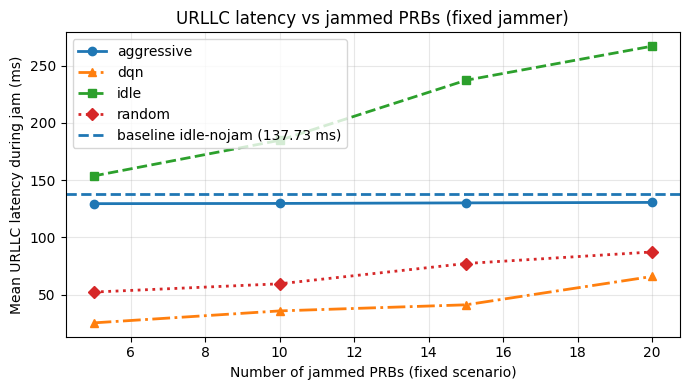

In [6]:
plt.figure(figsize=(7, 4))

for policy, g in df_lat.groupby("policy"):
    g = g.sort_values("jam_prb")
    st = STYLE.get(policy, DEFAULT_STYLE)
    plt.plot(
        g["jam_prb"], g["mean_latency_ms"],
        label=policy,
        linewidth=2,
        markersize=6,
        **st
    )

# baseline horizontal line
if np.isfinite(baseline_lat_ms):
    plt.axhline(
        baseline_lat_ms,
        linestyle="--",
        linewidth=2,
        label=f"baseline idle-nojam ({baseline_lat_ms:.2f} ms)"
    )

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean URLLC latency during jam (ms)")
plt.title("URLLC latency vs jammed PRBs (fixed jammer)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


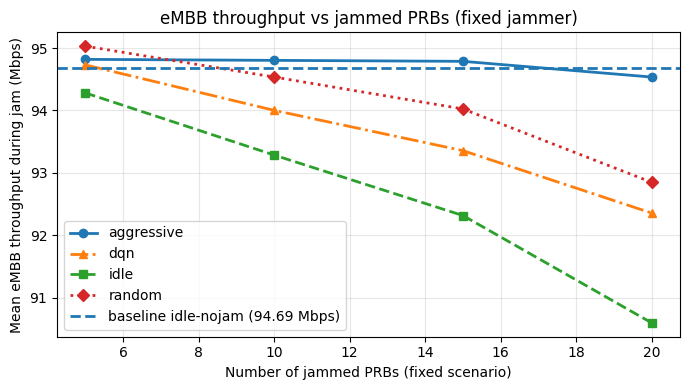

In [7]:
plt.figure(figsize=(7, 4))

for policy, g in df_thr.groupby("policy"):
    g = g.sort_values("jam_prb")
    st = STYLE.get(policy, DEFAULT_STYLE)
    plt.plot(
        g["jam_prb"], g["mean_embb_mbps"],
        label=policy,
        linewidth=2,
        markersize=6,
        **st
    )

if np.isfinite(baseline_thr_mbps):
    plt.axhline(
        baseline_thr_mbps,
        linestyle="--",
        linewidth=2,
        label=f"baseline idle-nojam ({baseline_thr_mbps:.2f} Mbps)"
    )

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean eMBB throughput during jam (Mbps)")
plt.title("eMBB throughput vs jammed PRBs (fixed jammer)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


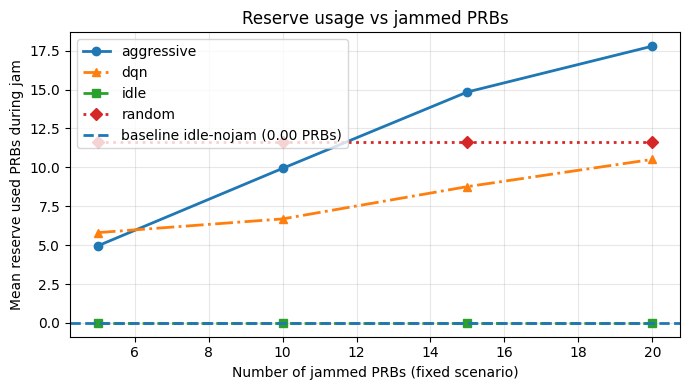

In [8]:
plt.figure(figsize=(7, 4))

for policy, g in df_prb.groupby("policy"):
    g = g.sort_values("jam_prb")
    st = STYLE.get(policy, DEFAULT_STYLE)
    plt.plot(
        g["jam_prb"], g["reserve_used_prb_mean"],
        label=policy,
        linewidth=2,
        markersize=6,
        **st
    )

if np.isfinite(baseline_rsv_prb):
    plt.axhline(
        baseline_rsv_prb,
        linestyle="--",
        linewidth=2,
        label=f"baseline idle-nojam ({baseline_rsv_prb:.2f} PRBs)"
    )

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean reserve used PRBs during jam")
plt.title("Reserve usage vs jammed PRBs")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [9]:
EPS = 1e-9

def mean_scalar(event_file: Path, tag: str, scale: float = 1.0) -> float:
    df = read_scalar_from_event(event_file, tag)
    if df.empty:
        return np.nan
    return float(df["value"].mean() * scale)

def find_event_file_direct(dir_with_events: Path) -> Path | None:
    if not dir_with_events.exists():
        return None
    candidates = list(dir_with_events.glob("events.out.tfevents.*"))
    if not candidates:
        return None
    candidates.sort(key=lambda p: p.stat().st_size, reverse=True)
    return candidates[0]


In [10]:
eff_rows = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    for pwr in POWERS:
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_fixed_{pwr}"
        ev_file = find_event_file(policy_dir, test_name)

        if ev_file is None:
            print(f"[MISS] {policy:10s} pwr={pwr} -> event file NOT found at {policy_dir/test_name}")
            eff_rows.append({
                "policy": policy, "jam_prb": pwr,
                "thr_mbps": np.nan, "prb_used": np.nan, "lat_ms": np.nan,
                "thr_per_prb": np.nan, "invlat_per_prb": np.nan,
                "event_file": None
            })
            continue

        m_lat = mean_latency_during_jam(ev_file)              # ms
        m_thr = mean_embb_throughput_during_jam(ev_file)      # Mbps
        m_prb = mean_reserve_used_prb_during_jam(ev_file)     # PRBs

        # efficiency (raw; may be inf/nan if prb_used ~ 0)
        thr_per_prb = m_thr / m_prb if (np.isfinite(m_thr) and np.isfinite(m_prb) and m_prb > 0) else np.nan
        invlat_per_prb = (1.0 / m_lat) / m_prb if (np.isfinite(m_lat) and m_lat > 0 and np.isfinite(m_prb) and m_prb > 0) else np.nan

        eff_rows.append({
            "policy": policy, "jam_prb": pwr,
            "thr_mbps": m_thr, "prb_used": m_prb, "lat_ms": m_lat,
            "thr_per_prb": thr_per_prb,
            "invlat_per_prb": invlat_per_prb,
            "event_file": str(ev_file)
        })

df_eff = pd.DataFrame(eff_rows)

print("\nCounts per policy:")
print(df_eff.groupby("policy")["jam_prb"].count())

print("\nHow many event files were found per policy?")
print(df_eff["event_file"].notna().groupby(df_eff["policy"]).sum())

print("\nPreview:")
print(df_eff.head(20))


lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950

Counts per policy:
policy
aggressive    4
dqn           4
idle          4
random        4
Name: jam_prb, dtype: int64

How many event files were found per policy?
policy
aggressive    4
dqn           4
idle          4
random        4
Name: event_file, dtype: int64

Preview:
        policy  jam_prb   thr_mbps   prb_used      lat_ms  thr_per_prb  \
0   aggressive        5  94.818603   4.951904  129.402536    19.147909   
1   aggressive       10  94.802386   9.935872  129.595947     9.541426   
2   aggressive       15  94.786921  14.847695  130.083542     6.383948   
3   aggressive       20  94.534907  17.791583  130.489663   

In [11]:
# ---- General baseline folder (directly under ROOT) ----
GENERAL_BASELINE_DIRNAME = "idle__20260120_092923__res18_off0_const0_per2500_dur1250"
general_baseline_dir = ROOT / GENERAL_BASELINE_DIRNAME
general_baseline_ev = find_event_file_direct(general_baseline_dir)

print("general_baseline_ev =", general_baseline_ev)

base_thr = np.nan
base_lat_ms = np.nan
base_prb = np.nan

base_thr_per_prb = np.nan
base_invlat_per_prb = np.nan

if general_baseline_ev is not None:
    base_thr    = mean_scalar(general_baseline_ev, "throughput/embb_mbps", scale=1.0)
    base_lat_ms = mean_scalar(general_baseline_ev, "latency/urllc", scale=1000.0)  # sec->ms
    base_prb    = mean_scalar(general_baseline_ev, "obs/reserve_used_prb", scale=1.0)

    # efficiencies (safe divide)
    if np.isfinite(base_thr) and np.isfinite(base_prb) and base_prb > EPS:
        base_thr_per_prb = base_thr / base_prb
    else:
        print(f"[WARN] baseline thr/prb not finite (thr={base_thr}, prb={base_prb}).")

    if np.isfinite(base_lat_ms) and base_lat_ms > EPS and np.isfinite(base_prb) and base_prb > EPS:
        base_invlat_per_prb = (1.0 / base_lat_ms) / base_prb  # 1/ms/PRB
    else:
        print(f"[WARN] baseline (1/lat)/prb not finite (lat_ms={base_lat_ms}, prb={base_prb}).")

print("baseline: thr=", base_thr, "lat_ms=", base_lat_ms, "prb=", base_prb)
print("baseline eff: thr_per_prb=", base_thr_per_prb, "invlat_per_prb=", base_invlat_per_prb)


general_baseline_ev = ../../tb_logs/res_validator/idle__20260120_092923__res18_off0_const0_per2500_dur1250/events.out.tfevents.1768919363.elahe-LEGION-T7-34IAS10.985059.0
[WARN] baseline thr/prb not finite (thr=94.6875671432541, prb=0.0).
[WARN] baseline (1/lat)/prb not finite (lat_ms=137.73330748807837, prb=0.0).
baseline: thr= 94.6875671432541 lat_ms= 137.73330748807837 prb= 0.0
baseline eff: thr_per_prb= nan invlat_per_prb= nan


In [12]:
def plot_eff(df_eff: pd.DataFrame, ycol: str, ylabel: str, title: str,
             baseline_y: float | None = None, baseline_label: str = "baseline"):
    plt.figure(figsize=(7, 4))
    for policy, g in df_eff.groupby("policy"):
        g = g.sort_values("jam_prb")
        st = STYLE.get(policy, dict(linestyle="-", marker="o"))
        plt.plot(
            g["jam_prb"], g[ycol],
            label=policy,
            linewidth=2,
            markersize=6,
            **st
        )

    if baseline_y is not None and np.isfinite(baseline_y):
        plt.axhline(
            baseline_y,
            linestyle="--",
            linewidth=2,
            color="black",
            alpha=0.7,
            label=baseline_label
        )
    elif baseline_y is not None:
        print(f"[WARN] Not plotting {baseline_label}: baseline value is NaN/inf.")

    plt.xlabel("Number of jammed PRBs (fixed scenario)")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


[WARN] Not plotting general baseline: baseline value is NaN/inf.


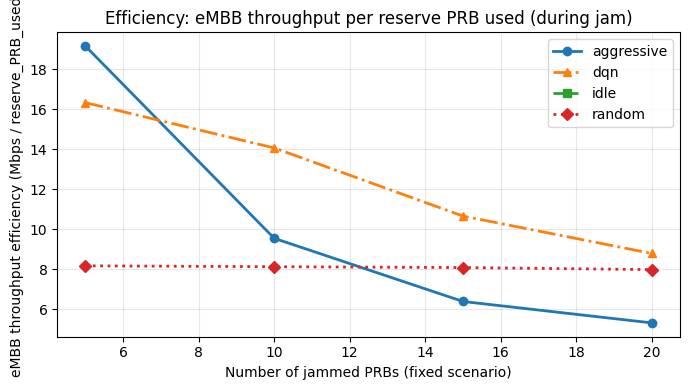

[WARN] Not plotting general baseline: baseline value is NaN/inf.


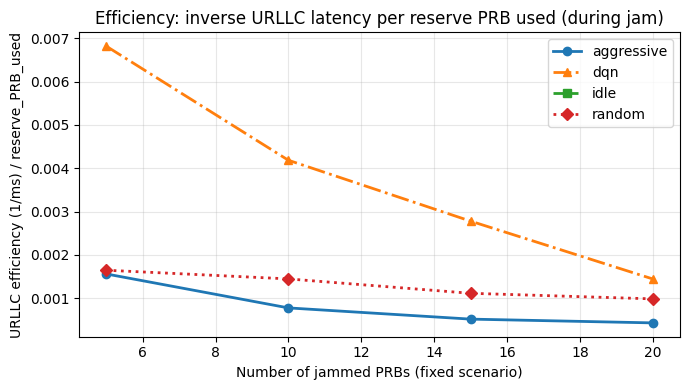

In [13]:
plot_eff(
    df_eff,
    ycol="thr_per_prb",
    ylabel="eMBB throughput efficiency (Mbps / reserve_PRB_used)",
    title="Efficiency: eMBB throughput per reserve PRB used (during jam)",
    baseline_y=base_thr_per_prb,
    baseline_label=f"general baseline ({base_thr_per_prb:.3f} Mbps/PRB)" if np.isfinite(base_thr_per_prb) else "general baseline"
)

plot_eff(
    df_eff,
    ycol="invlat_per_prb",
    ylabel="URLLC efficiency (1/ms) / reserve_PRB_used",
    title="Efficiency: inverse URLLC latency per reserve PRB used (during jam)",
    baseline_y=base_invlat_per_prb,
    baseline_label=f"general baseline ({base_invlat_per_prb:.6f} 1/ms/PRB)" if np.isfinite(base_invlat_per_prb) else "general baseline"
)


In [14]:
print(df_eff[["policy", "jam_prb", "thr_mbps", "prb_used", "thr_per_prb"]])


        policy  jam_prb   thr_mbps   prb_used  thr_per_prb
0   aggressive        5  94.818603   4.951904    19.147909
1   aggressive       10  94.802386   9.935872     9.541426
2   aggressive       15  94.786921  14.847695     6.383948
3   aggressive       20  94.534907  17.791583     5.313462
4         idle        5  94.280645   0.000000          NaN
5         idle       10  93.284532   0.000000          NaN
6         idle       15  92.315348   0.000000          NaN
7         idle       20  90.594324   0.000000          NaN
8          dqn        5  94.729615   5.803848    16.321864
9          dqn       10  94.001308   6.685491    14.060494
10         dqn       15  93.355165   8.762164    10.654350
11         dqn       20  92.354689  10.511543     8.786026
12      random        5  95.029930  11.638076     8.165433
13      random       10  94.535195  11.638076     8.122923
14      random       15  94.023732  11.638076     8.078975
15      random       20  92.847678  11.638076     7.9779

Total jam cycles: 1612


,policy,power,run_id,jam_idx,jam_start_step,jam_end_step,baseline_X,endjam_Y,degradation,rel_degradation,recovered,t_recovery_steps,recovery_step,recovery_value,best_off_value,threshold
0,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,2500,3740,0.000040,0.000021,-0.000019,-0.484742,True,40.0,3780.0,0.000003,0.000000,0.000042
1,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,2,5000,6240,0.000040,0.000021,-0.000019,-0.484742,True,40.0,6280.0,0.000003,0.000000,0.000042
2,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,3,7500,8740,0.000040,0.000021,-0.000019,-0.484742,True,40.0,8780.0,0.000003,0.000000,0.000042
3,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,4,10010,11240,0.000040,0.000000,-0.000040,-1.000000,True,10.0,11250.0,0.000000,0.000000,0.000042
4,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,13,32500,33740,0.000042,0.000115,0.000072,1.720761,True,90.0,33830.0,0.000042,0.000000,0.000044
5,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,14,35000,36240,0.000042,0.000115,0.000072,1.720761,True,90.0,36330.0,0.000042,0.000000,0.000044
6,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,15,37500,38740,0.000042,0.000115,0.000072,1.720761,True,90.0,38830.0,0.000042,0.000000,0.000044
7,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,16,40010,41240,0.000042,0.041971,0.041929,995.971831,False,inf,NaN,NaN,0.042163,0.000044
8,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,17,42500,43740,0.082080,0.126275,0.044195,0.538439,False,inf,NaN,NaN,0.126069,0.086184
9,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,18,45000,46240,0.164317,0.210550,0.046234,0.281370,False,inf,NaN,NaN,0.209847,0.172533


,policy,power,n_cycles,recovery_rate,median_t_rec,mean_t_rec,median_rel_deg
0,aggressive,5,123,0.487805,30.0,38.833333,0.279451
1,aggressive,10,123,0.487805,10.0,51.166667,0.282874
2,aggressive,15,123,0.487805,10.0,53.166667,0.285065
3,aggressive,20,123,0.512195,20.0,59.841270,0.287588
4,dqn,5,90,0.755556,20.0,110.735294,0.226834
5,dqn,10,89,0.719101,10.0,103.281250,0.228406
6,dqn,15,85,0.682353,15.0,129.827586,0.418092
7,dqn,20,88,0.590909,30.0,242.884615,0.689077
8,idle,5,123,0.406504,20.0,81.600000,0.391030
9,idle,10,123,0.341463,10.0,188.333333,0.458245


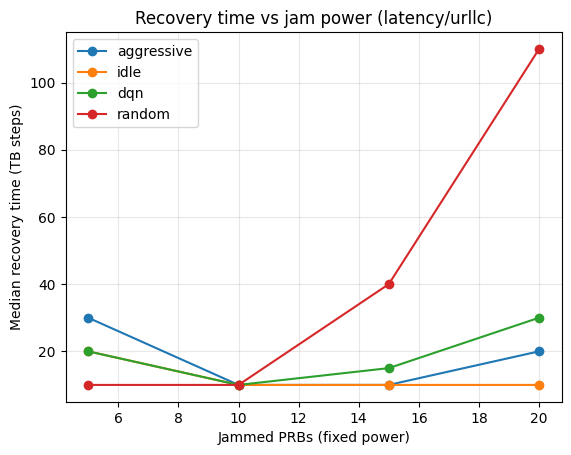

In [24]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

# =========================
# USER CONFIG
# =========================
ROOT = Path("../../tb_logs/res_validator")   # .../backend/tb_logs/res_validator
POLICIES = ["aggressive", "idle", "dqn", "random"]
POWERS = [5, 10, 15, 20]

METRIC_TAG = "latency/urllc"                # or "throughput/embb_mbps"
JAM_TAG = "prb/effective_ratio"

JAM_THRESHOLD = 0.999

W_PRE = 2
W_END = 2
K_CONSEC = 3
EPS = 0.05

LOWER_IS_BETTER = True   # True for latency, False for throughput


# =========================
# TB reader
# =========================
def read_tb_scalar(event_file: Path, tags):
    tags = set(tags)
    out = {t: [] for t in tags}
    for rec in tf_record.tf_record_iterator(str(event_file)):
        e = Event.FromString(rec)
        if not e.summary.value:
            continue
        step = int(e.step)
        for v in e.summary.value:
            if v.tag in tags:
                out[v.tag].append((step, float(v.simple_value)))

    dfs = {}
    for t, rows in out.items():
        if not rows:
            dfs[t] = pd.DataFrame(columns=["step", "value"])
        else:
            df = pd.DataFrame(rows, columns=["step", "value"]).dropna()
            df = df.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
            dfs[t] = df
    return dfs


# =========================
# Jam segmentation + recovery
# =========================
def segment_bool_runs(is_true: np.ndarray):
    if len(is_true) == 0:
        return []
    x = is_true.astype(np.int8)
    d = np.diff(x, prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends = np.where(d == -1)[0]
    return list(zip(starts, ends))

def first_k_consecutive_true(mask: np.ndarray, k: int):
    if k <= 1:
        idx = np.where(mask)[0]
        return int(idx[0]) if len(idx) else None
    if len(mask) < k:
        return None
    s = np.convolve(mask.astype(np.int32), np.ones(k, dtype=np.int32), mode="valid")
    hits = np.where(s == k)[0]
    return int(hits[0]) if len(hits) else None


def compute_recovery_for_run(df_metric, df_jam, policy, power, run_id):
    if df_metric.empty or df_jam.empty:
        return pd.DataFrame()

    # Align by step
    df = df_metric.rename(columns={"value": "metric"}).merge(
        df_jam.rename(columns={"value": "eff"}),
        on="step", how="inner"
    ).sort_values("step").reset_index(drop=True)

    if df.empty:
        return pd.DataFrame()

    steps = df["step"].to_numpy()
    metric = df["metric"].to_numpy()
    is_jam = df["eff"].to_numpy() < JAM_THRESHOLD
    jam_runs = segment_bool_runs(is_jam)

    rows = []
    for j, (s_idx, e_idx) in enumerate(jam_runs):
        # baseline before jam
        pre_start = max(0, s_idx - W_PRE)
        pre_end = s_idx
        pre_slice = metric[pre_start:pre_end]
        if len(pre_slice) == 0:
            continue
        X = np.nanmedian(pre_slice)
        if np.isnan(X) or X == 0:
            continue

        # end-of-jam value
        if e_idx <= s_idx:
            continue
        end_start = max(s_idx, e_idx - W_END)
        Y = np.nanmedian(metric[end_start:e_idx])

        # off window until next jam
        next_start = jam_runs[j + 1][0] if (j + 1) < len(jam_runs) else len(df)
        off_start = e_idx
        off_end = next_start
        off_slice = metric[off_start:off_end]

        if LOWER_IS_BETTER:
            thresh = (1.0 + EPS) * X
            cond = off_slice <= thresh
            best_val = np.nanmin(off_slice) if len(off_slice) else np.nan
        else:
            thresh = (1.0 - EPS) * X
            cond = off_slice >= thresh
            best_val = np.nanmax(off_slice) if len(off_slice) else np.nan

        rec_offset = first_k_consecutive_true(cond, K_CONSEC)

        if rec_offset is None:
            recovered = False
            t_rec = np.inf
            rec_val = np.nan
            rec_step = np.nan
        else:
            recovered = True
            rec_idx = off_start + rec_offset
            rec_step = steps[rec_idx]
            rec_val = metric[rec_idx]
            t_rec = rec_step - steps[e_idx - 1]  # measured from last jam sample

        # degradation (sign-aware)
        if LOWER_IS_BETTER:
            degradation = Y - X
            rel_deg = (Y - X) / (X + 1e-12)
        else:
            degradation = X - Y
            rel_deg = (X - Y) / (X + 1e-12)

        rows.append({
            "policy": policy,
            "power": power,
            "run_id": run_id,
            "jam_idx": j,
            "jam_start_step": steps[s_idx],
            "jam_end_step": steps[e_idx - 1],
            "baseline_X": X,
            "endjam_Y": Y,
            "degradation": degradation,
            "rel_degradation": rel_deg,
            "recovered": recovered,
            "t_recovery_steps": t_rec,
            "recovery_step": rec_step,
            "recovery_value": rec_val,
            "best_off_value": best_val,
            "threshold": thresh,
        })

    return pd.DataFrame(rows)


# =========================
# IMPORTANT: nested event file finder
# =========================
def find_event_file_under_test_folder(test_folder: Path):
    """
    test_folder is like:
      .../dqn/gym_from_testing_config_..._jam_fixed_5

    Inside it, there is one run subfolder (name can differ),
    and inside that the events.out.tfevents.* exists.
    We choose the newest event file found under this test_folder.
    """
    evs = sorted(test_folder.rglob("events.out.tfevents.*"))
    if not evs:
        return None
    # pick the largest/newest; usually only one
    evs = sorted(evs, key=lambda p: (p.stat().st_mtime, p.stat().st_size))
    return evs[-1]


# =========================
# Main loop: policy x fixed power
# =========================
all_cycles = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    if not policy_dir.exists():
        print(f"[WARN] policy folder missing: {policy_dir}")
        continue

    for pwr in POWERS:
        # find the test folder (exact match or fallback)
        test_name_suffix = f"_jam_fixed_{pwr}"
        matches = sorted([p for p in policy_dir.iterdir()
                          if p.is_dir() and p.name.endswith(test_name_suffix)])

        if not matches:
            print(f"[WARN] missing test folder for {policy} power={pwr}")
            continue

        test_folder = matches[0]  # should be exactly one
        ev = find_event_file_under_test_folder(test_folder)
        if ev is None:
            print(f"[WARN] no event file found under {test_folder}")
            continue

        dfs = read_tb_scalar(ev, tags=[METRIC_TAG, JAM_TAG])
        df_cycles = compute_recovery_for_run(
            dfs[METRIC_TAG], dfs[JAM_TAG],
            policy=policy, power=pwr, run_id=str(test_folder)
        )
        if not df_cycles.empty:
            all_cycles.append(df_cycles)

df_cycles_all = pd.concat(all_cycles, ignore_index=True) if all_cycles else pd.DataFrame()
print("Total jam cycles:", len(df_cycles_all))
display(df_cycles_all.head(10))


# =========================
# Aggregate per policy x power
# =========================
if not df_cycles_all.empty:
    tmp = df_cycles_all.copy()
    tmp["t_rec_clean"] = tmp["t_recovery_steps"].replace([np.inf, -np.inf], np.nan)

    df_agg = (
        tmp.groupby(["policy", "power"])
           .agg(
               n_cycles=("jam_idx", "count"),
               recovery_rate=("recovered", "mean"),
               median_t_rec=("t_rec_clean", "median"),
               mean_t_rec=("t_rec_clean", "mean"),
               median_rel_deg=("rel_degradation", "median"),
           )
           .reset_index()
           .sort_values(["policy", "power"])
    )
    display(df_agg)

    # plot: median recovery time vs power
    plt.figure()
    for policy in POLICIES:
        sub = df_agg[df_agg["policy"] == policy].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_t_rec"], marker="o", label=policy)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median recovery time (TB steps)")
    plt.title(f"Recovery time vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


In [25]:
df_cycles_all.groupby(["policy","power"])["rel_degradation"].median()


policy      power
aggressive  5        0.279451
            10       0.282874
            15       0.285065
            20       0.287588
dqn         5        0.226834
            10       0.228406
            15       0.418092
            20       0.689077
idle        5        0.391030
            10       0.458245
            15       0.399721
            20       0.371501
random      5        0.255295
            10       0.348547
            15       0.647443
            20       0.685313
Name: rel_degradation, dtype: float64

In [16]:
df_cycles_all.groupby(["policy","power"])["jam_idx"].count()
df_cycles_all["jam_len_steps"] = df_cycles_all["jam_end_step"] - df_cycles_all["jam_start_step"]
df_cycles_all.groupby(["policy","power"])["jam_len_steps"].median()


policy      power
aggressive  5        1240.0
            10       1240.0
            15       1240.0
            20       1240.0
dqn         5        1240.0
            10       1240.0
            15       1240.0
            20       1240.0
idle        5        1240.0
            10       1240.0
            15       1240.0
            20       1240.0
random      5        1240.0
            10       1240.0
            15       1240.0
            20       1240.0
Name: jam_len_steps, dtype: float64

Total jam cycles: 3184


,policy,power,run_id,jam_idx,jam_start_step,jam_end_step,baseline_X,endjam_Y,degradation,rel_degradation,recovered,t_recovery_steps,recovery_step,recovery_value,best_off_value,threshold
0,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,2500,3740,96.0,96.0,0.0,0.0,True,10.0,3750.0,96.0,96.0,86.4
1,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,2,5000,6240,96.0,96.0,0.0,0.0,True,10.0,6250.0,96.0,96.0,86.4
2,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,3,7500,8740,96.0,96.0,0.0,0.0,True,10.0,8750.0,96.0,96.0,86.4
3,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,4,10010,11240,96.0,96.0,0.0,0.0,True,10.0,11250.0,96.0,96.0,86.4
4,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,5,12500,13740,96.0,96.0,0.0,0.0,True,10.0,13750.0,96.0,96.0,86.4
5,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,6,15000,16240,96.0,96.0,0.0,0.0,True,10.0,16250.0,96.0,96.0,86.4
6,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,7,17500,18740,96.0,96.0,0.0,0.0,True,10.0,18750.0,96.0,96.0,86.4
7,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,8,20010,21240,96.0,96.0,0.0,0.0,True,10.0,21250.0,96.0,96.0,86.4
8,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,9,22500,23740,96.0,96.0,0.0,0.0,True,10.0,23750.0,96.0,96.0,86.4
9,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,10,25000,26240,96.0,96.0,0.0,0.0,True,10.0,26250.0,96.0,96.0,86.4


,policy,power,n_cycles,recovery_rate,median_t_rec,mean_t_rec,median_rel_deg
0,aggressive,5,199,0.994975,10.0,10.000000,0.000000
1,aggressive,10,199,1.000000,10.0,10.000000,0.000000
2,aggressive,15,199,1.000000,10.0,10.000000,0.000000
3,aggressive,20,199,0.994975,10.0,10.000000,0.000000
4,dqn,5,199,1.000000,10.0,10.301508,0.000000
5,dqn,10,199,1.000000,10.0,10.201005,0.000000
6,dqn,15,199,1.000000,10.0,10.000000,0.000000
7,dqn,20,199,1.000000,10.0,10.402010,0.013042
8,idle,5,199,0.989950,10.0,10.000000,0.000000
9,idle,10,199,0.989950,10.0,10.000000,0.000000


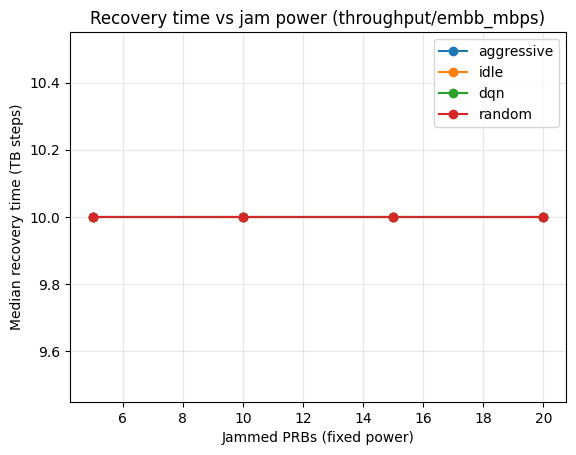

In [22]:
# =========================
# USER CONFIG
# =========================
ROOT = Path("../../tb_logs/res_validator")   # .../backend/tb_logs/res_validator
POLICIES = ["aggressive", "idle", "dqn", "random"]
POWERS = [5, 10, 15, 20]

JAM_TAG = "prb/effective_ratio"

JAM_THRESHOLD = 0.999

W_PRE = 10
W_END = 10
K_CONSEC = 3
EPS = 0.10


METRIC_TAG = "throughput/embb_mbps"
LOWER_IS_BETTER = False
# =========================
# TB reader
# =========================
def read_tb_scalar(event_file: Path, tags):
    tags = set(tags)
    out = {t: [] for t in tags}
    for rec in tf_record.tf_record_iterator(str(event_file)):
        e = Event.FromString(rec)
        if not e.summary.value:
            continue
        step = int(e.step)
        for v in e.summary.value:
            if v.tag in tags:
                out[v.tag].append((step, float(v.simple_value)))

    dfs = {}
    for t, rows in out.items():
        if not rows:
            dfs[t] = pd.DataFrame(columns=["step", "value"])
        else:
            df = pd.DataFrame(rows, columns=["step", "value"]).dropna()
            df = df.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
            dfs[t] = df
    return dfs


# =========================
# Jam segmentation + recovery
# =========================
def segment_bool_runs(is_true: np.ndarray):
    if len(is_true) == 0:
        return []
    x = is_true.astype(np.int8)
    d = np.diff(x, prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends = np.where(d == -1)[0]
    return list(zip(starts, ends))

def first_k_consecutive_true(mask: np.ndarray, k: int):
    if k <= 1:
        idx = np.where(mask)[0]
        return int(idx[0]) if len(idx) else None
    if len(mask) < k:
        return None
    s = np.convolve(mask.astype(np.int32), np.ones(k, dtype=np.int32), mode="valid")
    hits = np.where(s == k)[0]
    return int(hits[0]) if len(hits) else None


def compute_recovery_for_run(df_metric, df_jam, policy, power, run_id):
    if df_metric.empty or df_jam.empty:
        return pd.DataFrame()

    # Align by step
    df = df_metric.rename(columns={"value": "metric"}).merge(
        df_jam.rename(columns={"value": "eff"}),
        on="step", how="inner"
    ).sort_values("step").reset_index(drop=True)

    if df.empty:
        return pd.DataFrame()

    steps = df["step"].to_numpy()
    metric = df["metric"].to_numpy()
    is_jam = df["eff"].to_numpy() < JAM_THRESHOLD
    jam_runs = segment_bool_runs(is_jam)

    rows = []
    for j, (s_idx, e_idx) in enumerate(jam_runs):
        # baseline before jam
        pre_start = max(0, s_idx - W_PRE)
        pre_end = s_idx
        pre_slice = metric[pre_start:pre_end]
        if len(pre_slice) == 0:
            continue
        X = np.nanmedian(pre_slice)
        if np.isnan(X) or X == 0:
            continue

        # end-of-jam value
        if e_idx <= s_idx:
            continue
        end_start = max(s_idx, e_idx - W_END)
        Y = np.nanmedian(metric[end_start:e_idx])

        # off window until next jam
        next_start = jam_runs[j + 1][0] if (j + 1) < len(jam_runs) else len(df)
        off_start = e_idx
        off_end = next_start
        off_slice = metric[off_start:off_end]

        if LOWER_IS_BETTER:
            thresh = (1.0 + EPS) * X
            cond = off_slice <= thresh
            best_val = np.nanmin(off_slice) if len(off_slice) else np.nan
        else:
            thresh = (1.0 - EPS) * X
            cond = off_slice >= thresh
            best_val = np.nanmax(off_slice) if len(off_slice) else np.nan

        rec_offset = first_k_consecutive_true(cond, K_CONSEC)

        if rec_offset is None:
            recovered = False
            t_rec = np.inf
            rec_val = np.nan
            rec_step = np.nan
        else:
            recovered = True
            rec_idx = off_start + rec_offset
            rec_step = steps[rec_idx]
            rec_val = metric[rec_idx]
            t_rec = rec_step - steps[e_idx - 1]  # measured from last jam sample

        # degradation (sign-aware)
        if LOWER_IS_BETTER:
            degradation = Y - X
            rel_deg = (Y - X) / (X + 1e-12)
        else:
            degradation = X - Y
            rel_deg = (X - Y) / (X + 1e-12)

        rows.append({
            "policy": policy,
            "power": power,
            "run_id": run_id,
            "jam_idx": j,
            "jam_start_step": steps[s_idx],
            "jam_end_step": steps[e_idx - 1],
            "baseline_X": X,
            "endjam_Y": Y,
            "degradation": degradation,
            "rel_degradation": rel_deg,
            "recovered": recovered,
            "t_recovery_steps": t_rec,
            "recovery_step": rec_step,
            "recovery_value": rec_val,
            "best_off_value": best_val,
            "threshold": thresh,
        })

    return pd.DataFrame(rows)


# =========================
# IMPORTANT: nested event file finder
# =========================
def find_event_file_under_test_folder(test_folder: Path):
    """
    test_folder is like:
      .../dqn/gym_from_testing_config_..._jam_fixed_5

    Inside it, there is one run subfolder (name can differ),
    and inside that the events.out.tfevents.* exists.
    We choose the newest event file found under this test_folder.
    """
    evs = sorted(test_folder.rglob("events.out.tfevents.*"))
    if not evs:
        return None
    # pick the largest/newest; usually only one
    evs = sorted(evs, key=lambda p: (p.stat().st_mtime, p.stat().st_size))
    return evs[-1]


# =========================
# Main loop: policy x fixed power
# =========================
all_cycles = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    if not policy_dir.exists():
        print(f"[WARN] policy folder missing: {policy_dir}")
        continue

    for pwr in POWERS:
        # find the test folder (exact match or fallback)
        test_name_suffix = f"_jam_fixed_{pwr}"
        matches = sorted([p for p in policy_dir.iterdir()
                          if p.is_dir() and p.name.endswith(test_name_suffix)])

        if not matches:
            print(f"[WARN] missing test folder for {policy} power={pwr}")
            continue

        test_folder = matches[0]  # should be exactly one
        ev = find_event_file_under_test_folder(test_folder)
        if ev is None:
            print(f"[WARN] no event file found under {test_folder}")
            continue

        dfs = read_tb_scalar(ev, tags=[METRIC_TAG, JAM_TAG])
        df_cycles = compute_recovery_for_run(
            dfs[METRIC_TAG], dfs[JAM_TAG],
            policy=policy, power=pwr, run_id=str(test_folder)
        )
        if not df_cycles.empty:
            all_cycles.append(df_cycles)

df_cycles_all = pd.concat(all_cycles, ignore_index=True) if all_cycles else pd.DataFrame()
print("Total jam cycles:", len(df_cycles_all))
display(df_cycles_all.head(10))


# =========================
# Aggregate per policy x power
# =========================
if not df_cycles_all.empty:
    tmp = df_cycles_all.copy()
    tmp["t_rec_clean"] = tmp["t_recovery_steps"].replace([np.inf, -np.inf], np.nan)

    df_agg = (
        tmp.groupby(["policy", "power"])
           .agg(
               n_cycles=("jam_idx", "count"),
               recovery_rate=("recovered", "mean"),
               median_t_rec=("t_rec_clean", "median"),
               mean_t_rec=("t_rec_clean", "mean"),
               median_rel_deg=("rel_degradation", "median"),
           )
           .reset_index()
           .sort_values(["policy", "power"])
    )
    display(df_agg)

    # plot: median recovery time vs power
    plt.figure()
    for policy in POLICIES:
        sub = df_agg[df_agg["policy"] == policy].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_t_rec"], marker="o", label=policy)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median recovery time (TB steps)")
    plt.title(f"Recovery time vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


Total jam cycles: 1926


,policy,power,run_id,episode_idx,jam_idx_in_episode,jam_start_step,jam_end_step,baseline_X,endjam_Y,degradation,rel_degradation,recovered,t_recovery_sim_steps,recovery_step,recovery_value,best_off_value,threshold,n_jams_in_episode
0,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,0,10.0,1240.0,0.000160,0.000023,-0.000137,-0.857908,True,10.0,1250.0,0.000018,0.000000,0.000168,4
1,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,1,2500.0,3740.0,0.000040,0.000021,-0.000019,-0.484742,True,40.0,3780.0,0.000003,0.000000,0.000042,4
2,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,2,5000.0,6240.0,0.000040,0.000021,-0.000019,-0.484742,True,40.0,6280.0,0.000003,0.000000,0.000042,4
3,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,3,7500.0,8740.0,0.000040,0.000021,-0.000019,-0.484742,True,40.0,8780.0,0.000003,0.000000,0.000042,4
4,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,0,10010.0,11240.0,0.000001,0.000000,-0.000001,-0.999999,True,10.0,11250.0,0.000000,0.000000,0.000001,4
5,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,3,0,30010.0,31240.0,0.000129,0.000109,-0.000020,-0.153300,True,10.0,31250.0,0.000112,0.000000,0.000135,4
6,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,3,1,32500.0,33740.0,0.000042,0.000115,0.000072,1.720761,True,90.0,33830.0,0.000042,0.000000,0.000044,4
7,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,3,2,35000.0,36240.0,0.000042,0.000115,0.000072,1.720761,True,90.0,36330.0,0.000042,0.000000,0.000044,4
8,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,3,3,37500.0,38740.0,0.000042,0.000115,0.000072,1.720761,True,90.0,38830.0,0.000042,0.000000,0.000044,4
9,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,4,0,40010.0,41240.0,0.000502,0.041971,0.041469,82.579857,False,inf,NaN,NaN,0.042163,0.000527,4


Episodes detected per (policy,power):


policy      power
aggressive  5        38
            10       44
            15       47
            20       48
dqn         5        38
            10       44
            15       47
            20       48
idle        5        38
            10       44
            15       47
            20       48
random      5        38
            10       44
            15       47
            20       48
Name: episode_idx, dtype: int64

Jam runs per episode (should be ~4):


n_jams_in_episode
4    708
Name: count, dtype: int64

,policy,power,n_cycles,n_episodes,recovery_rate,median_t_rec,mean_t_rec,median_rel_deg
0,aggressive,5,131,38,0.419847,40.0,49.454545,0.511944
1,aggressive,10,137,44,0.445255,20.0,53.934426,0.513862
2,aggressive,15,140,47,0.457143,10.0,53.750000,0.513405
3,aggressive,20,141,48,0.482270,20.0,59.264706,0.510372
4,dqn,5,106,38,0.698113,20.0,117.297297,0.513689
5,dqn,10,112,44,0.687500,10.0,107.922078,0.575539
6,dqn,15,113,47,0.672566,10.0,122.631579,0.561405
7,dqn,20,116,48,0.577586,20.0,228.805970,1.380515
8,idle,5,131,38,0.320611,40.0,123.809524,0.707778
9,idle,10,137,44,0.262774,50.0,312.500000,0.832329


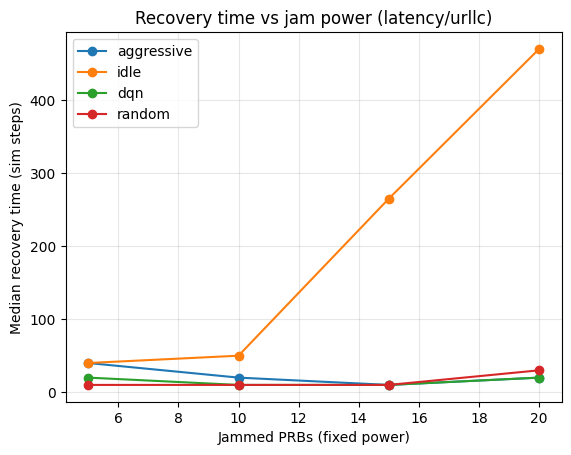

In [26]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

# =========================
# USER CONFIG
# =========================
ROOT = Path("../../tb_logs/res_validator")   # .../backend/tb_logs/res_validator
POLICIES = ["aggressive", "idle", "dqn", "random"]
POWERS = [5, 10, 15, 20]

METRIC_TAG = "latency/urllc"                # or "throughput/embb_mbps"
JAM_TAG = "prb/effective_ratio"

# TB step is SIMULATOR STEP in your setup
EP_LEN_SIM = 10000                          # 10000 sim steps per episode

# Jam detection
JAM_THRESHOLD = 0.999

# Baseline windows (in SIM steps; you chose 2,2 which is very "local")
W_PRE = 2
W_END = 2

# Recovery stability + tolerance
K_CONSEC = 3
EPS = 0.05

LOWER_IS_BETTER = True   # True for latency, False for throughput


# =========================
# TB reader
# =========================
def read_tb_scalar(event_file: Path, tags):
    tags = set(tags)
    out = {t: [] for t in tags}
    for rec in tf_record.tf_record_iterator(str(event_file)):
        e = Event.FromString(rec)
        if not e.summary.value:
            continue
        step = int(e.step)
        for v in e.summary.value:
            if v.tag in tags:
                out[v.tag].append((step, float(v.simple_value)))

    dfs = {}
    for t, rows in out.items():
        if not rows:
            dfs[t] = pd.DataFrame(columns=["step", "value"])
        else:
            df = pd.DataFrame(rows, columns=["step", "value"]).dropna()
            df = df.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
            dfs[t] = df
    return dfs


# =========================
# Jam segmentation + recovery helpers
# =========================
def segment_bool_runs(is_true: np.ndarray):
    """Return list of (start_idx, end_idx_exclusive) for True-runs."""
    if len(is_true) == 0:
        return []
    x = is_true.astype(np.int8)
    d = np.diff(x, prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends = np.where(d == -1)[0]
    return list(zip(starts, ends))

def first_k_consecutive_true(mask: np.ndarray, k: int):
    """First index i such that mask[i:i+k] are all True. None if not found."""
    if k <= 1:
        idx = np.where(mask)[0]
        return int(idx[0]) if len(idx) else None
    if len(mask) < k:
        return None
    s = np.convolve(mask.astype(np.int32), np.ones(k, dtype=np.int32), mode="valid")
    hits = np.where(s == k)[0]
    return int(hits[0]) if len(hits) else None


# =========================
# IMPORTANT: nested event file finder
# =========================
def find_event_file_under_test_folder(test_folder: Path):
    """
    test_folder is like:
      .../dqn/gym_from_testing_config_..._jam_fixed_5

    Inside it, there is one run subfolder (name can differ),
    and inside that the events.out.tfevents.* exists.
    We choose the newest event file found under this test_folder.
    """
    evs = sorted(test_folder.rglob("events.out.tfevents.*"))
    if not evs:
        return None
    evs = sorted(evs, key=lambda p: (p.stat().st_mtime, p.stat().st_size))
    return evs[-1]


# =========================
# Episode-aware recovery (FIXED EP_LEN_SIM, TB steps are sim-steps)
# =========================
def compute_recovery_for_run_episode_aware(df_metric, df_jam, policy, power, run_id):
    """
    Original definition, but episode-aware:
      - segment into episodes by sim-step length EP_LEN_SIM
      - for each jam cycle within each episode:
          X = median of last W_PRE samples before jam start (within episode)
          Y = median of last W_END samples inside jam (within episode)
          recovery is first time in OFF window before next jam where metric returns within threshold of X
    """
    if df_metric.empty or df_jam.empty:
        return pd.DataFrame()

    # Align by step
    df = df_metric.rename(columns={"value": "metric"}).merge(
        df_jam.rename(columns={"value": "eff"}),
        on="step", how="inner"
    ).sort_values("step").reset_index(drop=True)

    if df.empty:
        return pd.DataFrame()

    # Episode index by fixed sim-step length
    step0 = int(df["step"].iloc[0])
    df["episode_idx"] = ((df["step"] - step0) // EP_LEN_SIM).astype(int)

    rows = []

    for ep_idx, ep in df.groupby("episode_idx", sort=True):
        ep = ep.reset_index(drop=True)
        if len(ep) < 10:
            continue

        steps = ep["step"].to_numpy()
        metric = ep["metric"].to_numpy()
        eff = ep["eff"].to_numpy()

        is_jam = eff < JAM_THRESHOLD
        jam_runs = segment_bool_runs(is_jam)

        # (Optional sanity) Expect ~4 jam runs per episode in your config
        # if len(jam_runs) not in (4,):
        #     pass

        for j, (s_idx, e_idx) in enumerate(jam_runs):
            if e_idx <= s_idx:
                continue

            # --- baseline X just BEFORE jam (within episode) ---
            pre_start = max(0, s_idx - W_PRE)
            pre_slice = metric[pre_start:s_idx]
            if len(pre_slice) == 0:
                # fallback to jam-start sample
                X = float(metric[s_idx])
            else:
                X = float(np.nanmedian(pre_slice))

            if np.isnan(X) or X == 0:
                continue

            # --- end-of-jam Y: last W_END samples inside jam ---
            end_start = max(s_idx, e_idx - W_END)
            Y = float(np.nanmedian(metric[end_start:e_idx]))

            # --- off window until next jam (within SAME episode) ---
            next_start = jam_runs[j + 1][0] if (j + 1) < len(jam_runs) else len(ep)
            off_start, off_end = e_idx, next_start
            off_slice = metric[off_start:off_end]

            # --- recovery condition relative to X ---
            if LOWER_IS_BETTER:
                thresh = (1.0 + EPS) * X
                cond = off_slice <= thresh
                best_val = float(np.nanmin(off_slice)) if len(off_slice) else np.nan
            else:
                thresh = (1.0 - EPS) * X
                cond = off_slice >= thresh
                best_val = float(np.nanmax(off_slice)) if len(off_slice) else np.nan

            rec_offset = first_k_consecutive_true(cond, K_CONSEC)

            if rec_offset is None:
                recovered = False
                t_rec = np.inf
                rec_val = np.nan
                rec_step = np.nan
            else:
                recovered = True
                rec_idx = off_start + rec_offset
                rec_step = float(steps[rec_idx])
                rec_val = float(metric[rec_idx])
                # t_rec measured from last jam sample step (sim-steps)
                t_rec = rec_step - float(steps[e_idx - 1])

            # --- degradation (sign-aware) relative to X ---
            if LOWER_IS_BETTER:
                degradation = Y - X
                rel_deg = (Y - X) / (X + 1e-12)
            else:
                degradation = X - Y
                rel_deg = (X - Y) / (X + 1e-12)

            rows.append({
                "policy": policy,
                "power": power,
                "run_id": run_id,
                "episode_idx": int(ep_idx),
                "jam_idx_in_episode": int(j),
                "jam_start_step": float(steps[s_idx]),
                "jam_end_step": float(steps[e_idx - 1]),
                "baseline_X": X,
                "endjam_Y": Y,
                "degradation": degradation,
                "rel_degradation": rel_deg,
                "recovered": recovered,
                "t_recovery_sim_steps": t_rec,   # sim-steps
                "recovery_step": rec_step,
                "recovery_value": rec_val,
                "best_off_value": best_val,
                "threshold": thresh,
                "n_jams_in_episode": int(len(jam_runs)),
            })

    return pd.DataFrame(rows)


# =========================
# Main loop: policy x fixed power
# =========================
all_cycles = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    if not policy_dir.exists():
        print(f"[WARN] policy folder missing: {policy_dir}")
        continue

    for pwr in POWERS:
        test_name_suffix = f"_jam_fixed_{pwr}"
        matches = sorted([p for p in policy_dir.iterdir()
                          if p.is_dir() and p.name.endswith(test_name_suffix)])
        if not matches:
            print(f"[WARN] missing test folder for {policy} power={pwr}")
            continue

        test_folder = matches[0]
        ev = find_event_file_under_test_folder(test_folder)
        if ev is None:
            print(f"[WARN] no event file found under {test_folder}")
            continue

        dfs = read_tb_scalar(ev, tags=[METRIC_TAG, JAM_TAG])
        df_cycles = compute_recovery_for_run_episode_aware(
            dfs[METRIC_TAG], dfs[JAM_TAG],
            policy=policy, power=pwr, run_id=str(test_folder)
        )
        if not df_cycles.empty:
            all_cycles.append(df_cycles)

df_cycles_all = pd.concat(all_cycles, ignore_index=True) if all_cycles else pd.DataFrame()
print("Total jam cycles:", len(df_cycles_all))
display(df_cycles_all.head(10))

# Quick sanity checks (optional but useful)
if not df_cycles_all.empty:
    print("Episodes detected per (policy,power):")
    display(df_cycles_all.groupby(["policy", "power"])["episode_idx"].nunique())

    print("Jam runs per episode (should be ~4):")
    display(df_cycles_all.groupby(["policy","power","episode_idx"])["n_jams_in_episode"].first().value_counts().sort_index())


# =========================
# Aggregate per policy x power
# =========================
if not df_cycles_all.empty:
    tmp = df_cycles_all.copy()
    tmp["t_rec_clean"] = tmp["t_recovery_sim_steps"].replace([np.inf, -np.inf], np.nan)

    df_agg = (
        tmp.groupby(["policy", "power"])
           .agg(
               n_cycles=("jam_idx_in_episode", "count"),
               n_episodes=("episode_idx", "nunique"),
               recovery_rate=("recovered", "mean"),
               median_t_rec=("t_rec_clean", "median"),
               mean_t_rec=("t_rec_clean", "mean"),
               median_rel_deg=("rel_degradation", "median"),
           )
           .reset_index()
           .sort_values(["policy", "power"])
    )
    display(df_agg)

    # plot: median recovery time vs power
    plt.figure()
    for policy in POLICIES:
        sub = df_agg[df_agg["policy"] == policy].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_t_rec"], marker="o", label=policy)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median recovery time (sim steps)")
    plt.title(f"Recovery time vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


In [31]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

ROOT = Path("../../tb_logs/res_validator")

policy = "dqn"
power = 5

METRIC_TAG = "latency/urllc"     # switch to "throughput/embb_mbps" later
JAM_TAG    = "prb/effective_ratio"

def find_event_file_under_test_folder(test_folder: Path):
    evs = sorted(test_folder.rglob("events.out.tfevents.*"))
    if not evs:
        return None
    evs = sorted(evs, key=lambda p: (p.stat().st_mtime, p.stat().st_size))
    return evs[-1]

policy_dir = ROOT / policy
test_suffix = f"_jam_fixed_{power}"
matches = sorted([p for p in policy_dir.iterdir() if p.is_dir() and p.name.endswith(test_suffix)])
print("Test folders found:", [m.name for m in matches])

test_folder = matches[0]
ev = find_event_file_under_test_folder(test_folder)
print("Event file:", ev)


Test folders found: ['gym_from_testing_config_1ms_10s_8UE_jam_fixed_5']
Event file: ../../tb_logs/res_validator/dqn/gym_from_testing_config_1ms_10s_8UE_jam_fixed_5/xAppResilientDQNAllocator_20260121_125952_final__20260122_141747__res18_off0_const0_per-1_dur0/events.out.tfevents.1769109467.elahe-LEGION-T7-34IAS10.1102917.0


In [32]:
def read_one_tag(event_file: Path, tag: str):
    rows = []
    for rec in tf_record.tf_record_iterator(str(event_file)):
        e = Event.FromString(rec)
        if not e.summary.value:
            continue
        step = int(e.step)
        for v in e.summary.value:
            if v.tag == tag:
                rows.append((step, float(v.simple_value)))
    df = pd.DataFrame(rows, columns=["step", "value"]).dropna()
    df = df.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
    return df

df_metric = read_one_tag(ev, METRIC_TAG)
df_jam    = read_one_tag(ev, JAM_TAG)

print("metric rows:", len(df_metric), "jam rows:", len(df_jam))
print("metric step min/max:", df_metric.step.min(), df_metric.step.max())
print("jam step min/max   :", df_jam.step.min(), df_jam.step.max())


metric rows: 49950 jam rows: 49950
metric step min/max: 10 499990
jam step min/max   : 10 499990


In [33]:
def step_reset_stats(df, name):
    s = df["step"].to_numpy()
    dif = np.diff(s)
    n_noninc = int(np.sum(dif <= 0))
    n_neg = int(np.sum(dif < 0))
    print(f"[{name}] non-increasing diffs:", n_noninc, "| negative diffs:", n_neg)
    if n_neg > 0:
        idx = np.where(dif < 0)[0][:10]
        print(f"[{name}] first few reset points (step[i] -> step[i+1]):")
        for i in idx:
            print(" ", s[i], "->", s[i+1])

step_reset_stats(df_metric, "metric")
step_reset_stats(df_jam, "jam")


[metric] non-increasing diffs: 0 | negative diffs: 0
[jam] non-increasing diffs: 0 | negative diffs: 0


[metric] median step gap: 10.0
[metric] mean step gap  : 10.009810006206331
[metric] 95% step gap  : 10.0
[metric] max step gap  : 20
[jam] median step gap: 10.0
[jam] mean step gap  : 10.009810006206331
[jam] 95% step gap  : 10.0
[jam] max step gap  : 20


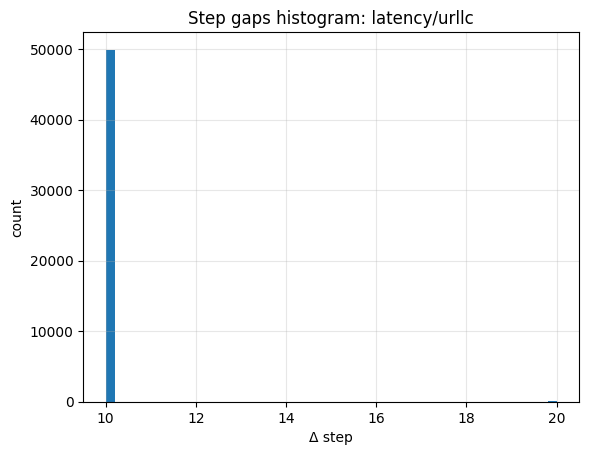

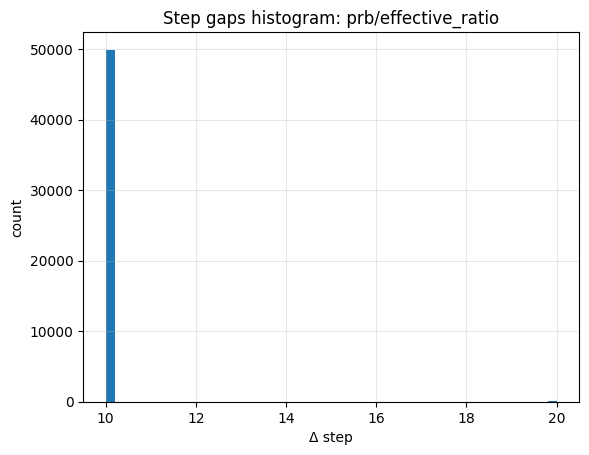

In [34]:
def gap_stats(df, name):
    s = df["step"].to_numpy()
    dif = np.diff(s)
    if len(dif) == 0:
        print(name, "has <2 points")
        return
    print(f"[{name}] median step gap:", np.median(dif))
    print(f"[{name}] mean step gap  :", np.mean(dif))
    print(f"[{name}] 95% step gap  :", np.percentile(dif, 95))
    print(f"[{name}] max step gap  :", np.max(dif))

gap_stats(df_metric, "metric")
gap_stats(df_jam, "jam")

plt.figure()
plt.hist(np.diff(df_metric["step"]), bins=50)
plt.title(f"Step gaps histogram: {METRIC_TAG}")
plt.xlabel("Δ step")
plt.ylabel("count")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure()
plt.hist(np.diff(df_jam["step"]), bins=50)
plt.title(f"Step gaps histogram: {JAM_TAG}")
plt.xlabel("Δ step")
plt.ylabel("count")
plt.grid(True, alpha=0.3)
plt.show()



[metric] episodes seen: 0 to 49 | total: 50
[metric] points per episode: min/median/max = 999 999 999

[jam] episodes seen: 0 to 49 | total: 50
[jam] points per episode: min/median/max = 999 999 999


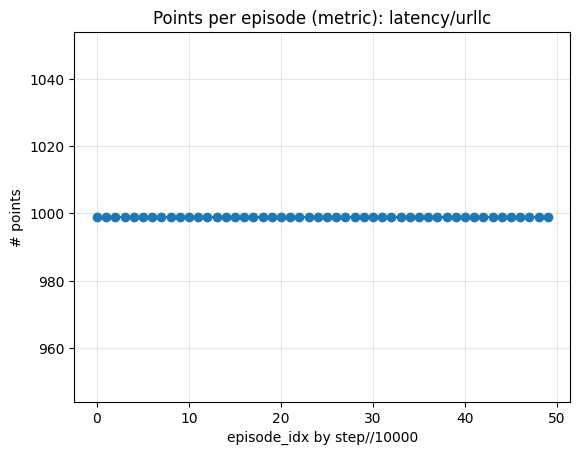

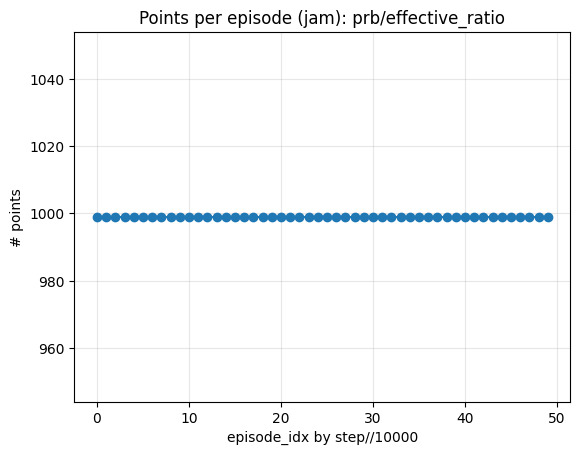

In [35]:
EP_LEN_SIM = 10000

def episode_coverage(df, name):
    s0 = int(df["step"].iloc[0])
    ep = ((df["step"] - s0) // EP_LEN_SIM).astype(int)
    counts = ep.value_counts().sort_index()
    print(f"\n[{name}] episodes seen:", counts.index.min(), "to", counts.index.max(),
          "| total:", counts.size)
    print(f"[{name}] points per episode: min/median/max =",
          counts.min(), int(counts.median()), counts.max())
    return counts

c_metric = episode_coverage(df_metric, "metric")
c_jam    = episode_coverage(df_jam, "jam")

plt.figure()
plt.plot(c_metric.index, c_metric.values, marker="o")
plt.title(f"Points per episode (metric): {METRIC_TAG}")
plt.xlabel("episode_idx by step//10000")
plt.ylabel("# points")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure()
plt.plot(c_jam.index, c_jam.values, marker="o")
plt.title(f"Points per episode (jam): {JAM_TAG}")
plt.xlabel("episode_idx by step//10000")
plt.ylabel("# points")
plt.grid(True, alpha=0.3)
plt.show()


In [36]:
JAM_THRESHOLD = 0.999

def segment_bool_runs(is_true: np.ndarray):
    if len(is_true) == 0:
        return []
    x = is_true.astype(np.int8)
    d = np.diff(x, prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends   = np.where(d == -1)[0]
    return list(zip(starts, ends))

# Build a simple jam boolean on jam timeline
eff = df_jam["value"].to_numpy()
steps = df_jam["step"].to_numpy()
is_jam = eff < JAM_THRESHOLD
runs = segment_bool_runs(is_jam)
print("Total jam ON runs detected (jam tag only):", len(runs))

# Assign episode by step//10000 on JAM timeline
s0 = int(steps[0])
ep_idx = ((steps - s0)//EP_LEN_SIM).astype(int)

# Count runs per episode
runs_per_ep = {}
for (a,b) in runs:
    ep = int(ep_idx[a])
    runs_per_ep[ep] = runs_per_ep.get(ep, 0) + 1

vals = pd.Series(runs_per_ep).sort_index()
print("Episodes with any detected jam runs:", len(vals))
print("Distribution of jam runs per episode:")
print(vals.value_counts().sort_index())


Total jam ON runs detected (jam tag only): 200
Episodes with any detected jam runs: 50
Distribution of jam runs per episode:
4    50
Name: count, dtype: int64


In [37]:
inner = df_metric.merge(df_jam, on="step", how="inner", suffixes=("_metric","_jam"))
print("Inner-merge rows:", len(inner))
print("Inner-merge step min/max:", inner.step.min(), inner.step.max())

# Episode coverage after inner merge
c_inner = episode_coverage(inner.rename(columns={"value_metric":"value"}), "INNER MERGE (metric timeline shrunk)")


Inner-merge rows: 49950
Inner-merge step min/max: 10 499990

[INNER MERGE (metric timeline shrunk)] episodes seen: 0 to 49 | total: 50
[INNER MERGE (metric timeline shrunk)] points per episode: min/median/max = 999 999 999


Total jam cycles: 3200


,policy,power,run_id,episode_idx,jam_idx_in_episode,n_jams_in_episode,jam_start_step,jam_end_step,baseline_X,endjam_Y,auc_on,mitigated_on,t_mitigate_on_sim_steps,mitigate_value,thresh_mit
0,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,0,4,10.0,1240.0,1.000000e-12,0.000031,0.003559,True,10.0,0.000095,0.000128
1,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,1,4,2500.0,3740.0,2.734169e-05,0.000022,0.000604,True,20.0,0.000018,0.000079
2,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,2,4,5000.0,6240.0,2.734169e-05,0.000022,0.000604,True,20.0,0.000018,0.000079
3,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,3,4,7500.0,8740.0,2.734169e-05,0.000022,0.000604,True,20.0,0.000018,0.000079
4,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,0,4,10010.0,11240.0,1.000000e-12,0.000000,0.000008,True,20.0,0.000000,0.000005
5,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,1,4,12500.0,13740.0,1.000000e-12,0.000000,0.000005,True,20.0,0.000000,0.000004
6,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,2,4,15000.0,16240.0,1.000000e-12,0.000000,0.000005,True,20.0,0.000000,0.000004
7,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,3,4,17500.0,18740.0,1.000000e-12,0.000000,0.000005,True,20.0,0.000000,0.000004
8,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,2,0,4,20010.0,21240.0,1.000000e-12,0.000000,0.000000,True,0.0,0.000000,0.000000
9,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,2,1,4,22500.0,23740.0,1.000000e-12,0.000000,0.000000,True,0.0,0.000000,0.000000



Jam runs per episode distribution (expect all 4):


n_jams_in_episode
4    800
Name: count, dtype: int64


Episodes per (policy,power) (expect 50):


policy      power
aggressive  5        50
            10       50
            15       50
            20       50
dqn         5        50
            10       50
            15       50
            20       50
idle        5        50
            10       50
            15       50
            20       50
random      5        50
            10       50
            15       50
            20       50
Name: episode_idx, dtype: int64


Cycles per (policy,power) (expect 200):


policy      power
aggressive  5        200
            10       200
            15       200
            20       200
dqn         5        200
            10       200
            15       200
            20       200
idle        5        200
            10       200
            15       200
            20       200
random      5        200
            10       200
            15       200
            20       200
Name: jam_idx_in_episode, dtype: int64

,policy,power,n_cycles,n_episodes,median_auc_on,mean_auc_on,mitigation_rate,median_t_mitigate_on
0,aggressive,5,200,50,0.008181,2.668840,0.620,0.0
1,aggressive,10,200,50,0.008688,2.678555,0.680,20.0
2,aggressive,15,200,50,0.014394,2.713942,0.655,20.0
3,aggressive,20,200,50,0.022560,2.745476,0.640,20.0
4,dqn,5,200,50,0.004750,0.631228,0.795,0.0
5,dqn,10,200,50,0.009385,0.986504,0.775,0.0
6,dqn,15,200,50,0.069970,1.301432,0.800,0.0
7,dqn,20,200,50,0.101179,2.144962,0.810,0.0
8,idle,5,200,50,0.024276,3.523587,0.535,0.0
9,idle,10,200,50,1.933603,4.572969,0.535,0.0


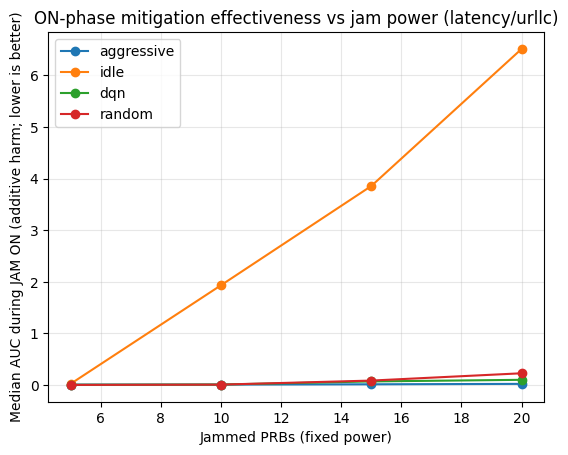

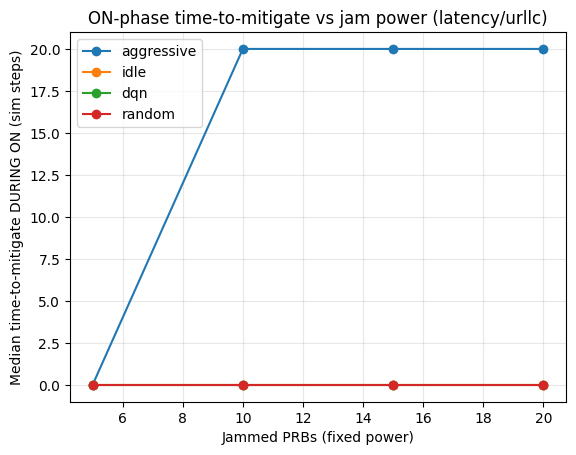

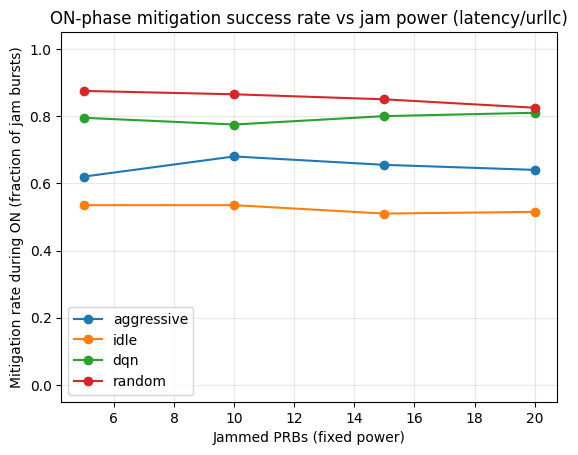

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

# =========================
# USER CONFIG
# =========================
ROOT = Path("../../tb_logs/res_validator")   # .../backend/tb_logs/res_validator
POLICIES = ["aggressive", "idle", "dqn", "random"]
POWERS = [5, 10, 15, 20]

METRIC_TAG = "latency/urllc"                # or "throughput/embb_mbps"
JAM_TAG = "prb/effective_ratio"

# Your logs: step is SIM step index, logged every ~10 steps
EP_LEN_SIM = 10000                          # sim steps per episode
LOG_STEP = 10                               # approx sample spacing in sim steps (diagnostics showed 10)

# Jam detection
JAM_THRESHOLD = 0.999                       # jam if eff_ratio < threshold

# Windows are in "samples" (each sample ~10 sim steps)
# If you think in sim steps, divide by LOG_STEP.
W_PRE = 10                                  # baseline window: 10 samples ~ 100 sim steps
W_END = 10                                  # end window: 10 samples ~ 100 sim steps

# Mitigation stability & tolerance
K_CONSEC = 5                                # 5 samples ~ 50 sim steps stable
EPS = 0.05                                  # used only for throughput mode below (optional)

# Metric type
LOWER_IS_BETTER = True                      # True for latency, False for throughput

# Peak-based mitigation (fixes "t_mitigate_on = 0" artifact)
N_PEAK = 10                                 # look at first 10 samples of ON to define "early ON peak" (~100 sim steps)
ALPHA = 0.20                                # mitigation = reduce metric by 20% from early-ON peak (latency)

# =========================
# TB reader
# =========================
def read_tb_scalar(event_file: Path, tags):
    tags = set(tags)
    out = {t: [] for t in tags}

    for rec in tf_record.tf_record_iterator(str(event_file)):
        e = Event.FromString(rec)
        if not e.summary.value:
            continue
        step = int(e.step)
        for v in e.summary.value:
            if v.tag in tags:
                out[v.tag].append((step, float(v.simple_value)))

    dfs = {}
    for t, rows in out.items():
        if not rows:
            dfs[t] = pd.DataFrame(columns=["step", "value"])
        else:
            df = pd.DataFrame(rows, columns=["step", "value"]).dropna()
            df = df.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
            dfs[t] = df
    return dfs

# =========================
# Jam segmentation helpers
# =========================
def segment_bool_runs(is_true: np.ndarray):
    """Return list of (start_idx, end_idx_exclusive) for True-runs."""
    if len(is_true) == 0:
        return []
    x = is_true.astype(np.int8)
    d = np.diff(x, prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends   = np.where(d == -1)[0]
    return list(zip(starts, ends))

def first_k_consecutive_true(mask: np.ndarray, k: int):
    """First index i such that mask[i:i+k] are all True. None if not found."""
    if k <= 1:
        idx = np.where(mask)[0]
        return int(idx[0]) if len(idx) else None
    if len(mask) < k:
        return None
    s = np.convolve(mask.astype(np.int32), np.ones(k, dtype=np.int32), mode="valid")
    hits = np.where(s == k)[0]
    return int(hits[0]) if len(hits) else None

# =========================
# Nested event file finder (your folder structure)
# =========================
def find_event_file_under_test_folder(test_folder: Path):
    evs = sorted(test_folder.rglob("events.out.tfevents.*"))
    if not evs:
        return None
    evs = sorted(evs, key=lambda p: (p.stat().st_mtime, p.stat().st_size))
    return evs[-1]

# =========================
# ON-phase metrics (robust)
# =========================
def compute_on_phase_metrics(df_metric, df_jam, policy, power, run_id):
    """
    Uses ONLY jammer ON windows (eff_ratio < threshold).
    For each ON burst:
      - baseline X: median of last W_PRE samples before jam start
      - AUC_on (additive harm):
            latency: sum(max(0, L - X))
            throughput: sum(max(0, X - T))
      - time-to-mitigate DURING ON:
            latency: time until L <= (1-ALPHA)*peak_early_ON for K_CONSEC samples
            throughput: time until T >= (1+ALPHA)*min_early_ON?  (we define symmetric rule)
    """
    if df_metric.empty or df_jam.empty:
        return pd.DataFrame()

    # Align by step (your diagnostics show they match perfectly)
    df = df_metric.rename(columns={"value": "metric"}).merge(
        df_jam.rename(columns={"value": "eff"}),
        on="step", how="inner"
    ).sort_values("step").reset_index(drop=True)

    if df.empty:
        return pd.DataFrame()

    step0 = int(df["step"].iloc[0])
    df["episode_idx"] = ((df["step"] - step0) // EP_LEN_SIM).astype(int)

    rows = []
    for ep_idx, ep in df.groupby("episode_idx", sort=True):
        ep = ep.reset_index(drop=True)

        steps  = ep["step"].to_numpy()
        metric = ep["metric"].to_numpy()
        eff    = ep["eff"].to_numpy()

        is_jam = eff < JAM_THRESHOLD
        jam_runs = segment_bool_runs(is_jam)

        # sanity: expected 4
        n_jams_in_episode = len(jam_runs)

        for j, (s_idx, e_idx) in enumerate(jam_runs):
            if e_idx <= s_idx:
                continue

            # --------------------------
            # Baseline X (pre-jam)
            # --------------------------
            pre_start = max(0, s_idx - W_PRE)
            pre_slice = metric[pre_start:s_idx]

            # robust baseline for latency: ignore zeros if they happen
            if LOWER_IS_BETTER:
                pre_slice = pre_slice[pre_slice > 0]

            if len(pre_slice) > 0:
                X = float(np.nanmedian(pre_slice))
            else:
                # fallback: use a larger lookback window
                back = metric[max(0, s_idx - 5*W_PRE):s_idx]
                if LOWER_IS_BETTER:
                    back = back[back > 0]
                X = float(np.nanmedian(back)) if len(back) else np.nan

            if not np.isfinite(X):
                # don't drop the burst; keep it but mark X
                X = 1e-12

            # --------------------------
            # ON slice
            # --------------------------
            on_steps = steps[s_idx:e_idx]
            on_slice = metric[s_idx:e_idx]

            if len(on_slice) == 0:
                continue

            # --------------------------
            # AUC_on (additive harm)
            # --------------------------
            if LOWER_IS_BETTER:
                harm = np.maximum(0.0, on_slice - X)
            else:
                harm = np.maximum(0.0, X - on_slice)
            auc_on = float(np.nansum(harm))

            # --------------------------
            # Time-to-mitigate DURING ON (peak-improvement)
            # --------------------------
            n0 = min(N_PEAK, len(on_slice))

            if LOWER_IS_BETTER:
                # define early ON peak latency
                peak = float(np.nanmax(on_slice[:n0]))
                thresh_mit = (1.0 - ALPHA) * peak  # needs improvement from peak
                good_on = on_slice <= thresh_mit
            else:
                # for throughput, define early ON minimum, and require improvement above it
                trough = float(np.nanmin(on_slice[:n0]))
                thresh_mit = (1.0 + ALPHA) * trough
                good_on = on_slice >= thresh_mit

            mit_offset = first_k_consecutive_true(good_on, K_CONSEC)
            if mit_offset is None:
                mitigated_on = False
                t_mit_on = np.inf
                mit_value = np.nan
            else:
                mitigated_on = True
                t_mit_on = float(on_steps[mit_offset] - on_steps[0])
                mit_value = float(on_slice[mit_offset])

            # end-of-jam value (context)
            end_start = max(s_idx, e_idx - W_END)
            Y = float(np.nanmedian(metric[end_start:e_idx]))

            rows.append({
                "policy": policy,
                "power": power,
                "run_id": run_id,
                "episode_idx": int(ep_idx),
                "jam_idx_in_episode": int(j),
                "n_jams_in_episode": int(n_jams_in_episode),

                "jam_start_step": float(steps[s_idx]),
                "jam_end_step": float(steps[e_idx - 1]),

                "baseline_X": X,
                "endjam_Y": Y,

                "auc_on": auc_on,
                "mitigated_on": mitigated_on,
                "t_mitigate_on_sim_steps": t_mit_on,
                "mitigate_value": mit_value,

                "thresh_mit": float(thresh_mit),
            })

    return pd.DataFrame(rows)

# =========================
# MAIN LOOP
# =========================
all_cycles = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    if not policy_dir.exists():
        print(f"[WARN] policy folder missing: {policy_dir}")
        continue

    for pwr in POWERS:
        suffix = f"_jam_fixed_{pwr}"
        matches = sorted([p for p in policy_dir.iterdir() if p.is_dir() and p.name.endswith(suffix)])
        if not matches:
            print(f"[WARN] missing test folder for {policy} power={pwr}")
            continue

        test_folder = matches[0]
        ev = find_event_file_under_test_folder(test_folder)
        if ev is None:
            print(f"[WARN] no event file under {test_folder}")
            continue

        dfs = read_tb_scalar(ev, tags=[METRIC_TAG, JAM_TAG])
        df_cycles = compute_on_phase_metrics(dfs[METRIC_TAG], dfs[JAM_TAG], policy, pwr, str(test_folder))
        if not df_cycles.empty:
            all_cycles.append(df_cycles)

df_cycles_all = pd.concat(all_cycles, ignore_index=True) if all_cycles else pd.DataFrame()
print("Total jam cycles:", len(df_cycles_all))
display(df_cycles_all.head(10))

# =========================
# SANITY CHECKS
# =========================
if not df_cycles_all.empty:
    print("\nJam runs per episode distribution (expect all 4):")
    display(
        df_cycles_all.groupby(["policy","power","episode_idx"])["n_jams_in_episode"]
        .first().value_counts().sort_index()
    )

    print("\nEpisodes per (policy,power) (expect 50):")
    display(df_cycles_all.groupby(["policy","power"])["episode_idx"].nunique())

    print("\nCycles per (policy,power) (expect 200):")
    display(df_cycles_all.groupby(["policy","power"])["jam_idx_in_episode"].count())

# =========================
# AGGREGATE + PLOTS
# =========================
if not df_cycles_all.empty:
    tmp = df_cycles_all.copy()
    tmp["t_mit_clean"] = tmp["t_mitigate_on_sim_steps"].replace([np.inf, -np.inf], np.nan)

    df_agg = (
        tmp.groupby(["policy","power"])
           .agg(
               n_cycles=("jam_idx_in_episode", "count"),
               n_episodes=("episode_idx", "nunique"),
               median_auc_on=("auc_on", "median"),
               mean_auc_on=("auc_on", "mean"),
               mitigation_rate=("mitigated_on", "mean"),
               median_t_mitigate_on=("t_mit_clean", "median"),
               
               median_reserve_on=("mean_reserve_used_on", "median"),
               mean_reserve_on=("mean_reserve_used_on", "mean"),
               median_max_reserve_on=("max_reserve_used_on", "median"),
               mean_sum_reserve_on=("sum_reserve_used_on", "mean"),
           )
           .reset_index()
           .sort_values(["policy","power"])
    )
    display(df_agg)
    
    print(df_jam[["reserve_used_prb"]].describe())
    print("reserve tag rows:", len(dfs_jam[RESERVE_TAG]))
    print("reserve min/max:", dfs_jam[RESERVE_TAG]["value"].min(), dfs_jam[RESERVE_TAG]["value"].max())


    # 1) AUC_on vs power
    plt.figure()
    for policy in POLICIES:
        sub = df_agg[df_agg["policy"] == policy].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_auc_on"], marker="o", label=policy)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median AUC during JAM ON (additive harm; lower is better)")
    plt.title(f"ON-phase mitigation effectiveness vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 2) Time-to-mitigate during ON
    plt.figure()
    for policy in POLICIES:
        sub = df_agg[df_agg["policy"] == policy].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_t_mitigate_on"], marker="o", label=policy)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median time-to-mitigate DURING ON (sim steps)")
    plt.title(f"ON-phase time-to-mitigate vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 3) Mitigation rate during ON
    plt.figure()
    for policy in POLICIES:
        sub = df_agg[df_agg["policy"] == policy].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["mitigation_rate"], marker="o", label=policy)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Mitigation rate during ON (fraction of jam bursts)")
    plt.title(f"ON-phase mitigation success rate vs jam power ({METRIC_TAG})")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


Total jam cycles: 3200


,policy,power,run_id,episode_idx,jam_idx_global,jam_start_step,jam_end_step,on_len_samples,auc_on,mitigated_on,t_mitigate_on_sim_steps,mitigate_value,mean_reserve_used_on,max_reserve_used_on,sum_reserve_used_on,impacted_on,n_jams_in_episode
0,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,0,10.0,1240.0,124,0.000499,True,330.0,0.000008,4.951613,5.0,614.0,True,4
1,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,1,2500.0,3740.0,125,0.000893,False,inf,NaN,4.952000,5.0,619.0,True,4
2,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,2,5000.0,6240.0,125,0.000672,False,inf,NaN,4.952000,5.0,619.0,True,4
3,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,3,7500.0,8740.0,125,0.000485,False,inf,NaN,4.952000,5.0,619.0,True,4
4,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,4,10010.0,11240.0,124,0.000008,True,20.0,0.000000,4.951613,5.0,614.0,True,4
5,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,5,12500.0,13740.0,125,0.000005,True,20.0,0.000000,4.952000,5.0,619.0,True,4
6,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,6,15000.0,16240.0,125,0.000005,True,20.0,0.000000,4.952000,5.0,619.0,True,4
7,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,7,17500.0,18740.0,125,0.000005,True,20.0,0.000000,4.952000,5.0,619.0,True,4
8,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,2,8,20010.0,21240.0,124,0.000000,True,0.0,0.000000,4.951613,5.0,614.0,False,4
9,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,2,9,22500.0,23740.0,125,0.000000,True,0.0,0.000000,4.952000,5.0,619.0,False,4



Episodes per (policy,power) (expect 50):


policy      power
aggressive  5        50
            10       50
            15       50
            20       50
dqn         5        50
            10       50
            15       50
            20       50
idle        5        50
            10       50
            15       50
            20       50
random      5        50
            10       50
            15       50
            20       50
Name: episode_idx, dtype: int64


Cycles per (policy,power) (expect 200):


policy      power
aggressive  5        200
            10       200
            15       200
            20       200
dqn         5        200
            10       200
            15       200
            20       200
idle        5        200
            10       200
            15       200
            20       200
random      5        200
            10       200
            15       200
            20       200
Name: jam_idx_global, dtype: int64


Jam runs per episode distribution (expect all 4):


n_jams_in_episode
4    800
Name: count, dtype: int64

/tmp/ipykernel_1173802/46274402.py:314: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: np.nanmedian(g.loc[(g["impacted_on"]) & (g["mitigated_on"]), "t_mit_clean"])
/tmp/ipykernel_1173802/46274402.py:344: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tmp.groupby(["policy","power"]).apply(rate_on_impacted).values


,policy,power,n_cycles,n_episodes,median_auc_on,mean_auc_on,mitigation_rate,mitigation_rate_impacted,impact_rate,median_t_mitigate_on,median_reserve_on,mean_reserve_on,median_max_reserve_on,mean_sum_reserve_on,median_t_mitigate_impacted_mitigated
0,aggressive,5,200,50,0.008078,1.095927,0.370,0.125000,0.720,0.0,4.952000,4.951903,5.0,617.750,20.0
1,aggressive,10,200,50,0.008462,1.120070,0.360,0.238095,0.840,0.0,9.936000,9.935871,12.0,1239.500,20.0
2,aggressive,15,200,50,0.014394,1.180886,0.325,0.262295,0.915,20.0,14.848000,14.847694,15.0,1852.250,20.0
3,aggressive,20,200,50,0.022451,1.231551,0.320,0.276596,0.940,30.0,17.792000,17.791581,18.0,2219.500,30.0
4,dqn,5,200,50,0.004510,1.169473,0.410,0.174825,0.715,0.0,2.205097,5.803420,18.0,724.030,60.0
5,dqn,10,200,50,0.010269,2.364001,0.440,0.317073,0.820,10.0,5.440000,6.684958,18.0,834.015,90.0
6,dqn,15,200,50,0.059993,3.013973,0.415,0.323699,0.865,50.0,9.340000,8.761397,18.0,1093.080,170.0
7,dqn,20,200,50,0.088054,6.089649,0.375,0.324324,0.925,210.0,11.606484,10.511213,18.0,1311.315,340.0
8,idle,5,200,50,0.022335,4.113811,0.270,0.026667,0.750,0.0,0.000000,0.000000,0.0,0.000,0.0
9,idle,10,200,50,1.265975,8.002309,0.135,0.017045,0.880,0.0,0.000000,0.000000,0.0,0.000,0.0


       reserve_used_prb
count      49950.000000
mean          11.702783
std            4.448525
min            0.000000
25%            8.000000
50%           12.000000
75%           15.000000
max           18.000000
reserve tag rows: 49950
reserve min/max: 0.0 18.0


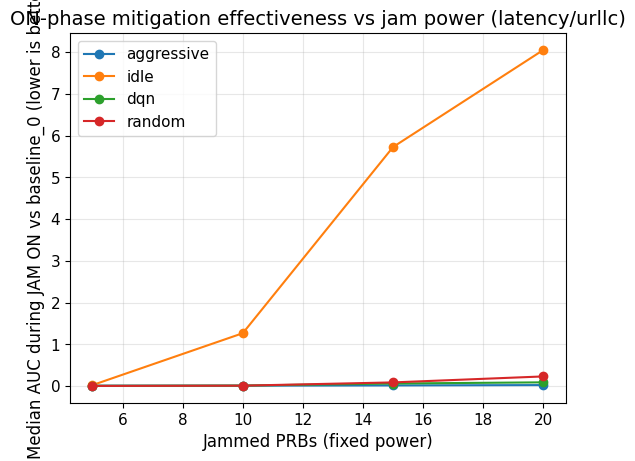

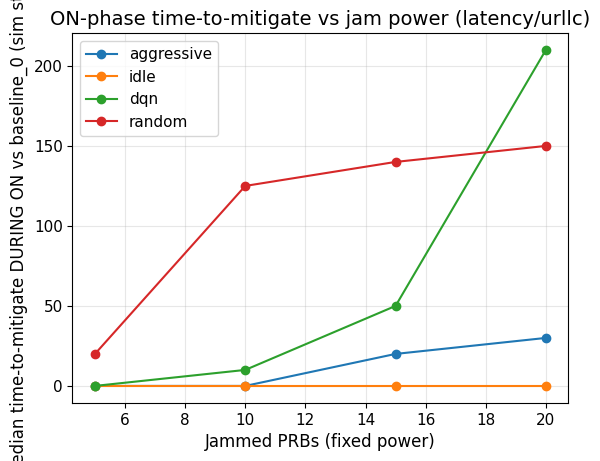

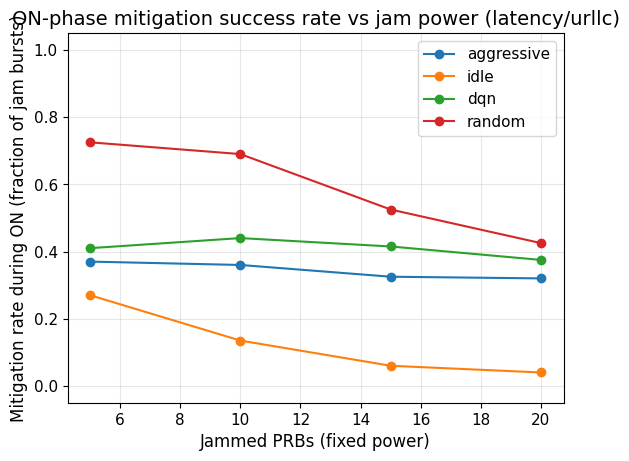

In [64]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

# =========================
# USER CONFIG
# =========================
ROOT = Path("../../tb_logs/23_jan")   # .../backend/tb_logs/res_validator
POLICIES = ["aggressive", "idle", "dqn", "random"]
POWERS = [5, 10, 15, 20]

RESERVE_TAG = "obs/reserve_used_prb"
METRIC_TAG = "latency/urllc"                # or "throughput/embb_mbps"
JAM_TAG = "prb/effective_ratio"

EP_LEN_SIM = 10000                          # sim steps per episode
JAM_THRESHOLD = 0.999

#ABS_TOLERANCE = 0.001


# Baseline folder suffix (per policy)
BASELINE_SUFFIX = "_jam_fixed_baseline_0"

# Mitigation definition (baseline-relative, during ON)
K_CONSEC = 10         # 5 samples ≈ 50 sim steps (since you log every 10)
EPS = 0.01           # 5% tolerance vs baseline

LOWER_IS_BETTER = True   # True for latency, False for throughput

# =========================
# TB reader
# =========================
def read_tb_scalar(event_file: Path, tags):
    tags = set(tags)
    out = {t: [] for t in tags}

    for rec in tf_record.tf_record_iterator(str(event_file)):
        e = Event.FromString(rec)
        if not e.summary.value:
            continue
        step = int(e.step)
        for v in e.summary.value:
            if v.tag in tags:
                out[v.tag].append((step, float(v.simple_value)))

    dfs = {}
    for t, rows in out.items():
        if not rows:
            dfs[t] = pd.DataFrame(columns=["step", "value"])
        else:
            df = pd.DataFrame(rows, columns=["step", "value"]).dropna()
            df = df.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
            dfs[t] = df
    return dfs

# =========================
# Helpers
# =========================
def segment_bool_runs(is_true: np.ndarray):
    """Return list of (start_idx, end_idx_exclusive) for True-runs."""
    if len(is_true) == 0:
        return []
    x = is_true.astype(np.int8)
    d = np.diff(x, prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends   = np.where(d == -1)[0]
    return list(zip(starts, ends))

def first_k_consecutive_true(mask: np.ndarray, k: int):
    """First index i such that mask[i:i+k] are all True. None if not found."""
    if k <= 1:
        idx = np.where(mask)[0]
        return int(idx[0]) if len(idx) else None
    if len(mask) < k:
        return None
    s = np.convolve(mask.astype(np.int32), np.ones(k, dtype=np.int32), mode="valid")
    hits = np.where(s == k)[0]
    return int(hits[0]) if len(hits) else None

def find_event_file_under_test_folder(test_folder: Path):
    """
    test_folder: .../policy/gym_from_testing_config_... (test)
    Inside it, one run subfolder exists, and then events.out.tfevents.*
    """
    evs = sorted(test_folder.rglob("events.out.tfevents.*"))
    if not evs:
        return None
    evs = sorted(evs, key=lambda p: (p.stat().st_mtime, p.stat().st_size))
    return evs[-1]

def pick_test_folder(policy_dir: Path, suffix: str):
    matches = sorted([p for p in policy_dir.iterdir() if p.is_dir() and p.name.endswith(suffix)])
    return matches[0] if matches else None

# =========================
# Build aligned tables
# =========================
# def build_jam_table(dfs):
#     """Return df with columns: step, metric, eff"""
#     df_metric = dfs[METRIC_TAG].rename(columns={"value":"metric"})
#     df_jam    = dfs[JAM_TAG].rename(columns={"value":"eff"})
#     df = df_metric.merge(df_jam, on="step", how="inner").sort_values("step").reset_index(drop=True)
#     return df

def build_jam_table(dfs):
    """Return df with: step, metric, eff, reserve_used_prb."""
    df_metric = dfs[METRIC_TAG].rename(columns={"value": "metric"})
    df_jam    = dfs[JAM_TAG].rename(columns={"value": "eff"})
    df_res    = dfs[RESERVE_TAG].rename(columns={"value": "reserve_used_prb"})

    df = df_metric.merge(df_jam, on="step", how="inner")
    df = df.merge(df_res, on="step", how="left")  # left in case some steps missing
    return df.sort_values("step").reset_index(drop=True)

def build_baseline_metric_table(dfs_base):
    """Return df with columns: step, base_metric"""
    dfb = dfs_base[METRIC_TAG].rename(columns={"value":"base_metric"})
    dfb = dfb.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
    return dfb

# =========================
# Core computation: ON-phase vs baseline_0
# =========================
def compute_on_metrics_vs_baseline(df_jam, df_base_metric, policy, power, run_id):
    """
    df_jam: step, metric, eff  (jam run)
    df_base_metric: step, base_metric (baseline run, same policy)
    We align by step (your logs match perfectly).
    """
    # Merge baseline metric onto jam timeline
    df = df_jam.merge(df_base_metric, on="step", how="inner").sort_values("step").reset_index(drop=True)
    if df.empty:
        return pd.DataFrame()

    step0 = int(df["step"].iloc[0])
    df["episode_idx"] = ((df["step"] - step0) // EP_LEN_SIM).astype(int)

    steps = df["step"].to_numpy()
    m_jam = df["metric"].to_numpy()
    m_base = df["base_metric"].to_numpy()
    eff   = df["eff"].to_numpy()
    reserve = df["reserve_used_prb"].to_numpy() if "reserve_used_prb" in df.columns else None


    is_jam = eff < JAM_THRESHOLD
    jam_runs = segment_bool_runs(is_jam)

    rows = []

    # Count jam bursts per episode (for sanity)
    ep_idx_arr = df["episode_idx"].to_numpy()
    jam_count_per_ep = {}
    for (s_idx, e_idx) in jam_runs:
        ep = int(ep_idx_arr[s_idx])
        jam_count_per_ep[ep] = jam_count_per_ep.get(ep, 0) + 1

    for j, (s_idx, e_idx) in enumerate(jam_runs):
        if e_idx <= s_idx:
            continue

        on_steps = steps[s_idx:e_idx]
        on_jam = m_jam[s_idx:e_idx]
        on_base = m_base[s_idx:e_idx]
        
        mean_reserve_on = np.nan
        max_reserve_on = np.nan
        sum_reserve_on = np.nan

        if reserve is not None:
            r_on = reserve[s_idx:e_idx]
            mean_reserve_on = float(np.nanmean(r_on))
            max_reserve_on  = float(np.nanmax(r_on))
            sum_reserve_on  = float(np.nansum(r_on))


        if len(on_jam) == 0:
            continue

        # -------- AUC_on (baseline-relative, additive) --------
        if LOWER_IS_BETTER:
            harm = np.maximum(0.0, on_jam - on_base)
            auc_on = float(np.nansum(harm))
            good_on = on_jam <= (1.0 + EPS) * (on_base + 1e-12)
            impacted = np.any(on_jam > (1.0 + EPS) * (on_base + 1e-12))
        else:
            harm = np.maximum(0.0, on_base - on_jam)
            auc_on = float(np.nansum(harm))
            good_on = on_jam >= (1.0 - EPS) * (on_base + 1e-12)
            impacted = np.any(on_jam < (1.0 - EPS) * (on_base + 1e-12))

        # -------- time-to-mitigate during ON (baseline-relative) --------
        mit_offset = first_k_consecutive_true(good_on, K_CONSEC)
        if mit_offset is None:
            mitigated_on = False
            t_mit_on = np.inf
            mit_value = np.nan
        else:
            mitigated_on = True
            t_mit_on = float(on_steps[mit_offset] - on_steps[0])
            mit_value = float(on_jam[mit_offset])

        ep = int(ep_idx_arr[s_idx])
        rows.append({
            "policy": policy,
            "power": power,
            "run_id": run_id,
            "episode_idx": ep,
            "jam_idx_global": int(j),

            "jam_start_step": float(steps[s_idx]),
            "jam_end_step": float(steps[e_idx - 1]),
            "on_len_samples": int(e_idx - s_idx),

            "auc_on": auc_on,
            "mitigated_on": mitigated_on,
            "t_mitigate_on_sim_steps": t_mit_on,
            "mitigate_value": mit_value,
            "mean_reserve_used_on": mean_reserve_on,
            "max_reserve_used_on": max_reserve_on,
            "sum_reserve_used_on": sum_reserve_on,
            "impacted_on": bool(impacted),

        })

    out = pd.DataFrame(rows)

    # Attach jams-per-episode sanity info
    if not out.empty:
        out["n_jams_in_episode"] = out["episode_idx"].map(jam_count_per_ep).fillna(0).astype(int)

    return out

# =========================
# MAIN: load baseline per policy, then jam runs per power
# =========================
all_cycles = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    if not policy_dir.exists():
        print(f"[WARN] policy folder missing: {policy_dir}")
        continue

    # ----- load baseline_0 once per policy -----
    base_folder = pick_test_folder(policy_dir, BASELINE_SUFFIX)
    if base_folder is None:
        print(f"[WARN] missing baseline folder for policy={policy} suffix={BASELINE_SUFFIX}")
        continue

    base_ev = find_event_file_under_test_folder(base_folder)
    if base_ev is None:
        print(f"[WARN] no event file in baseline folder: {base_folder}")
        continue

    dfs_base = read_tb_scalar(base_ev, tags=[METRIC_TAG])
    df_base_metric = build_baseline_metric_table(dfs_base)

    # ----- iterate jam powers -----
    for pwr in POWERS:
        jam_folder = pick_test_folder(policy_dir, f"_jam_fixed_{pwr}")
        if jam_folder is None:
            print(f"[WARN] missing jam folder for {policy} power={pwr}")
            continue

        jam_ev = find_event_file_under_test_folder(jam_folder)
        if jam_ev is None:
            print(f"[WARN] no event file in jam folder: {jam_folder}")
            continue

        #dfs_jam = read_tb_scalar(jam_ev, tags=[METRIC_TAG, JAM_TAG])
        dfs_jam = read_tb_scalar(jam_ev, tags=[METRIC_TAG, JAM_TAG, RESERVE_TAG])

        df_jam = build_jam_table(dfs_jam)

        df_cycles = compute_on_metrics_vs_baseline(df_jam, df_base_metric, policy, pwr, str(jam_folder))
        if not df_cycles.empty:
            all_cycles.append(df_cycles)

df_cycles_all = pd.concat(all_cycles, ignore_index=True) if all_cycles else pd.DataFrame()
print("Total jam cycles:", len(df_cycles_all))
display(df_cycles_all.head(10))

# =========================
# SANITY CHECKS
# =========================
if not df_cycles_all.empty:
    print("\nEpisodes per (policy,power) (expect 50):")
    display(df_cycles_all.groupby(["policy","power"])["episode_idx"].nunique())

    print("\nCycles per (policy,power) (expect 200):")
    display(df_cycles_all.groupby(["policy","power"])["jam_idx_global"].count())

    print("\nJam runs per episode distribution (expect all 4):")
    display(
        df_cycles_all.groupby(["policy","power","episode_idx"])["n_jams_in_episode"]
        .first().value_counts().sort_index()
    )

# =========================
# AGGREGATE + PLOTS
# =========================
if not df_cycles_all.empty:
    tmp = df_cycles_all.copy()
    tmp["t_mit_clean"] = tmp["t_mitigate_on_sim_steps"].replace([np.inf, -np.inf], np.nan)


    tmit_impacted_mitigated = (
    tmp.groupby(["policy","power"])
       .apply(lambda g: np.nanmedian(g.loc[(g["impacted_on"]) & (g["mitigated_on"]), "t_mit_clean"])
              if ((g["impacted_on"]) & (g["mitigated_on"])).any() else np.nan)
       .reset_index(name="median_t_mitigate_impacted_mitigated")
        )
    df_agg = (
        tmp.groupby(["policy","power"])
           .agg(
               n_cycles=("jam_idx_global", "count"),
               n_episodes=("episode_idx", "nunique"),
               median_auc_on=("auc_on", "median"),
               mean_auc_on=("auc_on", "mean"),
               mitigation_rate=("mitigated_on", "mean"),
               mitigation_rate_impacted=("mitigated_on", lambda s: np.nan), 
               impact_rate=("impacted_on", "mean"),

               median_t_mitigate_on=("t_mit_clean", "median"),
               median_reserve_on=("mean_reserve_used_on", "median"),
               mean_reserve_on=("mean_reserve_used_on", "mean"),
               median_max_reserve_on=("max_reserve_used_on", "median"),
               mean_sum_reserve_on=("sum_reserve_used_on", "mean"),
           )
           .reset_index()
           .sort_values(["policy","power"])
    )
    def rate_on_impacted(g):
        imp = g["impacted_on"].to_numpy()
        mit = g["mitigated_on"].to_numpy()
        return np.nan if imp.sum()==0 else mit[imp].mean()

    df_agg["mitigation_rate_impacted"] = (
        tmp.groupby(["policy","power"]).apply(rate_on_impacted).values
    )
    df_agg = df_agg.merge(tmit_impacted_mitigated, on=["policy","power"], how="left")


    display(df_agg)
    print(df_jam[["reserve_used_prb"]].describe())
    print("reserve tag rows:", len(dfs_jam[RESERVE_TAG]))
    print("reserve min/max:", dfs_jam[RESERVE_TAG]["value"].min(), dfs_jam[RESERVE_TAG]["value"].max())


    # 1) AUC_on vs power
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_auc_on"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median AUC during JAM ON vs baseline_0 (lower is better)")
    plt.title(f"ON-phase mitigation effectiveness vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 2) Time-to-mitigate during ON
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_t_mitigate_on"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median time-to-mitigate DURING ON vs baseline_0 (sim steps)")
    plt.title(f"ON-phase time-to-mitigate vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 3) Mitigation rate during ON
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["mitigation_rate"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Mitigation rate during ON (fraction of jam bursts)")
    plt.title(f"ON-phase mitigation success rate vs jam power ({METRIC_TAG})")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


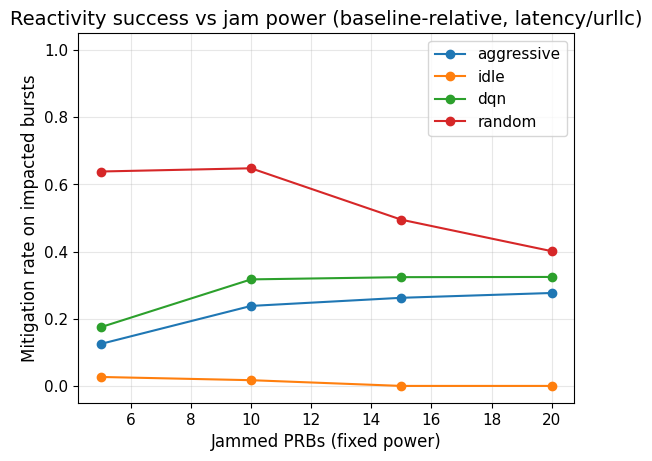

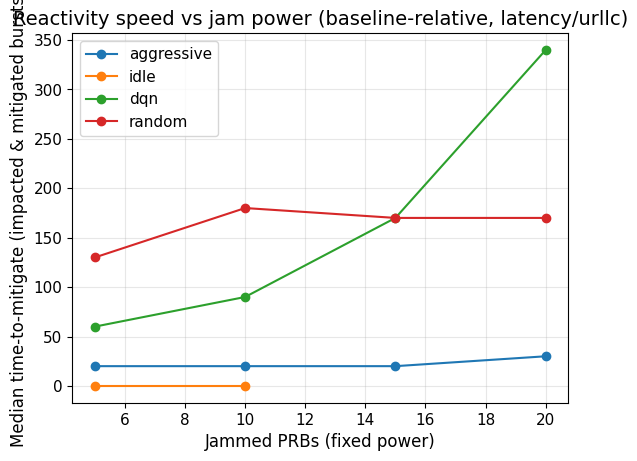

In [65]:
# 4) Mitigation rate (impacted only)
plt.figure()
for pol in POLICIES:
    sub = df_agg[df_agg["policy"] == pol].sort_values("power")
    if len(sub) == 0:
        continue
    plt.plot(sub["power"], sub["mitigation_rate_impacted"], marker="o", label=pol)
plt.xlabel("Jammed PRBs (fixed power)")
plt.ylabel("Mitigation rate on impacted bursts")
plt.title(f"Reactivity success vs jam power (baseline-relative, {METRIC_TAG})")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 5) Time-to-mitigate (impacted & mitigated only)
plt.figure()
for pol in POLICIES:
    sub = df_agg[df_agg["policy"] == pol].sort_values("power")
    if len(sub) == 0:
        continue
    plt.plot(sub["power"], sub["median_t_mitigate_impacted_mitigated"], marker="o", label=pol)
plt.xlabel("Jammed PRBs (fixed power)")
plt.ylabel("Median time-to-mitigate (impacted & mitigated bursts)")
plt.title(f"Reactivity speed vs jam power (baseline-relative, {METRIC_TAG})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Total jam cycles: 3200


,policy,power,run_id,episode_idx,jam_idx_global,jam_start_step,jam_end_step,on_len_samples,auc_on,mitigated_on,t_mitigate_on_sim_steps,mitigate_value,mean_reserve_used_on,max_reserve_used_on,sum_reserve_used_on,n_jams_in_episode
0,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,0,10.0,1240.0,124,0.143997,True,0.0,95.856003,4.951613,5.0,614.0,4
1,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,1,2500.0,3740.0,125,0.287994,True,0.0,95.856003,4.952000,5.0,619.0,4
2,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,2,5000.0,6240.0,125,0.287994,True,0.0,95.856003,4.952000,5.0,619.0,4
3,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,3,7500.0,8740.0,125,0.287994,True,0.0,95.856003,4.952000,5.0,619.0,4
4,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,4,10010.0,11240.0,124,0.000000,True,0.0,96.000000,4.951613,5.0,614.0,4
5,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,5,12500.0,13740.0,125,0.000000,True,0.0,96.000000,4.952000,5.0,619.0,4
6,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,6,15000.0,16240.0,125,0.000000,True,0.0,96.000000,4.952000,5.0,619.0,4
7,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,7,17500.0,18740.0,125,0.000000,True,0.0,96.000000,4.952000,5.0,619.0,4
8,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,2,8,20010.0,21240.0,124,0.000000,True,0.0,96.000000,4.951613,5.0,614.0,4
9,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,2,9,22500.0,23740.0,125,0.000000,True,0.0,96.000000,4.952000,5.0,619.0,4



Episodes per (policy,power) (expect 50):


policy      power
aggressive  5        50
            10       50
            15       50
            20       50
dqn         5        50
            10       50
            15       50
            20       50
idle        5        50
            10       50
            15       50
            20       50
random      5        50
            10       50
            15       50
            20       50
Name: episode_idx, dtype: int64


Cycles per (policy,power) (expect 200):


policy      power
aggressive  5        200
            10       200
            15       200
            20       200
dqn         5        200
            10       200
            15       200
            20       200
idle        5        200
            10       200
            15       200
            20       200
random      5        200
            10       200
            15       200
            20       200
Name: jam_idx_global, dtype: int64


Jam runs per episode distribution (expect all 4):


n_jams_in_episode
4    800
Name: count, dtype: int64

,policy,power,n_cycles,n_episodes,median_auc_on,mean_auc_on,mitigation_rate,median_t_mitigate_on,median_reserve_on,mean_reserve_on,median_max_reserve_on,mean_sum_reserve_on
0,aggressive,5,200,50,0.000000,6.350762,1.000,0.0,4.952000,4.951903,5.0,617.750
1,aggressive,10,200,50,0.000000,8.178481,1.000,0.0,9.936000,9.935871,12.0,1239.500
2,aggressive,15,200,50,0.760002,10.585560,1.000,0.0,14.848000,14.847694,15.0,1852.250
3,aggressive,20,200,50,7.552002,26.891238,1.000,0.0,17.792000,17.791581,18.0,2219.500
4,dqn,5,200,50,0.000000,57.016580,1.000,0.0,2.205097,5.803420,18.0,724.030
5,dqn,10,200,50,0.000000,144.417032,0.960,0.0,5.440000,6.684958,18.0,834.015
6,dqn,15,200,50,15.263702,226.266719,0.905,0.0,9.340000,8.761397,18.0,1093.080
7,dqn,20,200,50,237.647942,351.838607,0.785,0.0,11.606484,10.511213,18.0,1311.315
8,idle,5,200,50,0.000000,54.360927,1.000,0.0,0.000000,0.000000,0.0,0.000
9,idle,10,200,50,3.023941,177.604236,0.915,0.0,0.000000,0.000000,0.0,0.000


       reserve_used_prb
count      49950.000000
mean          11.702783
std            4.448525
min            0.000000
25%            8.000000
50%           12.000000
75%           15.000000
max           18.000000
reserve tag rows: 49950
reserve min/max: 0.0 18.0


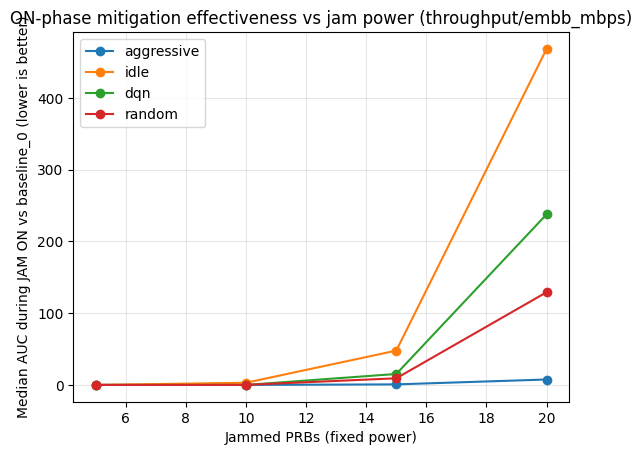

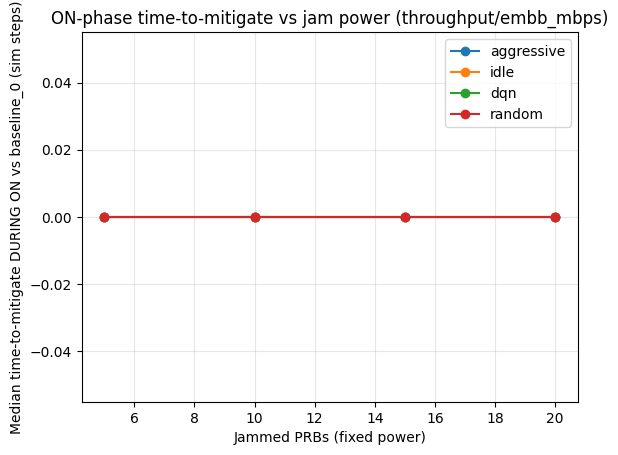

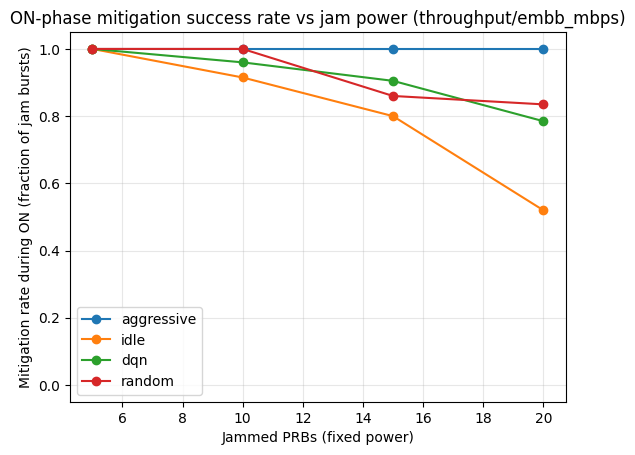

In [46]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

# =========================
# USER CONFIG
# =========================
ROOT = Path("../../tb_logs/23_jan")   # .../backend/tb_logs/res_validator
POLICIES = ["aggressive", "idle", "dqn", "random"]
POWERS = [5, 10, 15, 20]

RESERVE_TAG = "obs/reserve_used_prb"
METRIC_TAG = "throughput/embb_mbps"                # or "throughput/embb_mbps"
JAM_TAG = "prb/effective_ratio"

EP_LEN_SIM = 10000                          # sim steps per episode
JAM_THRESHOLD = 0.999

# Baseline folder suffix (per policy)
BASELINE_SUFFIX = "_jam_fixed_baseline_0"

# Mitigation definition (baseline-relative, during ON)
K_CONSEC = 5         # 5 samples ≈ 50 sim steps (since you log every 10)
EPS = 0.05           # 5% tolerance vs baseline

LOWER_IS_BETTER = False   # True for latency, False for throughput

# =========================
# TB reader
# =========================
def read_tb_scalar(event_file: Path, tags):
    tags = set(tags)
    out = {t: [] for t in tags}

    for rec in tf_record.tf_record_iterator(str(event_file)):
        e = Event.FromString(rec)
        if not e.summary.value:
            continue
        step = int(e.step)
        for v in e.summary.value:
            if v.tag in tags:
                out[v.tag].append((step, float(v.simple_value)))

    dfs = {}
    for t, rows in out.items():
        if not rows:
            dfs[t] = pd.DataFrame(columns=["step", "value"])
        else:
            df = pd.DataFrame(rows, columns=["step", "value"]).dropna()
            df = df.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
            dfs[t] = df
    return dfs

# =========================
# Helpers
# =========================
def segment_bool_runs(is_true: np.ndarray):
    """Return list of (start_idx, end_idx_exclusive) for True-runs."""
    if len(is_true) == 0:
        return []
    x = is_true.astype(np.int8)
    d = np.diff(x, prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends   = np.where(d == -1)[0]
    return list(zip(starts, ends))

def first_k_consecutive_true(mask: np.ndarray, k: int):
    """First index i such that mask[i:i+k] are all True. None if not found."""
    if k <= 1:
        idx = np.where(mask)[0]
        return int(idx[0]) if len(idx) else None
    if len(mask) < k:
        return None
    s = np.convolve(mask.astype(np.int32), np.ones(k, dtype=np.int32), mode="valid")
    hits = np.where(s == k)[0]
    return int(hits[0]) if len(hits) else None

def find_event_file_under_test_folder(test_folder: Path):
    """
    test_folder: .../policy/gym_from_testing_config_... (test)
    Inside it, one run subfolder exists, and then events.out.tfevents.*
    """
    evs = sorted(test_folder.rglob("events.out.tfevents.*"))
    if not evs:
        return None
    evs = sorted(evs, key=lambda p: (p.stat().st_mtime, p.stat().st_size))
    return evs[-1]

def pick_test_folder(policy_dir: Path, suffix: str):
    matches = sorted([p for p in policy_dir.iterdir() if p.is_dir() and p.name.endswith(suffix)])
    return matches[0] if matches else None

# =========================
# Build aligned tables
# =========================
# def build_jam_table(dfs):
#     """Return df with columns: step, metric, eff"""
#     df_metric = dfs[METRIC_TAG].rename(columns={"value":"metric"})
#     df_jam    = dfs[JAM_TAG].rename(columns={"value":"eff"})
#     df = df_metric.merge(df_jam, on="step", how="inner").sort_values("step").reset_index(drop=True)
#     return df

def build_jam_table(dfs):
    """Return df with: step, metric, eff, reserve_used_prb."""
    df_metric = dfs[METRIC_TAG].rename(columns={"value": "metric"})
    df_jam    = dfs[JAM_TAG].rename(columns={"value": "eff"})
    df_res    = dfs[RESERVE_TAG].rename(columns={"value": "reserve_used_prb"})

    df = df_metric.merge(df_jam, on="step", how="inner")
    df = df.merge(df_res, on="step", how="left")  # left in case some steps missing
    return df.sort_values("step").reset_index(drop=True)

def build_baseline_metric_table(dfs_base):
    """Return df with columns: step, base_metric"""
    dfb = dfs_base[METRIC_TAG].rename(columns={"value":"base_metric"})
    dfb = dfb.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
    return dfb

# =========================
# Core computation: ON-phase vs baseline_0
# =========================
def compute_on_metrics_vs_baseline(df_jam, df_base_metric, policy, power, run_id):
    """
    df_jam: step, metric, eff  (jam run)
    df_base_metric: step, base_metric (baseline run, same policy)
    We align by step (your logs match perfectly).
    """
    # Merge baseline metric onto jam timeline
    df = df_jam.merge(df_base_metric, on="step", how="inner").sort_values("step").reset_index(drop=True)
    if df.empty:
        return pd.DataFrame()

    step0 = int(df["step"].iloc[0])
    df["episode_idx"] = ((df["step"] - step0) // EP_LEN_SIM).astype(int)

    steps = df["step"].to_numpy()
    m_jam = df["metric"].to_numpy()
    m_base = df["base_metric"].to_numpy()
    eff   = df["eff"].to_numpy()
    reserve = df["reserve_used_prb"].to_numpy() if "reserve_used_prb" in df.columns else None


    is_jam = eff < JAM_THRESHOLD
    jam_runs = segment_bool_runs(is_jam)

    rows = []

    # Count jam bursts per episode (for sanity)
    ep_idx_arr = df["episode_idx"].to_numpy()
    jam_count_per_ep = {}
    for (s_idx, e_idx) in jam_runs:
        ep = int(ep_idx_arr[s_idx])
        jam_count_per_ep[ep] = jam_count_per_ep.get(ep, 0) + 1

    for j, (s_idx, e_idx) in enumerate(jam_runs):
        if e_idx <= s_idx:
            continue

        on_steps = steps[s_idx:e_idx]
        on_jam = m_jam[s_idx:e_idx]
        on_base = m_base[s_idx:e_idx]
        
        mean_reserve_on = np.nan
        max_reserve_on = np.nan
        sum_reserve_on = np.nan

        if reserve is not None:
            r_on = reserve[s_idx:e_idx]
            mean_reserve_on = float(np.nanmean(r_on))
            max_reserve_on  = float(np.nanmax(r_on))
            sum_reserve_on  = float(np.nansum(r_on))


        if len(on_jam) == 0:
            continue

        # -------- AUC_on (baseline-relative, additive) --------
        if LOWER_IS_BETTER:
            harm = np.maximum(0.0, on_jam - on_base)
            auc_on = float(np.nansum(harm))
            good_on = on_jam <= (1.0 + EPS) * (on_base + 1e-12)
        else:
            harm = np.maximum(0.0, on_base - on_jam)
            auc_on = float(np.nansum(harm))
            good_on = on_jam >= (1.0 - EPS) * (on_base + 1e-12)

        # -------- time-to-mitigate during ON (baseline-relative) --------
        mit_offset = first_k_consecutive_true(good_on, K_CONSEC)
        if mit_offset is None:
            mitigated_on = False
            t_mit_on = np.inf
            mit_value = np.nan
        else:
            mitigated_on = True
            t_mit_on = float(on_steps[mit_offset] - on_steps[0])
            mit_value = float(on_jam[mit_offset])

        ep = int(ep_idx_arr[s_idx])
        rows.append({
            "policy": policy,
            "power": power,
            "run_id": run_id,
            "episode_idx": ep,
            "jam_idx_global": int(j),

            "jam_start_step": float(steps[s_idx]),
            "jam_end_step": float(steps[e_idx - 1]),
            "on_len_samples": int(e_idx - s_idx),

            "auc_on": auc_on,
            "mitigated_on": mitigated_on,
            "t_mitigate_on_sim_steps": t_mit_on,
            "mitigate_value": mit_value,
            "mean_reserve_used_on": mean_reserve_on,
            "max_reserve_used_on": max_reserve_on,
            "sum_reserve_used_on": sum_reserve_on,
        })

    out = pd.DataFrame(rows)

    # Attach jams-per-episode sanity info
    if not out.empty:
        out["n_jams_in_episode"] = out["episode_idx"].map(jam_count_per_ep).fillna(0).astype(int)

    return out

# =========================
# MAIN: load baseline per policy, then jam runs per power
# =========================
all_cycles = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    if not policy_dir.exists():
        print(f"[WARN] policy folder missing: {policy_dir}")
        continue

    # ----- load baseline_0 once per policy -----
    base_folder = pick_test_folder(policy_dir, BASELINE_SUFFIX)
    if base_folder is None:
        print(f"[WARN] missing baseline folder for policy={policy} suffix={BASELINE_SUFFIX}")
        continue

    base_ev = find_event_file_under_test_folder(base_folder)
    if base_ev is None:
        print(f"[WARN] no event file in baseline folder: {base_folder}")
        continue

    dfs_base = read_tb_scalar(base_ev, tags=[METRIC_TAG])
    df_base_metric = build_baseline_metric_table(dfs_base)

    # ----- iterate jam powers -----
    for pwr in POWERS:
        jam_folder = pick_test_folder(policy_dir, f"_jam_fixed_{pwr}")
        if jam_folder is None:
            print(f"[WARN] missing jam folder for {policy} power={pwr}")
            continue

        jam_ev = find_event_file_under_test_folder(jam_folder)
        if jam_ev is None:
            print(f"[WARN] no event file in jam folder: {jam_folder}")
            continue

        #dfs_jam = read_tb_scalar(jam_ev, tags=[METRIC_TAG, JAM_TAG])
        dfs_jam = read_tb_scalar(jam_ev, tags=[METRIC_TAG, JAM_TAG, RESERVE_TAG])

        df_jam = build_jam_table(dfs_jam)

        df_cycles = compute_on_metrics_vs_baseline(df_jam, df_base_metric, policy, pwr, str(jam_folder))
        if not df_cycles.empty:
            all_cycles.append(df_cycles)

df_cycles_all = pd.concat(all_cycles, ignore_index=True) if all_cycles else pd.DataFrame()
print("Total jam cycles:", len(df_cycles_all))
display(df_cycles_all.head(10))

# =========================
# SANITY CHECKS
# =========================
if not df_cycles_all.empty:
    print("\nEpisodes per (policy,power) (expect 50):")
    display(df_cycles_all.groupby(["policy","power"])["episode_idx"].nunique())

    print("\nCycles per (policy,power) (expect 200):")
    display(df_cycles_all.groupby(["policy","power"])["jam_idx_global"].count())

    print("\nJam runs per episode distribution (expect all 4):")
    display(
        df_cycles_all.groupby(["policy","power","episode_idx"])["n_jams_in_episode"]
        .first().value_counts().sort_index()
    )

# =========================
# AGGREGATE + PLOTS
# =========================
if not df_cycles_all.empty:
    tmp = df_cycles_all.copy()
    tmp["t_mit_clean"] = tmp["t_mitigate_on_sim_steps"].replace([np.inf, -np.inf], np.nan)

    df_agg = (
        tmp.groupby(["policy","power"])
           .agg(
               n_cycles=("jam_idx_global", "count"),
               n_episodes=("episode_idx", "nunique"),
               median_auc_on=("auc_on", "median"),
               mean_auc_on=("auc_on", "mean"),
               mitigation_rate=("mitigated_on", "mean"),
               median_t_mitigate_on=("t_mit_clean", "median"),
               median_reserve_on=("mean_reserve_used_on", "median"),
               mean_reserve_on=("mean_reserve_used_on", "mean"),
               median_max_reserve_on=("max_reserve_used_on", "median"),
               mean_sum_reserve_on=("sum_reserve_used_on", "mean"),
           )
           .reset_index()
           .sort_values(["policy","power"])
    )
    display(df_agg)
    print(df_jam[["reserve_used_prb"]].describe())
    print("reserve tag rows:", len(dfs_jam[RESERVE_TAG]))
    print("reserve min/max:", dfs_jam[RESERVE_TAG]["value"].min(), dfs_jam[RESERVE_TAG]["value"].max())


    # 1) AUC_on vs power
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_auc_on"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median AUC during JAM ON vs baseline_0 (lower is better)")
    plt.title(f"ON-phase mitigation effectiveness vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 2) Time-to-mitigate during ON
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_t_mitigate_on"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median time-to-mitigate DURING ON vs baseline_0 (sim steps)")
    plt.title(f"ON-phase time-to-mitigate vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 3) Mitigation rate during ON
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["mitigation_rate"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Mitigation rate during ON (fraction of jam bursts)")
    plt.title(f"ON-phase mitigation success rate vs jam power ({METRIC_TAG})")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

In [43]:
import numpy as np
import pandas as pd

# tmp is your per-burst dataframe (df_cycles_all copy)
# Must contain: auc_on, on_len_samples, mitigated_on, t_mitigate_on_sim_steps (or t_mit_clean),
# mean_reserve_used_on, max_reserve_used_on, sum_reserve_used_on, episode_idx, jam_idx_global

tmp = df_cycles_all.copy()

# ---- 1) Normalize AUC by ON length (recommended) ----
tmp["auc_on_norm"] = tmp["auc_on"] / tmp["on_len_samples"].clip(lower=1)

# ---- 2) Clean times: keep only finite ----
tmp["t_mit_clean"] = tmp["t_mitigate_on_sim_steps"].replace([np.inf, -np.inf], np.nan)

def p90(x):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    return np.nan if len(x) == 0 else float(np.quantile(x, 0.90))

def median_over_success(x, success_mask):
    # median only over successful bursts
    x = np.asarray(x, dtype=float)
    m = np.asarray(success_mask, dtype=bool)
    xs = x[m]
    xs = xs[np.isfinite(xs)]
    return np.nan if len(xs) == 0 else float(np.nanmedian(xs))

# =========================
# A) Per-(policy, power) table for plots
# =========================
g = tmp.groupby(["policy", "power"], as_index=False)

df_agg = g.agg(
    n_cycles=("jam_idx_global", "count"),
    n_episodes=("episode_idx", "nunique"),

    # MAIN effectiveness metric (normalized)
    median_auc_on_norm=("auc_on_norm", "median"),
    mean_auc_on_norm=("auc_on_norm", "mean"),
    p90_auc_on_norm=("auc_on_norm", p90),

    # Mitigation metrics
    mitigation_rate=("mitigated_on", "mean"),

    # Cost metrics (during ON)
    median_reserve_on=("mean_reserve_used_on", "median"),
    median_max_reserve_on=("max_reserve_used_on", "median"),
    mean_sum_reserve_on=("sum_reserve_used_on", "mean"),
).sort_values(["policy", "power"])

# Add "median time-to-mitigate among successes only"
df_tmit = []
for (pol, pwr), sub in tmp.groupby(["policy", "power"]):
    df_tmit.append({
        "policy": pol,
        "power": pwr,
        "median_t_mitigate_on_success": median_over_success(
            sub["t_mit_clean"].values, sub["mitigated_on"].values
        )
    })
df_tmit = pd.DataFrame(df_tmit)
df_agg = df_agg.merge(df_tmit, on=["policy", "power"], how="left")

display(df_agg)

# =========================
# B) Paper Table 1 (compact summary across powers)
# Option 1: aggregate across all powers (one row per policy)
# =========================
df_table1 = (
    tmp.groupby(["policy"], as_index=False)
       .agg(
           # effectiveness (normalized)
           median_auc_on_norm=("auc_on_norm", "median"),
           p90_auc_on_norm=("auc_on_norm", p90),

           # mitigation
           mitigation_rate=("mitigated_on", "mean"),

           # cost
           median_reserve_on=("mean_reserve_used_on", "median"),
           median_max_reserve_on=("max_reserve_used_on", "median"),
       )
       .sort_values("policy")
)

# Add time-to-mitigate among successes (policy-level)
rows = []
for pol, sub in tmp.groupby("policy"):
    rows.append({
        "policy": pol,
        "median_t_mitigate_on_success": median_over_success(
            sub["t_mit_clean"].values, sub["mitigated_on"].values
        )
    })
df_table1 = df_table1.merge(pd.DataFrame(rows), on="policy", how="left")

display(df_table1)

# =========================
# Option 2 (sometimes nicer): show worst-case at power=20 only
# =========================
df_worst = (
    df_agg[df_agg["power"] == 20][[
        "policy", "power",
        "median_auc_on_norm", "p90_auc_on_norm",
        "mitigation_rate",
        "median_t_mitigate_on_success",
        "median_reserve_on", "median_max_reserve_on"
    ]]
    .sort_values("policy")
)
display(df_worst)


,policy,power,n_cycles,n_episodes,median_auc_on_norm,mean_auc_on_norm,p90_auc_on_norm,mitigation_rate,median_reserve_on,median_max_reserve_on,mean_sum_reserve_on,median_t_mitigate_on_success
0,aggressive,5,200,50,0.000065,0.008772,0.020478,0.465,4.952000,5.0,617.750,0.0
1,aggressive,10,200,50,0.000068,0.008966,0.020870,0.455,9.936000,12.0,1239.500,0.0
2,aggressive,15,200,50,0.000115,0.009453,0.022861,0.450,14.848000,15.0,1852.250,20.0
3,aggressive,20,200,50,0.000180,0.009859,0.023368,0.455,17.792000,18.0,2219.500,20.0
4,dqn,5,200,50,0.000036,0.009364,0.017920,0.470,2.205097,18.0,724.030,0.0
5,dqn,10,200,50,0.000082,0.018923,0.042409,0.500,5.440000,18.0,834.015,10.0
6,dqn,15,200,50,0.000480,0.024130,0.068930,0.475,9.340000,18.0,1093.080,40.0
7,dqn,20,200,50,0.000704,0.048744,0.202953,0.450,11.606484,18.0,1311.315,110.0
8,idle,5,200,50,0.000179,0.032927,0.119345,0.320,0.000000,0.0,0.000,0.0
9,idle,10,200,50,0.010168,0.064054,0.225013,0.155,0.000000,0.0,0.000,0.0


,policy,median_auc_on_norm,p90_auc_on_norm,mitigation_rate,median_reserve_on,median_max_reserve_on,median_t_mitigate_on_success
0,aggressive,0.000086,0.022799,0.45625,12.391387,13.5,0.0
1,dqn,0.000178,0.065743,0.47375,8.192710,18.0,30.0
2,idle,0.023882,0.303134,0.14375,0.000000,0.0,0.0
3,random,0.000276,0.094705,0.71625,11.690774,18.0,30.0


,policy,power,median_auc_on_norm,p90_auc_on_norm,mitigation_rate,median_t_mitigate_on_success,median_reserve_on,median_max_reserve_on
3,aggressive,20,0.000180,0.023368,0.455,20.0,17.792000,18.0
7,dqn,20,0.000704,0.202953,0.450,110.0,11.606484,18.0
11,idle,20,0.064967,0.428550,0.040,0.0,0.000000,0.0
15,random,20,0.001840,0.174309,0.615,100.0,11.690774,18.0


Total jam cycles: 3200


,policy,power,run_id,episode_idx,jam_idx_in_episode,jam_start_step,jam_end_step,baseline_X,threshold,endjam_Y,degradation,rel_degradation,auc_on,mitigated_on,t_mitigate_on_sim_steps,mitigate_value,recovered_off,t_recover_off_sim_steps,n_jams_in_episode
0,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,0,10.0,1240.0,1.000000e-12,1.050000e-12,0.000031,3.052427e-05,1.526214e+07,1.779346e+09,False,inf,NaN,False,inf,4
1,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,1,2500.0,3740.0,2.734169e-05,2.870877e-05,0.000022,-4.976672e-06,-1.820177e-01,2.210657e+01,False,inf,NaN,False,inf,4
2,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,2,5000.0,6240.0,2.734169e-05,2.870877e-05,0.000022,-4.976672e-06,-1.820177e-01,2.210657e+01,False,inf,NaN,False,inf,4
3,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,3,7500.0,8740.0,2.734169e-05,2.870877e-05,0.000022,-4.976672e-06,-1.820177e-01,2.210657e+01,False,inf,NaN,False,inf,4
4,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,0,10010.0,11240.0,1.000000e-12,1.050000e-12,0.000000,-1.000000e-12,-5.000000e-01,3.769839e+06,True,20.0,0.0,True,10.0,4
5,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,1,12500.0,13740.0,1.000000e-12,1.050000e-12,0.000000,-1.000000e-12,-5.000000e-01,2.579364e+06,True,20.0,0.0,True,10.0,4
6,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,2,15000.0,16240.0,1.000000e-12,1.050000e-12,0.000000,-1.000000e-12,-5.000000e-01,2.579364e+06,True,20.0,0.0,True,10.0,4
7,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,3,17500.0,18740.0,1.000000e-12,1.050000e-12,0.000000,-1.000000e-12,-5.000000e-01,2.579364e+06,True,20.0,0.0,True,10.0,4
8,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,2,0,20010.0,21240.0,1.000000e-12,1.050000e-12,0.000000,-1.000000e-12,-5.000000e-01,0.000000e+00,True,0.0,0.0,True,10.0,4
9,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,2,1,22500.0,23740.0,1.000000e-12,1.050000e-12,0.000000,-1.000000e-12,-5.000000e-01,0.000000e+00,True,0.0,0.0,True,10.0,4


Jam runs per episode (expect ~4):


n_jams_in_episode
4    800
Name: count, dtype: int64

,policy,power,n_cycles,n_episodes,median_auc_on,mean_auc_on,mitigation_rate,median_t_mitigate_on,median_t_recover_off,recovery_rate_off,median_rel_deg
0,aggressive,5,200,50,24.808549,3.026497e+11,0.520,0.0,10.0,0.445,0.261686
1,aggressive,10,200,50,51.536399,3.058323e+11,0.520,0.0,10.0,0.430,0.261449
2,aggressive,15,200,50,905.821840,3.118635e+11,0.520,0.0,10.0,0.435,0.262232
3,aggressive,20,200,50,1488.362461,3.167776e+11,0.515,0.0,10.0,0.420,0.261908
4,dqn,5,200,50,23.724005,1.306594e+11,0.560,0.0,10.0,0.750,0.018855
5,dqn,10,200,50,42.731614,1.561008e+11,0.650,0.0,10.0,0.745,0.043792
6,dqn,15,200,50,78.823114,2.025421e+11,0.695,0.0,10.0,0.750,0.100000
7,dqn,20,200,50,126.378106,2.783563e+11,0.695,0.0,10.0,0.710,0.209459
8,idle,5,200,50,24.873375,3.967455e+11,0.555,0.0,10.0,0.385,0.340714
9,idle,10,200,50,32.954615,5.409943e+11,0.540,0.0,10.0,0.380,0.486313


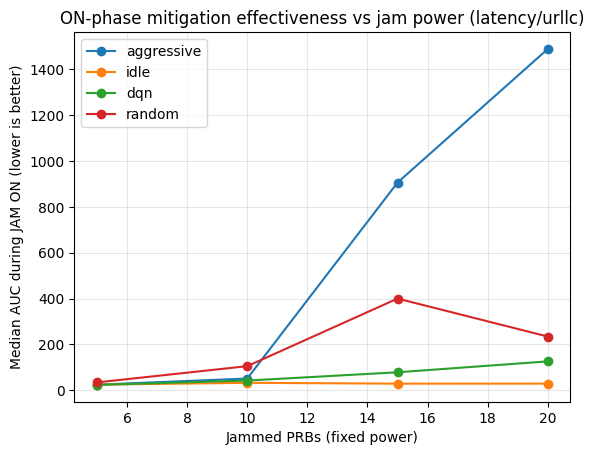

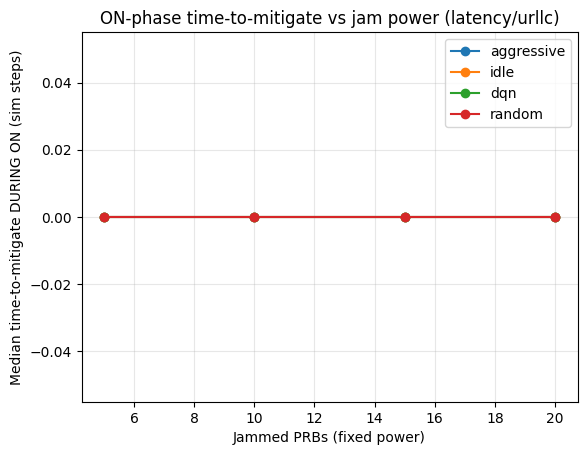

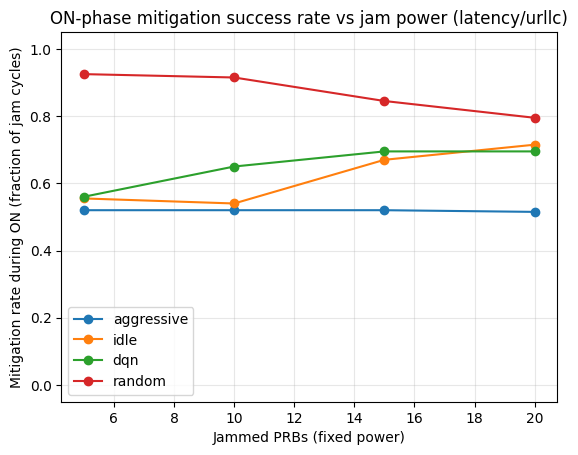

In [39]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

# =========================
# USER CONFIG
# =========================
ROOT = Path("../../tb_logs/res_validator")   # .../backend/tb_logs/res_validator
POLICIES = ["aggressive", "idle", "dqn", "random"]
POWERS = [5, 10, 15, 20]

METRIC_TAG = "latency/urllc"                # or "throughput/embb_mbps"
JAM_TAG = "prb/effective_ratio"

# TB step is SIMULATOR STEP in your setup
EP_LEN_SIM = 10000                          # sim steps per episode (you said 10000)

# Jam detection
JAM_THRESHOLD = 0.999                       # jam if eff_ratio < threshold

# Baseline windows (in sim steps) — very local if set to 2
W_PRE = 10
W_END = 10

# ON-phase mitigation stability + tolerance
K_CONSEC = 5
EPS = 0.05

LOWER_IS_BETTER = True   # True for latency, False for throughput


# =========================
# TB reader
# =========================
def read_tb_scalar(event_file: Path, tags):
    tags = set(tags)
    out = {t: [] for t in tags}
    for rec in tf_record.tf_record_iterator(str(event_file)):
        e = Event.FromString(rec)
        if not e.summary.value:
            continue
        step = int(e.step)
        for v in e.summary.value:
            if v.tag in tags:
                out[v.tag].append((step, float(v.simple_value)))

    dfs = {}
    for t, rows in out.items():
        if not rows:
            dfs[t] = pd.DataFrame(columns=["step", "value"])
        else:
            df = pd.DataFrame(rows, columns=["step", "value"]).dropna()
            df = df.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
            dfs[t] = df
    return dfs


# =========================
# Jam segmentation helpers
# =========================
def segment_bool_runs(is_true: np.ndarray):
    """Return list of (start_idx, end_idx_exclusive) for True-runs."""
    if len(is_true) == 0:
        return []
    x = is_true.astype(np.int8)
    d = np.diff(x, prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends = np.where(d == -1)[0]
    return list(zip(starts, ends))

def first_k_consecutive_true(mask: np.ndarray, k: int):
    """First index i such that mask[i:i+k] are all True. None if not found."""
    if k <= 1:
        idx = np.where(mask)[0]
        return int(idx[0]) if len(idx) else None
    if len(mask) < k:
        return None
    s = np.convolve(mask.astype(np.int32), np.ones(k, dtype=np.int32), mode="valid")
    hits = np.where(s == k)[0]
    return int(hits[0]) if len(hits) else None


# =========================
# Nested event file finder (your folder structure)
# =========================
def find_event_file_under_test_folder(test_folder: Path):
    evs = sorted(test_folder.rglob("events.out.tfevents.*"))
    if not evs:
        return None
    evs = sorted(evs, key=lambda p: (p.stat().st_mtime, p.stat().st_size))
    return evs[-1]


# =========================
# Episode-aware ON-phase mitigation metrics
# =========================
def compute_on_phase_metrics_episode_aware(df_metric, df_jam, policy, power, run_id):
    """
    Computes mitigation effectiveness during JAM ON window:
      - auc_on: sum of relative harm during ON (lower is better)
      - t_mitigate_on_sim_steps: time from jam start until metric is back within (1±eps)*X
        for K_CONSEC consecutive steps *within the ON window* (inf if never)
    Also computes (optional):
      - t_recover_off_sim_steps: recovery after jam ends (same threshold, within OFF window)
    """
    if df_metric.empty or df_jam.empty:
        return pd.DataFrame()

    # Align by step
    df = df_metric.rename(columns={"value": "metric"}).merge(
        df_jam.rename(columns={"value": "eff"}),
        on="step", how="inner"
    ).sort_values("step").reset_index(drop=True)

    if df.empty:
        return pd.DataFrame()

    # Episode index based on fixed sim-step length
    step0 = int(df["step"].iloc[0])
    df["episode_idx"] = ((df["step"] - step0) // EP_LEN_SIM).astype(int)

    rows = []

    for ep_idx, ep in df.groupby("episode_idx", sort=True):
        ep = ep.reset_index(drop=True)
        if len(ep) < 10:
            continue

        steps = ep["step"].to_numpy()
        metric = ep["metric"].to_numpy()
        eff = ep["eff"].to_numpy()

        is_jam = eff < JAM_THRESHOLD
        jam_runs = segment_bool_runs(is_jam)

        for j, (s_idx, e_idx) in enumerate(jam_runs):
            if e_idx <= s_idx:
                continue

            # ---- baseline X right before jam (within episode) ----
            pre_start = max(0, s_idx - W_PRE)
            # pre_slice = metric[pre_start:s_idx]
            # X = float(np.nanmedian(pre_slice)) if len(pre_slice) else float(metric[s_idx])
            # if np.isnan(X) or X == 0:
            #     continue
            pre_slice = metric[pre_start:s_idx]

            # robust: ignore zeros for latency baselines
            if LOWER_IS_BETTER:
                pre_slice = pre_slice[pre_slice > 0]

            if len(pre_slice) >= 1:
                X = float(np.nanmedian(pre_slice))
            else:
                # fallback: search backward a bit more (up to 200 samples)
                back = metric[max(0, s_idx-200):s_idx]
                if LOWER_IS_BETTER:
                    back = back[back > 0]
                X = float(np.nanmedian(back)) if len(back) else np.nan

            if np.isnan(X) or X == 0:
                # last resort: don't drop the cycle; set X to a tiny epsilon
                X = 1e-12


            # ---- end-of-jam Y (optional degradation) ----
            end_start = max(s_idx, e_idx - W_END)
            Y = float(np.nanmedian(metric[end_start:e_idx]))

            # ON and OFF slices
            on_slice = metric[s_idx:e_idx]  # jam ON
            next_start = jam_runs[j + 1][0] if (j + 1) < len(jam_runs) else len(ep)
            off_slice = metric[e_idx:next_start]  # jam OFF (until next jam)

            # Threshold relative to X (local baseline)
            if LOWER_IS_BETTER:
                thresh = (1.0 + EPS) * X
                good_on = on_slice <= thresh
                good_off = off_slice <= thresh

                # Relative harm at each step during ON: max(0, metric/X - 1)
                harm_on = np.maximum(0.0, (on_slice / (X + 1e-12)) - 1.0)
                auc_on = float(np.nansum(harm_on))

                # sign-aware degradation at end of jam
                degradation = Y - X
                rel_deg = (Y - X) / (X + 1e-12)
            else:
                thresh = (1.0 - EPS) * X
                good_on = on_slice >= thresh
                good_off = off_slice >= thresh

                # Relative harm at each step during ON: max(0, 1 - metric/X)
                harm_on = np.maximum(0.0, 1.0 - (on_slice / (X + 1e-12)))
                auc_on = float(np.nansum(harm_on))

                degradation = X - Y
                rel_deg = (X - Y) / (X + 1e-12)

            # ---- time-to-mitigate DURING ON (within ON window) ----
            mit_offset = first_k_consecutive_true(good_on, K_CONSEC)
            if mit_offset is None:
                mitigated_on = False
                t_mit_on = np.inf
                mit_value = np.nan
            else:
                mitigated_on = True
                mit_idx = s_idx + mit_offset
                t_mit_on = float(steps[mit_idx] - steps[s_idx])
                mit_value = float(metric[mit_idx])

            # ---- (optional) time-to-recover during OFF ----
            rec_offset = first_k_consecutive_true(good_off, K_CONSEC)
            if rec_offset is None:
                recovered_off = False
                t_rec_off = np.inf
            else:
                recovered_off = True
                rec_idx = e_idx + rec_offset
                t_rec_off = float(steps[rec_idx] - steps[e_idx - 1])

            rows.append({
                "policy": policy,
                "power": power,
                "run_id": run_id,
                "episode_idx": int(ep_idx),
                "jam_idx_in_episode": int(j),

                "jam_start_step": float(steps[s_idx]),
                "jam_end_step": float(steps[e_idx - 1]),

                "baseline_X": X,
                "threshold": thresh,

                "endjam_Y": Y,
                "degradation": degradation,
                "rel_degradation": rel_deg,

                # ON-phase mitigation metrics
                "auc_on": auc_on,
                "mitigated_on": mitigated_on,
                "t_mitigate_on_sim_steps": t_mit_on,
                "mitigate_value": mit_value,

                # OFF-phase (optional)
                "recovered_off": recovered_off,
                "t_recover_off_sim_steps": t_rec_off,

                "n_jams_in_episode": int(len(jam_runs)),
            })

    return pd.DataFrame(rows)



# =========================
# Main loop: policy x fixed power
# =========================
all_cycles = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    if not policy_dir.exists():
        print(f"[WARN] policy folder missing: {policy_dir}")
        continue

    for pwr in POWERS:
        test_name_suffix = f"_jam_fixed_{pwr}"
        matches = sorted([p for p in policy_dir.iterdir()
                          if p.is_dir() and p.name.endswith(test_name_suffix)])
        if not matches:
            print(f"[WARN] missing test folder for {policy} power={pwr}")
            continue

        test_folder = matches[0]
        ev = find_event_file_under_test_folder(test_folder)
        if ev is None:
            print(f"[WARN] no event file found under {test_folder}")
            continue

        dfs = read_tb_scalar(ev, tags=[METRIC_TAG, JAM_TAG])
        df_cycles = compute_on_phase_metrics_episode_aware(
            dfs[METRIC_TAG], dfs[JAM_TAG],
            policy=policy, power=pwr, run_id=str(test_folder)
        )
        if not df_cycles.empty:
            all_cycles.append(df_cycles)

df_cycles_all = pd.concat(all_cycles, ignore_index=True) if all_cycles else pd.DataFrame()
print("Total jam cycles:", len(df_cycles_all))
display(df_cycles_all.head(10))

# Optional sanity: should be ~4 jams per episode
if not df_cycles_all.empty:
    print("Jam runs per episode (expect ~4):")
    display(
        df_cycles_all.groupby(["policy", "power", "episode_idx"])["n_jams_in_episode"]
        .first()
        .value_counts()
        .sort_index()
    )


# =========================
# Aggregate per policy x power
# =========================
if not df_cycles_all.empty:
    tmp = df_cycles_all.copy()

    # Clean inf for aggregation
    tmp["t_mit_clean"] = tmp["t_mitigate_on_sim_steps"].replace([np.inf, -np.inf], np.nan)
    tmp["t_rec_off_clean"] = tmp["t_recover_off_sim_steps"].replace([np.inf, -np.inf], np.nan)

    df_agg = (
        tmp.groupby(["policy", "power"])
           .agg(
               n_cycles=("jam_idx_in_episode", "count"),
               n_episodes=("episode_idx", "nunique"),

               # ON-phase
               median_auc_on=("auc_on", "median"),
               mean_auc_on=("auc_on", "mean"),
               mitigation_rate=("mitigated_on", "mean"),
               median_t_mitigate_on=("t_mit_clean", "median"),

               # Optional OFF-phase
               median_t_recover_off=("t_rec_off_clean", "median"),
               recovery_rate_off=("recovered_off", "mean"),

               # degradation at jam end (for context)
               median_rel_deg=("rel_degradation", "median"),
           )
           .reset_index()
           .sort_values(["policy", "power"])
    )
    display(df_agg)

    # =========================
    # Plots (ON-phase = main)
    # =========================

    # 1) AUC_on vs power (main mitigation effectiveness)
    plt.figure()
    for policy in POLICIES:
        sub = df_agg[df_agg["policy"] == policy].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_auc_on"], marker="o", label=policy)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median AUC during JAM ON (lower is better)")
    plt.title(f"ON-phase mitigation effectiveness vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 2) Mitigation time during ON (median over cycles that mitigated)
    plt.figure()
    for policy in POLICIES:
        sub = df_agg[df_agg["policy"] == policy].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_t_mitigate_on"], marker="o", label=policy)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median time-to-mitigate DURING ON (sim steps)")
    plt.title(f"ON-phase time-to-mitigate vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 3) Mitigation rate during ON
    plt.figure()
    for policy in POLICIES:
        sub = df_agg[df_agg["policy"] == policy].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["mitigation_rate"], marker="o", label=policy)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Mitigation rate during ON (fraction of jam cycles)")
    plt.title(f"ON-phase mitigation success rate vs jam power ({METRIC_TAG})")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


Total jam cycles: 3200


,policy,power,run_id,episode_idx,jam_idx_in_episode,jam_start_step,jam_end_step,baseline_X,threshold,endjam_Y,degradation,rel_degradation,auc_on,mitigated_on,t_mitigate_on_sim_steps,mitigate_value,recovered_off,t_recover_off_sim_steps,n_jams_in_episode
0,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,0,10.0,1240.0,95.856003,91.063203,96.0,-0.143997,-0.001502,1.032507e-14,True,0.0,95.856003,True,10.0,4
1,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,1,2500.0,3740.0,96.000000,91.200000,96.0,0.000000,0.000000,2.999942e-03,True,0.0,95.856003,True,10.0,4
2,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,2,5000.0,6240.0,96.000000,91.200000,96.0,0.000000,0.000000,2.999942e-03,True,0.0,95.856003,True,10.0,4
3,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,0,3,7500.0,8740.0,96.000000,91.200000,96.0,0.000000,0.000000,2.999942e-03,True,0.0,95.856003,True,10.0,4
4,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,0,10010.0,11240.0,96.000000,91.200000,96.0,0.000000,0.000000,1.280309e-12,True,0.0,96.000000,True,10.0,4
5,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,1,12500.0,13740.0,96.000000,91.200000,96.0,0.000000,0.000000,1.290634e-12,True,0.0,96.000000,True,10.0,4
6,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,2,15000.0,16240.0,96.000000,91.200000,96.0,0.000000,0.000000,1.290634e-12,True,0.0,96.000000,True,10.0,4
7,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,1,3,17500.0,18740.0,96.000000,91.200000,96.0,0.000000,0.000000,1.290634e-12,True,0.0,96.000000,True,10.0,4
8,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,2,0,20010.0,21240.0,96.000000,91.200000,96.0,0.000000,0.000000,1.280309e-12,True,0.0,96.000000,True,10.0,4
9,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,2,1,22500.0,23740.0,96.000000,91.200000,96.0,0.000000,0.000000,1.290634e-12,True,0.0,96.000000,True,10.0,4


Jam runs per episode (expect ~4):


n_jams_in_episode
4    800
Name: count, dtype: int64

,policy,power,n_cycles,n_episodes,median_auc_on,mean_auc_on,mitigation_rate,median_t_mitigate_on,median_t_recover_off,recovery_rate_off,median_rel_deg
0,aggressive,5,200,50,1.290634e-12,0.058136,1.000,0.0,10.0,1.0,0.000000
1,aggressive,10,200,50,1.290634e-12,0.063713,1.000,0.0,10.0,1.0,0.000000
2,aggressive,15,200,50,2.175845e-03,0.096658,1.000,0.0,10.0,1.0,0.000000
3,aggressive,20,200,50,2.137498e-02,0.252430,1.000,0.0,10.0,1.0,0.000000
4,dqn,5,200,50,1.290634e-12,0.471964,1.000,0.0,10.0,1.0,0.000000
5,dqn,10,200,50,1.290634e-12,1.180794,0.980,0.0,10.0,1.0,0.000000
6,dqn,15,200,50,8.749962e-03,2.061710,0.940,0.0,10.0,1.0,0.000000
7,dqn,20,200,50,2.020380e-01,3.258307,0.845,0.0,10.0,1.0,0.000000
8,idle,5,200,50,1.290634e-12,0.518044,1.000,0.0,10.0,1.0,0.000000
9,idle,10,200,50,1.290634e-12,1.639808,0.945,0.0,10.0,1.0,0.000000


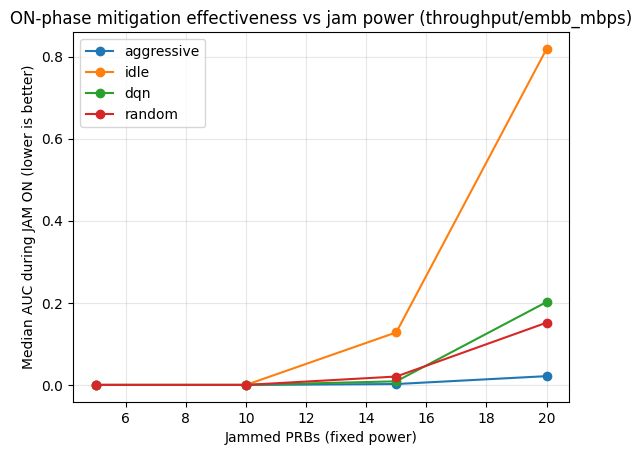

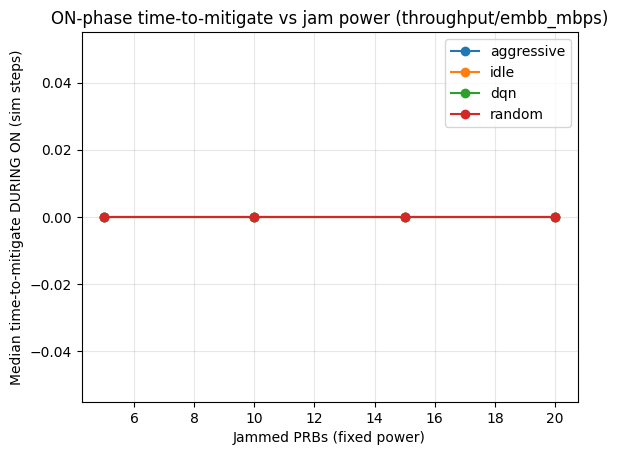

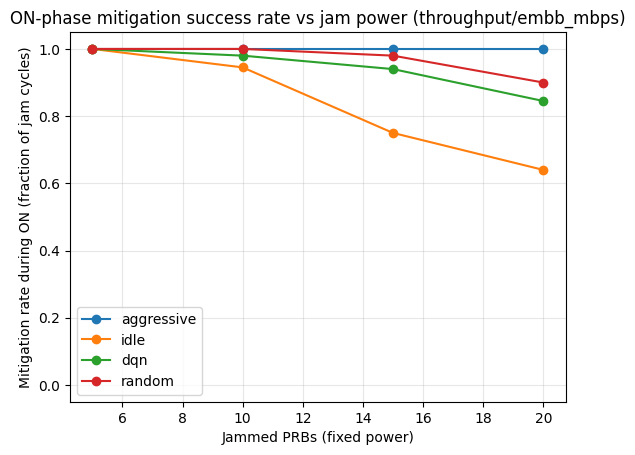

In [29]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

# =========================
# USER CONFIG
# =========================
ROOT = Path("../../tb_logs/res_validator")   # .../backend/tb_logs/res_validator
POLICIES = ["aggressive", "idle", "dqn", "random"]
POWERS = [5, 10, 15, 20]

#METRIC_TAG = "latency/urllc"                # or "throughput/embb_mbps"
JAM_TAG = "prb/effective_ratio"

# TB step is SIMULATOR STEP in your setup
EP_LEN_SIM = 10000                          # sim steps per episode (you said 10000)

# Jam detection
JAM_THRESHOLD = 0.999                       # jam if eff_ratio < threshold

# Baseline windows (in sim steps) — very local if set to 2
W_PRE = 2
W_END = 2

# ON-phase mitigation stability + tolerance
K_CONSEC = 3
EPS = 0.05

#LOWER_IS_BETTER = True   # True for latency, False for throughput

METRIC_TAG = "throughput/embb_mbps"
LOWER_IS_BETTER = False

# =========================
# TB reader
# =========================
def read_tb_scalar(event_file: Path, tags):
    tags = set(tags)
    out = {t: [] for t in tags}
    for rec in tf_record.tf_record_iterator(str(event_file)):
        e = Event.FromString(rec)
        if not e.summary.value:
            continue
        step = int(e.step)
        for v in e.summary.value:
            if v.tag in tags:
                out[v.tag].append((step, float(v.simple_value)))

    dfs = {}
    for t, rows in out.items():
        if not rows:
            dfs[t] = pd.DataFrame(columns=["step", "value"])
        else:
            df = pd.DataFrame(rows, columns=["step", "value"]).dropna()
            df = df.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
            dfs[t] = df
    return dfs


# =========================
# Jam segmentation helpers
# =========================
def segment_bool_runs(is_true: np.ndarray):
    """Return list of (start_idx, end_idx_exclusive) for True-runs."""
    if len(is_true) == 0:
        return []
    x = is_true.astype(np.int8)
    d = np.diff(x, prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends = np.where(d == -1)[0]
    return list(zip(starts, ends))

def first_k_consecutive_true(mask: np.ndarray, k: int):
    """First index i such that mask[i:i+k] are all True. None if not found."""
    if k <= 1:
        idx = np.where(mask)[0]
        return int(idx[0]) if len(idx) else None
    if len(mask) < k:
        return None
    s = np.convolve(mask.astype(np.int32), np.ones(k, dtype=np.int32), mode="valid")
    hits = np.where(s == k)[0]
    return int(hits[0]) if len(hits) else None


# =========================
# Nested event file finder (your folder structure)
# =========================
def find_event_file_under_test_folder(test_folder: Path):
    evs = sorted(test_folder.rglob("events.out.tfevents.*"))
    if not evs:
        return None
    evs = sorted(evs, key=lambda p: (p.stat().st_mtime, p.stat().st_size))
    return evs[-1]


# =========================
# Episode-aware ON-phase mitigation metrics
# =========================
def compute_on_phase_metrics_episode_aware(df_metric, df_jam, policy, power, run_id):
    """
    Computes mitigation effectiveness during JAM ON window:
      - auc_on: sum of relative harm during ON (lower is better)
      - t_mitigate_on_sim_steps: time from jam start until metric is back within (1±eps)*X
        for K_CONSEC consecutive steps *within the ON window* (inf if never)
    Also computes (optional):
      - t_recover_off_sim_steps: recovery after jam ends (same threshold, within OFF window)
    """
    if df_metric.empty or df_jam.empty:
        return pd.DataFrame()

    # Align by step
    df = df_metric.rename(columns={"value": "metric"}).merge(
        df_jam.rename(columns={"value": "eff"}),
        on="step", how="inner"
    ).sort_values("step").reset_index(drop=True)

    if df.empty:
        return pd.DataFrame()

    # Episode index based on fixed sim-step length
    step0 = int(df["step"].iloc[0])
    df["episode_idx"] = ((df["step"] - step0) // EP_LEN_SIM).astype(int)

    rows = []

    for ep_idx, ep in df.groupby("episode_idx", sort=True):
        ep = ep.reset_index(drop=True)
        if len(ep) < 10:
            continue

        steps = ep["step"].to_numpy()
        metric = ep["metric"].to_numpy()
        eff = ep["eff"].to_numpy()

        is_jam = eff < JAM_THRESHOLD
        jam_runs = segment_bool_runs(is_jam)

        for j, (s_idx, e_idx) in enumerate(jam_runs):
            if e_idx <= s_idx:
                continue

            # ---- baseline X right before jam (within episode) ----
            pre_start = max(0, s_idx - W_PRE)
            pre_slice = metric[pre_start:s_idx]
            X = float(np.nanmedian(pre_slice)) if len(pre_slice) else float(metric[s_idx])
            if np.isnan(X) or X == 0:
                continue

            # ---- end-of-jam Y (optional degradation) ----
            end_start = max(s_idx, e_idx - W_END)
            Y = float(np.nanmedian(metric[end_start:e_idx]))

            # ON and OFF slices
            on_slice = metric[s_idx:e_idx]  # jam ON
            next_start = jam_runs[j + 1][0] if (j + 1) < len(jam_runs) else len(ep)
            off_slice = metric[e_idx:next_start]  # jam OFF (until next jam)

            # Threshold relative to X (local baseline)
            if LOWER_IS_BETTER:
                thresh = (1.0 + EPS) * X
                good_on = on_slice <= thresh
                good_off = off_slice <= thresh

                # Relative harm at each step during ON: max(0, metric/X - 1)
                harm_on = np.maximum(0.0, (on_slice / (X + 1e-12)) - 1.0)
                auc_on = float(np.nansum(harm_on))

                # sign-aware degradation at end of jam
                degradation = Y - X
                rel_deg = (Y - X) / (X + 1e-12)
            else:
                thresh = (1.0 - EPS) * X
                good_on = on_slice >= thresh
                good_off = off_slice >= thresh

                # Relative harm at each step during ON: max(0, 1 - metric/X)
                harm_on = np.maximum(0.0, 1.0 - (on_slice / (X + 1e-12)))
                auc_on = float(np.nansum(harm_on))

                degradation = X - Y
                rel_deg = (X - Y) / (X + 1e-12)

            # ---- time-to-mitigate DURING ON (within ON window) ----
            mit_offset = first_k_consecutive_true(good_on, K_CONSEC)
            if mit_offset is None:
                mitigated_on = False
                t_mit_on = np.inf
                mit_value = np.nan
            else:
                mitigated_on = True
                mit_idx = s_idx + mit_offset
                t_mit_on = float(steps[mit_idx] - steps[s_idx])
                mit_value = float(metric[mit_idx])

            # ---- (optional) time-to-recover during OFF ----
            rec_offset = first_k_consecutive_true(good_off, K_CONSEC)
            if rec_offset is None:
                recovered_off = False
                t_rec_off = np.inf
            else:
                recovered_off = True
                rec_idx = e_idx + rec_offset
                t_rec_off = float(steps[rec_idx] - steps[e_idx - 1])

            rows.append({
                "policy": policy,
                "power": power,
                "run_id": run_id,
                "episode_idx": int(ep_idx),
                "jam_idx_in_episode": int(j),

                "jam_start_step": float(steps[s_idx]),
                "jam_end_step": float(steps[e_idx - 1]),

                "baseline_X": X,
                "threshold": thresh,

                "endjam_Y": Y,
                "degradation": degradation,
                "rel_degradation": rel_deg,

                # ON-phase mitigation metrics
                "auc_on": auc_on,
                "mitigated_on": mitigated_on,
                "t_mitigate_on_sim_steps": t_mit_on,
                "mitigate_value": mit_value,

                # OFF-phase (optional)
                "recovered_off": recovered_off,
                "t_recover_off_sim_steps": t_rec_off,

                "n_jams_in_episode": int(len(jam_runs)),
            })

    return pd.DataFrame(rows)


# =========================
# Main loop: policy x fixed power
# =========================
all_cycles = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    if not policy_dir.exists():
        print(f"[WARN] policy folder missing: {policy_dir}")
        continue

    for pwr in POWERS:
        test_name_suffix = f"_jam_fixed_{pwr}"
        matches = sorted([p for p in policy_dir.iterdir()
                          if p.is_dir() and p.name.endswith(test_name_suffix)])
        if not matches:
            print(f"[WARN] missing test folder for {policy} power={pwr}")
            continue

        test_folder = matches[0]
        ev = find_event_file_under_test_folder(test_folder)
        if ev is None:
            print(f"[WARN] no event file found under {test_folder}")
            continue

        dfs = read_tb_scalar(ev, tags=[METRIC_TAG, JAM_TAG])
        df_cycles = compute_on_phase_metrics_episode_aware(
            dfs[METRIC_TAG], dfs[JAM_TAG],
            policy=policy, power=pwr, run_id=str(test_folder)
        )
        if not df_cycles.empty:
            all_cycles.append(df_cycles)

df_cycles_all = pd.concat(all_cycles, ignore_index=True) if all_cycles else pd.DataFrame()
print("Total jam cycles:", len(df_cycles_all))
display(df_cycles_all.head(10))

# Optional sanity: should be ~4 jams per episode
if not df_cycles_all.empty:
    print("Jam runs per episode (expect ~4):")
    display(
        df_cycles_all.groupby(["policy", "power", "episode_idx"])["n_jams_in_episode"]
        .first()
        .value_counts()
        .sort_index()
    )


# =========================
# Aggregate per policy x power
# =========================
if not df_cycles_all.empty:
    tmp = df_cycles_all.copy()

    # Clean inf for aggregation
    tmp["t_mit_clean"] = tmp["t_mitigate_on_sim_steps"].replace([np.inf, -np.inf], np.nan)
    tmp["t_rec_off_clean"] = tmp["t_recover_off_sim_steps"].replace([np.inf, -np.inf], np.nan)

    df_agg = (
        tmp.groupby(["policy", "power"])
           .agg(
               n_cycles=("jam_idx_in_episode", "count"),
               n_episodes=("episode_idx", "nunique"),

               # ON-phase
               median_auc_on=("auc_on", "median"),
               mean_auc_on=("auc_on", "mean"),
               mitigation_rate=("mitigated_on", "mean"),
               median_t_mitigate_on=("t_mit_clean", "median"),

               # Optional OFF-phase
               median_t_recover_off=("t_rec_off_clean", "median"),
               recovery_rate_off=("recovered_off", "mean"),

               # degradation at jam end (for context)
               median_rel_deg=("rel_degradation", "median"),
           )
           .reset_index()
           .sort_values(["policy", "power"])
    )
    display(df_agg)

    # =========================
    # Plots (ON-phase = main)
    # =========================

    # 1) AUC_on vs power (main mitigation effectiveness)
    plt.figure()
    for policy in POLICIES:
        sub = df_agg[df_agg["policy"] == policy].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_auc_on"], marker="o", label=policy)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median AUC during JAM ON (lower is better)")
    plt.title(f"ON-phase mitigation effectiveness vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 2) Mitigation time during ON (median over cycles that mitigated)
    plt.figure()
    for policy in POLICIES:
        sub = df_agg[df_agg["policy"] == policy].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_t_mitigate_on"], marker="o", label=policy)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median time-to-mitigate DURING ON (sim steps)")
    plt.title(f"ON-phase time-to-mitigate vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 3) Mitigation rate during ON
    plt.figure()
    for policy in POLICIES:
        sub = df_agg[df_agg["policy"] == policy].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["mitigation_rate"], marker="o", label=policy)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Mitigation rate during ON (fraction of jam cycles)")
    plt.title(f"ON-phase mitigation success rate vs jam power ({METRIC_TAG})")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


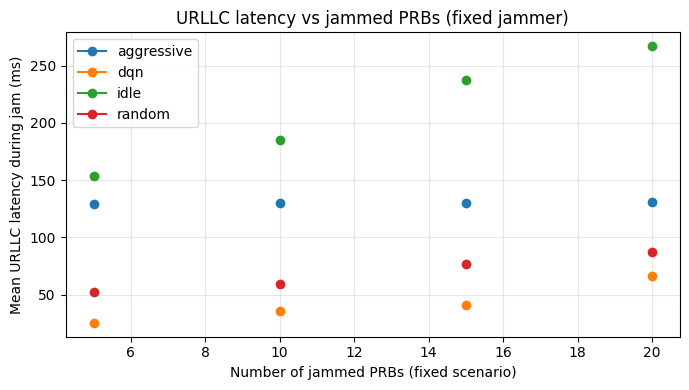

In [7]:
plt.figure(figsize=(7, 4))

for policy, g in df.groupby("policy"):
    g = g.sort_values("jam_prb")
    plt.plot(g["jam_prb"], g["mean_latency_ms"], marker="o", label=policy)

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean URLLC latency during jam (ms)")
plt.title("URLLC latency vs jammed PRBs (fixed jammer)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


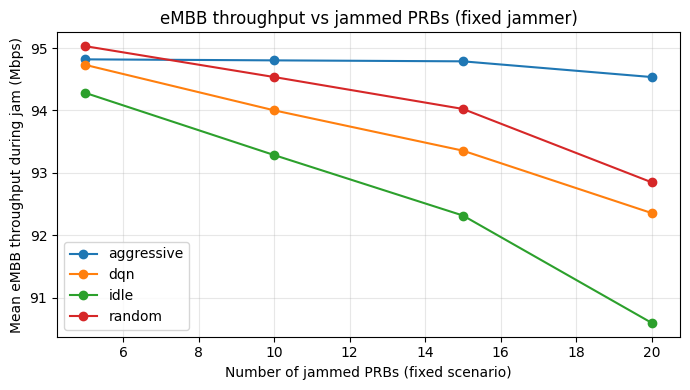

In [8]:
plt.figure(figsize=(7, 4))

for policy, g in df_thr.groupby("policy"):
    g = g.sort_values("jam_prb")
    plt.plot(g["jam_prb"], g["mean_embb_mbps"], marker="o", label=policy)

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean eMBB throughput during jam (Mbps)")
plt.title("eMBB throughput vs jammed PRBs (fixed jammer)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


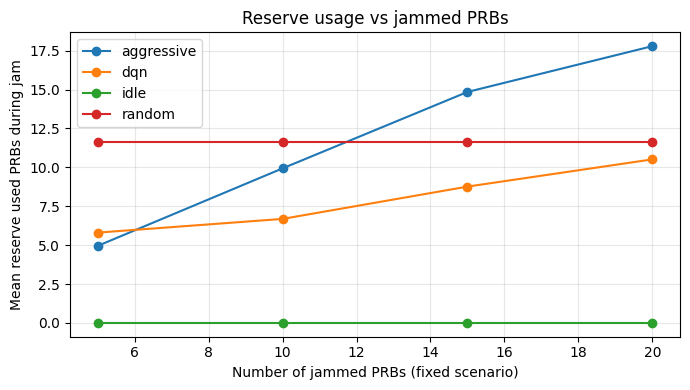

In [9]:
plt.figure(figsize=(7,4))
for policy, g in df_prb.groupby("policy"):
    g = g.sort_values("jam_prb")
    plt.plot(g["jam_prb"], g["reserve_used_prb_mean"], marker="o", label=policy)

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean reserve used PRBs during jam")
plt.title("Reserve usage vs jammed PRBs")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


[INFO] Indexing event files under: /home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator
[INFO] aggressive: 9 event files found
[INFO] idle: 9 event files found
[INFO] dqn: 9 event files found
[INFO] random: 9 event files found
[1/16] policy=aggressive pattern=fixed      -> loading events.out.tfevents.1769113418.elahe-LEGION-T7-34IAS10.1104750.0
[2/16] policy=aggressive pattern=increasing -> loading events.out.tfevents.1769116561.elahe-LEGION-T7-34IAS10.1106150.0
[3/16] policy=aggressive pattern=decreasing -> loading events.out.tfevents.1769110265.elahe-LEGION-T7-34IAS10.1103158.0
[4/16] policy=aggressive pattern=random     -> loading events.out.tfevents.1769119732.elahe-LEGION-T7-34IAS10.1109338.0
[5/16] policy=idle       pattern=fixed      -> loading events.out.tfevents.1769114978.elahe-LEGION-T7-34IAS10.1105370.0
[6/16] policy=idle       pattern=increasing -> loading events.out.tfevents.1769118129.elahe-LEGION-T7-34IAS10.1107508.0
[7/16] policy=idle  

/tmp/ipykernel_1113248/2720928440.py:296: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  lat_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_lat_ms", aggfunc="mean")


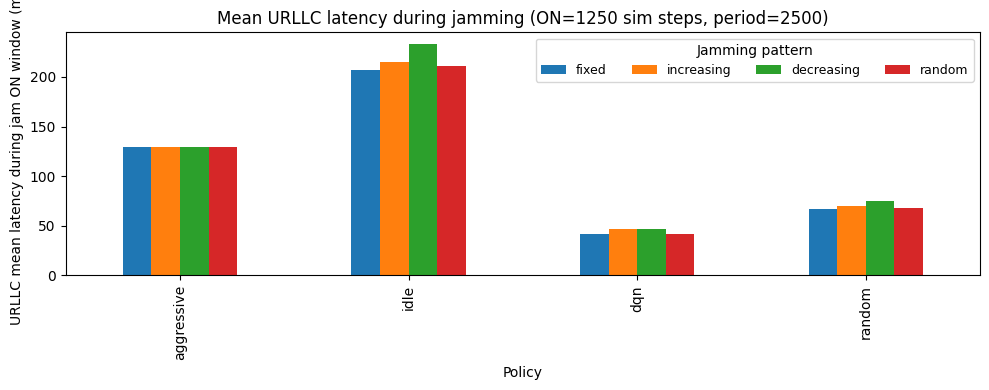

/tmp/ipykernel_1113248/2720928440.py:305: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  thr_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_thr_mbps", aggfunc="mean")


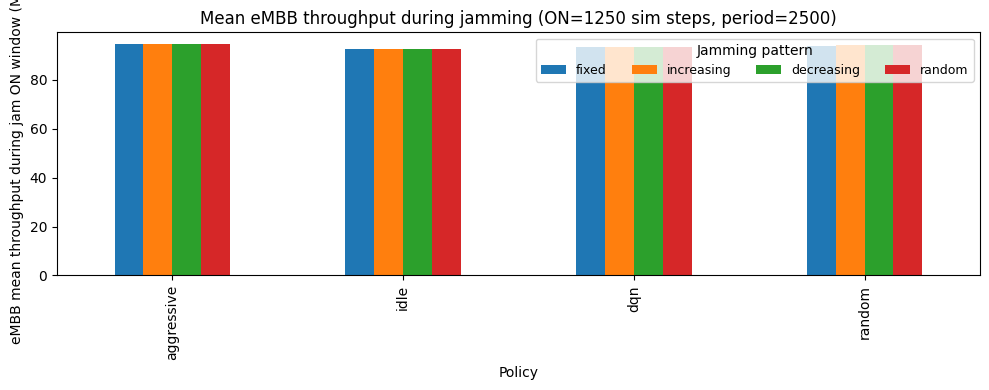


[OK] Saved CSV + plots to: /home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator/_plots


<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

In [11]:
#!/usr/bin/env python3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing import event_accumulator

# -----------------------------
# User settings
# -----------------------------
ROOT = Path("../../tb_logs/res_validator")  # <-- change if needed

POLICIES = ["aggressive", "idle", "dqn", "random"]#, "qrdqn"]
PATTERNS = ["fixed", "increasing", "decreasing", "random"]

JAM_THRESHOLD = 0.999
DEADLINE_MS = 1.0

# Your jammer (SIM steps)
JAM_ON_STEPS_SIM = 1250
JAM_PERIOD_STEPS_SIM = 2500

PRE_STEPS = 0
POST_EXTRA = 0

# -----------------------------
# Helpers
# -----------------------------
def infer_tb_step_stride(steps: np.ndarray) -> int:
    if steps is None or len(steps) < 3:
        return 1
    d = np.diff(np.asarray(steps, dtype=int))
    d = d[d > 0]
    if len(d) == 0:
        return 1
    return max(1, int(np.median(d)))

def sim_to_tb_steps(sim_steps: int, tb_stride: int) -> int:
    return int(np.ceil(sim_steps / float(tb_stride)))

def merge_asof_by_step(base: pd.DataFrame, other: pd.DataFrame, tolerance: int) -> pd.DataFrame:
    if other is None or other.empty:
        return base
    a = base.sort_values("step").copy()
    b = other.sort_values("step").copy()
    merged = pd.merge_asof(a, b, on="step", direction="nearest", tolerance=tolerance, suffixes=("", "_y"))
    if "wall_time_y" in merged.columns and "wall_time" in merged.columns:
        merged.drop(columns=["wall_time_y"], inplace=True)
    return merged

def detect_jam_starts(df: pd.DataFrame, min_gap_tb_steps: int) -> list[int]:
    if df.empty or "effective_prb_ratio" not in df.columns:
        return []
    steps = df["step"].to_numpy(dtype=int)
    jammed = (df["effective_prb_ratio"].to_numpy() < JAM_THRESHOLD).astype(np.int32)

    starts = []
    prev = 0
    last_start_step = -10**18
    for i in range(len(jammed)):
        if jammed[i] == 1 and prev == 0:
            s0 = int(steps[i])
            if s0 - last_start_step >= min_gap_tb_steps:
                starts.append(s0)
                last_start_step = s0
        prev = jammed[i]
    return starts

def event_aligned_mean_by_index(df: pd.DataFrame, col: str, start_steps: list[int], pre: int, post: int) -> pd.DataFrame:
    if df.empty or col not in df.columns or not start_steps:
        return pd.DataFrame(columns=["t_rel", "mean", "std", "n"])

    d = df[["step", col]].dropna().sort_values("step").reset_index(drop=True)
    if d.empty:
        return pd.DataFrame(columns=["t_rel", "mean", "std", "n"])

    steps = d["step"].to_numpy(dtype=int)
    vals = d[col].to_numpy(dtype=float)

    t_rels = np.arange(-pre, post, dtype=int)
    aligned = []

    for s0 in start_steps:
        i0 = int(np.searchsorted(steps, s0))
        if i0 >= len(steps):
            i0 = len(steps) - 1
        if i0 > 0 and abs(steps[i0] - s0) > abs(steps[i0 - 1] - s0):
            i0 -= 1

        row = []
        for tr in t_rels:
            i = i0 + tr
            row.append(vals[i] if (0 <= i < len(vals)) else np.nan)
        aligned.append(row)

    A = np.asarray(aligned, dtype=float)

    n = np.sum(np.isfinite(A), axis=0)
    mean = np.full(A.shape[1], np.nan)
    std  = np.full(A.shape[1], np.nan)

    ok = n > 0
    if np.any(ok):
        mean[ok] = np.nanmean(A[:, ok], axis=0)
        std[ok]  = np.nanstd(A[:, ok], axis=0)

    return pd.DataFrame({"t_rel": t_rels, "mean": mean, "std": std, "n": n})

# -----------------------------
# FAST: index event files once
# -----------------------------
def index_event_files_by_policy(root: Path, policies: list[str]) -> dict[str, list[Path]]:
    """
    Returns: policy -> list of event files under that policy (one rglob per policy)
    """
    out = {}
    for pol in policies:
        pdir = root / pol
        if not pdir.exists():
            out[pol] = []
            continue
        evs = list(pdir.rglob("events.out.tfevents.*"))
        # newest first
        evs.sort(key=lambda p: p.stat().st_mtime, reverse=True)
        out[pol] = evs
    return out

def find_event_file_from_index(index: dict[str, list[Path]], policy: str, test_name: str) -> Path | None:
    """
    Uses pre-indexed list. Just scans the list in memory (fast).
    """
    for ev in index.get(policy, []):
        if test_name in str(ev.parent):
            return ev
    return None

# -----------------------------
# FAST: read all tags from ONE Reload
# -----------------------------
def read_scalars_once(event_file: Path, tags: list[str]) -> dict[str, pd.DataFrame]:
    """
    One EventAccumulator Reload, then pull all requested tags.
    Returns dict tag -> DataFrame(step, wall_time, value)
    """
    ea = event_accumulator.EventAccumulator(str(event_file), size_guidance={"scalars": 0})
    ea.Reload()

    available = set(ea.Tags().get("scalars", []))
    out = {}
    for tag in tags:
        if tag not in available:
            out[tag] = pd.DataFrame(columns=["step", "wall_time", "value"])
            continue
        evs = ea.Scalars(tag)
        df = pd.DataFrame(
            {"step": [e.step for e in evs], "wall_time": [e.wall_time for e in evs], "value": [e.value for e in evs]}
        ).sort_values("step")
        out[tag] = df
    return out

def load_one_run_fast(event_file: Path) -> pd.DataFrame | None:
    tags = ["latency/urllc", "throughput/embb_mbps", "prb/effective_ratio", "obs/reserve_used_prb"]
    scal = read_scalars_once(event_file, tags)

    lat = scal["latency/urllc"].rename(columns={"value": "latency_sec"})
    thr = scal["throughput/embb_mbps"].rename(columns={"value": "embb_mbps"})
    prb = scal["prb/effective_ratio"].rename(columns={"value": "effective_prb_ratio"})
    rsv = scal["obs/reserve_used_prb"].rename(columns={"value": "reserve_used_prb"})

    if lat.empty or thr.empty or prb.empty:
        return None

    tb_stride = infer_tb_step_stride(prb["step"].to_numpy())
    tolerance = max(1, tb_stride // 2)

    df = prb.copy()
    df = merge_asof_by_step(df, lat, tolerance=tolerance)
    df = merge_asof_by_step(df, thr, tolerance=tolerance)
    if not rsv.empty:
        df = merge_asof_by_step(df, rsv, tolerance=tolerance)
    else:
        df["reserve_used_prb"] = np.nan

    df["latency_ms"] = df["latency_sec"] * 1000.0
    df["tb_stride"] = tb_stride
    return df

# -----------------------------
# Main
# -----------------------------
print(f"[INFO] Indexing event files under: {ROOT.resolve()}")
ev_index = index_event_files_by_policy(ROOT, POLICIES)
for pol in POLICIES:
    print(f"[INFO] {pol}: {len(ev_index.get(pol, []))} event files found")

aligned_lat = {}
aligned_thr = {}
aligned_eff = {}
summary_rows = []

total_jobs = len(POLICIES) * len(PATTERNS)
job_i = 0

for policy in POLICIES:
    for pat in PATTERNS:
        job_i += 1
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_pattern_{pat}"
        ev = find_event_file_from_index(ev_index, policy, test_name)

        print(f"[{job_i}/{total_jobs}] policy={policy:<10} pattern={pat:<10} -> ", end="")
        if ev is None:
            print("NO EVENT FILE")
            summary_rows.append({
                "policy": policy, "pattern": pat, "n_jam_events": 0,
                "tb_stride": np.nan, "jam_on_tb_steps": np.nan, "period_tb_steps": np.nan,
                "jam_lat_ms": np.nan, "violation_pct": np.nan, "jam_thr_mbps": np.nan,
                "jam_reserve_used": np.nan, "event_file": None,
            })
            continue

        print(f"loading {ev.name}")

        df = load_one_run_fast(ev)
        if df is None:
            summary_rows.append({
                "policy": policy, "pattern": pat, "n_jam_events": 0,
                "tb_stride": np.nan, "jam_on_tb_steps": np.nan, "period_tb_steps": np.nan,
                "jam_lat_ms": np.nan, "violation_pct": np.nan, "jam_thr_mbps": np.nan,
                "jam_reserve_used": np.nan, "event_file": str(ev),
            })
            continue

        tb_stride = int(df["tb_stride"].iloc[0])
        jam_on_tb = sim_to_tb_steps(JAM_ON_STEPS_SIM, tb_stride)
        period_tb = sim_to_tb_steps(JAM_PERIOD_STEPS_SIM, tb_stride)

        PRE_TB = PRE_STEPS
        POST_TB = period_tb + POST_EXTRA
        MIN_GAP_TB = max(1, period_tb - 1)

        starts = detect_jam_starts(df, min_gap_tb_steps=MIN_GAP_TB)

        lat_al = event_aligned_mean_by_index(df, "latency_ms", starts, pre=PRE_TB, post=POST_TB)
        thr_al = event_aligned_mean_by_index(df, "embb_mbps", starts, pre=PRE_TB, post=POST_TB)
        eff_al = event_aligned_mean_by_index(df, "effective_prb_ratio", starts, pre=PRE_TB, post=POST_TB)

        aligned_lat[(pat, policy)] = lat_al
        aligned_thr[(pat, policy)] = thr_al
        aligned_eff[(pat, policy)] = eff_al

        # Summary during jam ON window [0, jam_on_tb)
        if not lat_al.empty:
            s = lat_al[(lat_al.t_rel >= 0) & (lat_al.t_rel < jam_on_tb)]["mean"].to_numpy()
            jam_lat_ms = float(np.nanmean(s)) if len(s) else np.nan
            violation_pct = float(np.mean(s > DEADLINE_MS) * 100.0) if len(s) else np.nan
        else:
            jam_lat_ms = np.nan
            violation_pct = np.nan

        if not thr_al.empty:
            s = thr_al[(thr_al.t_rel >= 0) & (thr_al.t_rel < jam_on_tb)]["mean"].to_numpy()
            jam_thr_mbps = float(np.nanmean(s)) if len(s) else np.nan
        else:
            jam_thr_mbps = np.nan

        df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
        jam_df = df[df["jammed"]]
        jam_reserve_used = float(jam_df["reserve_used_prb"].mean()) if not jam_df.empty else np.nan

        summary_rows.append({
            "policy": policy,
            "pattern": pat,
            "n_jam_events": len(starts),
            "tb_stride": tb_stride,
            "jam_on_tb_steps": jam_on_tb,
            "period_tb_steps": period_tb,
            "jam_lat_ms": jam_lat_ms,
            "violation_pct": violation_pct,
            "jam_thr_mbps": jam_thr_mbps,
            "jam_reserve_used": jam_reserve_used,
            "event_file": str(ev),
        })

summary_df = pd.DataFrame(summary_rows)
summary_df["policy"] = pd.Categorical(summary_df["policy"], categories=POLICIES, ordered=True)
summary_df["pattern"] = pd.Categorical(summary_df["pattern"], categories=PATTERNS, ordered=True)

print("\n=== Summary (head) ===")
print(summary_df.head(10))
print("\n=== Summary (full) ===")
print(summary_df)

# -----------------------------
# Bar charts
# -----------------------------
lat_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_lat_ms", aggfunc="mean")
ax = lat_pivot.plot(kind="bar", figsize=(10, 4))
ax.set_ylabel("URLLC mean latency during jam ON window (ms)")
ax.set_xlabel("Policy")
ax.set_title("Mean URLLC latency during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.show()

thr_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_thr_mbps", aggfunc="mean")
ax = thr_pivot.plot(kind="bar", figsize=(10, 4))
ax.set_ylabel("eMBB mean throughput during jam ON window (Mbps)")
ax.set_xlabel("Policy")
ax.set_title("Mean eMBB throughput during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.show()

# Save outputs
OUT_DIR = ROOT / "_plots"
OUT_DIR.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(OUT_DIR / "summary_latency_throughput.csv", index=False)

plt.figure(figsize=(10, 4))
ax = lat_pivot.plot(kind="bar")
ax.set_ylabel("URLLC mean latency during jam ON window (ms)")
ax.set_xlabel("Policy")
ax.set_title("Mean URLLC latency during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "barchart_latency_ms.png", dpi=200)
plt.close()

plt.figure(figsize=(10, 4))
ax = thr_pivot.plot(kind="bar")
ax.set_ylabel("eMBB mean throughput during jam ON window (Mbps)")
ax.set_xlabel("Policy")
ax.set_title("Mean eMBB throughput during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "barchart_throughput_mbps.png", dpi=200)
plt.close()

print(f"\n[OK] Saved CSV + plots to: {OUT_DIR.resolve()}")


## Training Plots

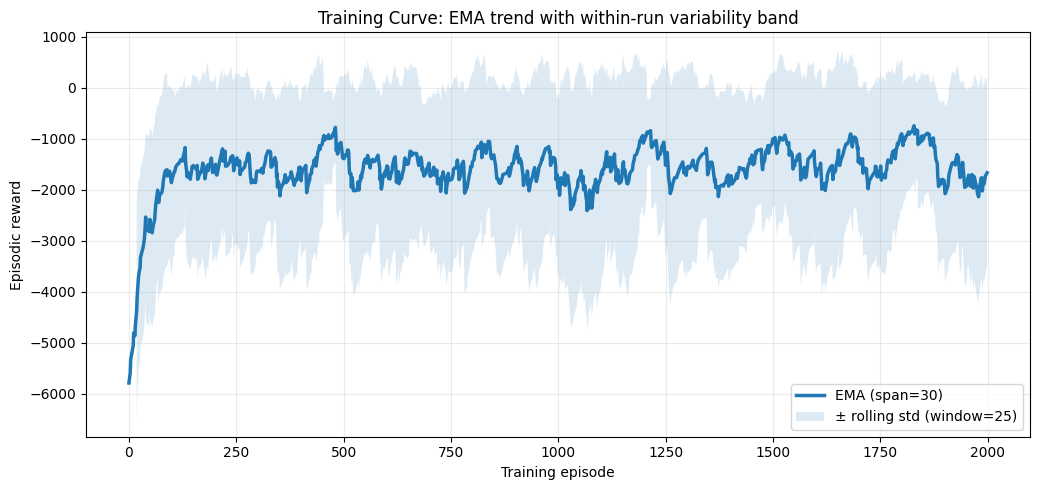

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

csv_path = Path("../../tb_logs/20260121_125953_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18.csv")
df = pd.read_csv(csv_path).copy()

df = df.rename(columns={"Wall time": "wall_time", "Step": "step", "Value": "reward"})
df = df.dropna(subset=["step", "reward"])
df["step"] = pd.to_numeric(df["step"], errors="coerce")
df["reward"] = pd.to_numeric(df["reward"], errors="coerce")
df = df.dropna(subset=["step", "reward"]).sort_values("step").reset_index(drop=True)

use_episode_index = False
x = np.arange(len(df)) if use_episode_index else df["step"].to_numpy()

# --- Optional: clip extreme negative spikes for visualization only
q_low = df["reward"].quantile(0.05)       # bottom 5%
r = df["reward"].clip(lower=q_low)

# --- Trend line: EMA
ema_span = max(10, int(len(df) * 0.03))
ema = r.ewm(span=ema_span, adjust=False).mean()

# --- Variability band: rolling std around the EMA (within-run volatility)
band_w = 25
roll_std = r.rolling(window=band_w, min_periods=max(5, band_w//3)).std()

# Sometimes std can be NaN at the beginning; mask those
valid = ~roll_std.isna()

plt.figure(figsize=(10.5, 5))
#plt.plot(x, r.to_numpy(), linewidth=1, alpha=0.20, label="Raw episodic reward (clipped)")
plt.plot(x, ema.to_numpy(), linewidth=2.5, label=f"EMA (span={ema_span})")

# Shaded band: EMA ± rolling std
plt.fill_between(
    x[valid.to_numpy()],
    (ema[valid] - roll_std[valid]).to_numpy(),
    (ema[valid] + roll_std[valid]).to_numpy(),
    alpha=0.15,
    label=f"± rolling std (window={band_w})"
)

plt.xlabel("Episode" if use_episode_index else "Training episode")
plt.ylabel("Episodic reward")
plt.title("Training Curve: EMA trend with within-run variability band")
plt.grid(True, alpha=0.25)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


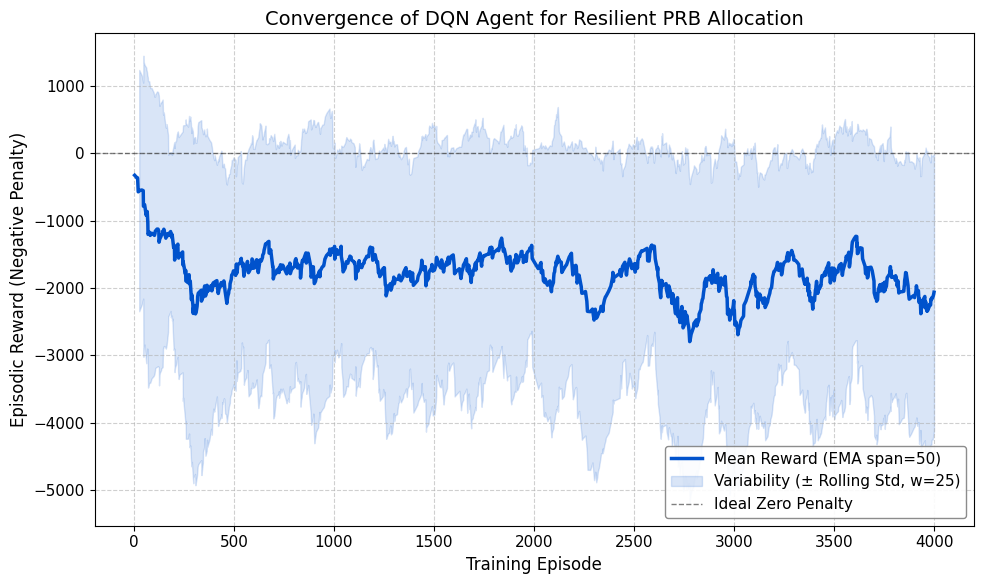

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# --- Load Data ---
#csv_path = Path("../../tb_logs/20260121_125953_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18.csv")

csv_path = Path("../../tb_logs/20260122_212457_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18.csv")
df = pd.read_csv(csv_path).copy()

df = df.rename(columns={"Wall time": "wall_time", "Step": "step", "Value": "reward"})
df = df.dropna(subset=["step", "reward"])
df["step"] = pd.to_numeric(df["step"], errors="coerce")
df["reward"] = pd.to_numeric(df["reward"], errors="coerce")
df = df.dropna(subset=["step", "reward"]).sort_values("step").reset_index(drop=True)

# --- X-Axis Handling ---
# Paper mentions 40,000 episodes[cite: 256]. 
# Ensure 'step' corresponds to what you want to show (Episodes vs Steps).
use_episode_index = False
x = np.arange(len(df)) if use_episode_index else df["step"].to_numpy()

# --- Data Smoothing ---
# 1. Clip extreme outliers (bottom 1%) to remove startup noise while keeping failures visible
q_low = df["reward"].quantile(0.02) 
r = df["reward"].clip(lower=q_low)

# 2. EMA Trend
# Increased span slightly to make the trend clearer for the paper
ema_span = max(10, int(len(df) * 0.05)) 
ema = r.ewm(span=ema_span, adjust=False).mean()

# 3. Variability band (Rolling STD)
band_w = 25
roll_std = r.rolling(window=band_w, min_periods=max(5, band_w//3)).std()
valid = ~roll_std.isna()

# --- Plotting Style for Paper ---
# Setting global font sizes to ensure readability when the image is resized in a PDF
plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 16
})

plt.figure(figsize=(10, 6))

# Main EMA Line (Thicker for visibility)
plt.plot(x, ema.to_numpy(), color='#0052cc', linewidth=2.5, label=f"Mean Reward (EMA span={ema_span})")

# Variability Band (Lighter blue)
plt.fill_between(
    x[valid.to_numpy()],
    (ema[valid] - roll_std[valid]).to_numpy(),
    (ema[valid] + roll_std[valid]).to_numpy(),
    color='#0052cc',
    alpha=0.15,
    label=f"Variability (± Rolling Std, w={band_w})"
)

# Optional: Add a baseline at 0 (Perfect Score)
plt.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.5, label="Ideal Zero Penalty")

# Labels and Title based on your paper context
plt.xlabel("Training Episode")
plt.ylabel("Episodic Reward (Negative Penalty)")
plt.title("Convergence of DQN Agent for Resilient PRB Allocation")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="lower right", frameon=True, framealpha=0.9, edgecolor='gray')
plt.tight_layout()

# Save high-res for paper
plt.savefig("training_convergence.pdf", dpi=300) 
plt.show()

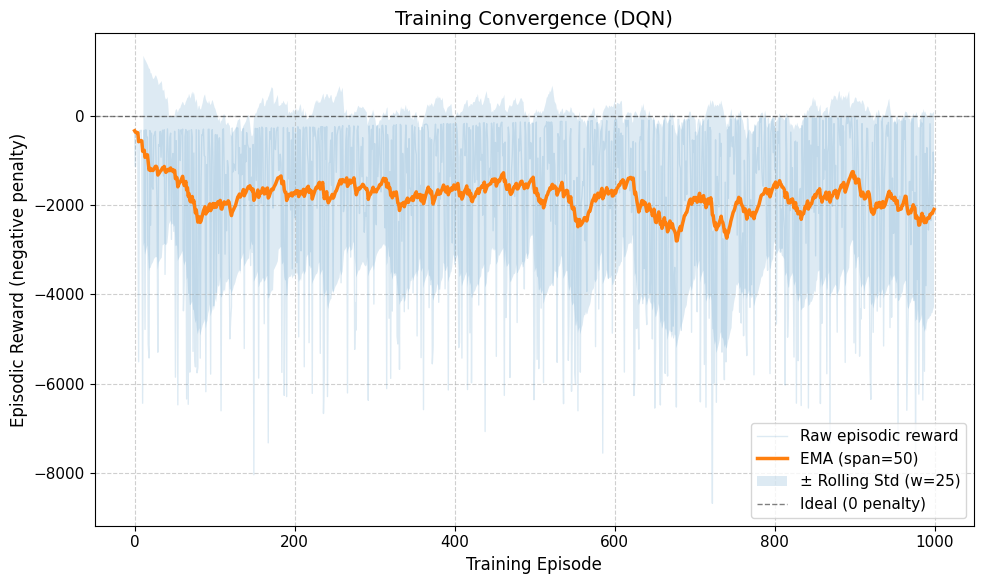

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

csv_path = Path("../../tb_logs/20260122_212457_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18.csv")
df = pd.read_csv(csv_path).copy()

df = df.rename(columns={"Wall time":"wall_time", "Step":"step", "Value":"reward"})
df = df.dropna(subset=["reward"])
df["reward"] = pd.to_numeric(df["reward"], errors="coerce")
df = df.dropna(subset=["reward"]).reset_index(drop=True)

# --- X axis: episode index (safe default) ---
x = np.arange(len(df))

# --- Smooth trend (pick ONE) ---
ema_span = 50
ema = df["reward"].ewm(span=ema_span, adjust=False).mean()

# Variability band: rolling std around RAW reward (not clipped)
band_w = 25
roll_std = df["reward"].rolling(band_w, min_periods=band_w//2).std()

plt.figure(figsize=(10,6))

# Raw (light) + EMA (bold) helps readers trust the trend
plt.plot(x, df["reward"], alpha=0.15, linewidth=1, label="Raw episodic reward")
plt.plot(x, ema, linewidth=2.5, label=f"EMA (span={ema_span})")

valid = roll_std.notna()
plt.fill_between(
    x[valid],
    (ema[valid] - roll_std[valid]),
    (ema[valid] + roll_std[valid]),
    alpha=0.15,
    label=f"± Rolling Std (w={band_w})"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.5, label="Ideal (0 penalty)")

plt.xlabel("Training Episode")
plt.ylabel("Episodic Reward (negative penalty)")
plt.title("Training Convergence (DQN)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()
